In [12]:
# ============================================================
# SECTION 1 - CELL 1
# LOAD CLEANED SIX-CLASS DATASET
# ============================================================

from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import torch

print("=" * 65)
print("ORALSENSE AI - SIX MODEL COMPARISON")
print("=" * 65)

# Find uploaded ZIP
INPUT_ROOT = Path("/kaggle/input")

zip_files = list(
    INPUT_ROOT.rglob("ORALSENSE_CLEANED_DATASET.zip")
)

DATA_DIR = Path("/kaggle/working/oralsense_data")

if zip_files:

    ZIP_PATH = zip_files[0]

    print("\nZIP found:", ZIP_PATH)

    DATA_DIR.mkdir(parents=True, exist_ok=True)

    with ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(DATA_DIR)

else:

    # Kaggle may automatically unpack uploaded archives
    manifests = list(
        INPUT_ROOT.rglob("manifests/train.csv")
    )

    assert manifests, "Cleaned dataset not found!"

    DATA_DIR = manifests[0].parent.parent

print("\nDataset directory:", DATA_DIR)

# Load fixed splits
train_df = pd.read_csv(
    DATA_DIR / "manifests/train.csv"
)

val_df = pd.read_csv(
    DATA_DIR / "manifests/val.csv"
)

test_df = pd.read_csv(
    DATA_DIR / "manifests/test.csv"
)

# Convert relative image paths to absolute paths
for df in [train_df, val_df, test_df]:

    df["image_path"] = df["image_path"].apply(
        lambda p: str(DATA_DIR / p)
    )

    assert df["image_path"].map(
        lambda p: Path(p).is_file()
    ).all(), "Some images are missing!"

# Verify splits
assert len(train_df) == 2096
assert len(val_df) == 450
assert len(test_df) == 485

print("\nDATASET INFORMATION")
print("-" * 65)

print("Training images  :", len(train_df))
print("Validation images:", len(val_df))
print("Testing images   :", len(test_df))

print("\nCLASS DISTRIBUTION")
print("-" * 65)

display(
    train_df["class_name"]
    .value_counts()
    .rename_axis("Disease")
    .reset_index(name="Training Images")
)

print("\nDEVICE INFORMATION")
print("-" * 65)

print(
    "GPU available:",
    torch.cuda.is_available()
)

print("\n✅ CLEANED DATASET LOADED SUCCESSFULLY!")
print("✅ FIXED SPLITS VERIFIED!")
print("\nSECTION 1 - CELL 1 COMPLETED!")

ORALSENSE AI - SIX MODEL COMPARISON

Dataset directory: /kaggle/input/datasets/divyasrimanivannan/oralsense-cleaned-dataset

DATASET INFORMATION
-----------------------------------------------------------------
Training images  : 2096
Validation images: 450
Testing images   : 485

CLASS DISTRIBUTION
-----------------------------------------------------------------


,Disease,Training Images
0,Gingivitis,850
1,Hypodontia,567
2,Calculus,264
3,Mouth Ulcer,166
4,Caries,130
5,Tooth Discoloration,119



DEVICE INFORMATION
-----------------------------------------------------------------
GPU available: True

✅ CLEANED DATASET LOADED SUCCESSFULLY!
✅ FIXED SPLITS VERIFIED!

SECTION 1 - CELL 1 COMPLETED!


In [13]:
# ============================================================
# SECTION 2 - CELL 2
# IMAGE PREPROCESSING AND DATALOADERS
# ============================================================

import random
import numpy as np
import torch
import pandas as pd

from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32

CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth Ulcer",
    "Tooth Discoloration"
]

NUM_CLASSES = len(CLASS_NAMES)

CLASS_TO_IDX = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

IDX_TO_CLASS = {
    idx: name
    for name, idx in CLASS_TO_IDX.items()
}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("ORALSENSE AI - DATA PREPROCESSING")
print("=" * 65)

print("\nDevice:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# 2. ImageNet normalization
# ------------------------------------------------------------

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


# ------------------------------------------------------------
# 3. Training transforms
# ------------------------------------------------------------

train_transform = transforms.Compose([

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=7,
        fill=(127, 127, 127)
    ),

    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=MEAN,
        std=STD
    )

])


# ------------------------------------------------------------
# 4. Validation transforms
# ------------------------------------------------------------

val_transform = transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(
        mean=MEAN,
        std=STD
    )

])


# ------------------------------------------------------------
# 5. Image preparation
# ------------------------------------------------------------

def prepare_image(image):

    image = ImageOps.exif_transpose(image)

    image = image.convert("RGB")

    # Preserve aspect ratio using padding
    image = ImageOps.pad(
        image,
        size=(IMG_SIZE, IMG_SIZE),
        method=Image.Resampling.BICUBIC,
        color=(127, 127, 127)
    )

    return image


# ------------------------------------------------------------
# 6. Custom Dataset
# ------------------------------------------------------------

class OralDiseaseDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe.reset_index(drop=True)

        self.transform = transform

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = row["image_path"]

        with Image.open(image_path) as image:

            image = prepare_image(image)

        if self.transform is not None:

            image = self.transform(image)

        label = CLASS_TO_IDX[row["class_name"]]

        return image, label


# ------------------------------------------------------------
# 7. Initialize datasets
# ------------------------------------------------------------

train_dataset = OralDiseaseDataset(
    train_df,
    transform=train_transform
)

val_dataset = OralDiseaseDataset(
    val_df,
    transform=val_transform
)

# Test split is intentionally NOT loaded
# into a DataLoader during model selection.


# ------------------------------------------------------------
# 8. Initialize DataLoaders
# ------------------------------------------------------------

NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


# ------------------------------------------------------------
# 9. Calculate class weights
# ------------------------------------------------------------

class_counts = (
    train_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES)
    .to_numpy()
)

# Moderate weighting for minority classes
class_weights = np.sqrt(
    class_counts.sum() /
    (NUM_CLASSES * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

print("\nCLASS WEIGHTS")
print("-" * 65)

for name, weight in zip(
    CLASS_NAMES,
    class_weights.cpu().numpy()
):
    print(f"{name:22s}: {weight:.4f}")


# ------------------------------------------------------------
# 10. Verify a training batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("\nBATCH VERIFICATION")
print("-" * 65)

print("Image shape:", images.shape)
print("Label shape:", labels.shape)

print("Image dtype:", images.dtype)

assert images.shape[1:] == (
    3,
    IMG_SIZE,
    IMG_SIZE
)

assert labels.min().item() >= 0
assert labels.max().item() < NUM_CLASSES


# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\nDATALOADER SUMMARY")
print("-" * 65)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("\n" + "=" * 65)
print("SECTION 2 - CELL 2 COMPLETED")
print("=" * 65)

print("✅ Image preprocessing ready")
print("✅ Data augmentation ready")
print("✅ Training DataLoader ready")
print("✅ Validation DataLoader ready")
print("✅ Class weights calculated")
print("✅ GPU configuration ready")

ORALSENSE AI - DATA PREPROCESSING

Device: cuda
GPU: Tesla T4

CLASS WEIGHTS
-----------------------------------------------------------------
Calculus              : 1.1503
Caries                : 1.6393
Gingivitis            : 0.6411
Hypodontia            : 0.7849
Mouth Ulcer           : 1.4507
Tooth Discoloration   : 1.7134

BATCH VERIFICATION
-----------------------------------------------------------------
Image shape: torch.Size([32, 3, 224, 224])
Label shape: torch.Size([32])
Image dtype: torch.float32

DATALOADER SUMMARY
-----------------------------------------------------------------
Training images: 2096
Validation images: 450
Training batches: 66
Validation batches: 15

SECTION 2 - CELL 2 COMPLETED
✅ Image preprocessing ready
✅ Data augmentation ready
✅ Training DataLoader ready
✅ Validation DataLoader ready
✅ Class weights calculated
✅ GPU configuration ready


In [15]:
# ============================================================
# SECTION 3 - CELL 3
# SHARED MODEL TRAINING AND VALIDATION ENGINE
# ============================================================

import copy
import gc
import time
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 1. Output directory
# ------------------------------------------------------------

RESULTS_DIR = Path(
    "/kaggle/working/oralsense_model_results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Evaluation function
# ------------------------------------------------------------

def evaluate_model(model, loader, criterion):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    total_loss = 0.0

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                DEVICE, non_blocking=True
            )

            labels = labels.to(
                DEVICE, non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                enabled=(DEVICE.type == "cuda")
            ):

                outputs = model(images)

                loss = criterion(
                    outputs, labels
                )

            probabilities = torch.softmax(
                outputs.float(), dim=1
            )

            predictions = probabilities.argmax(
                dim=1
            )

            total_loss += (
                loss.item() * images.size(0)
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

    all_probabilities = np.concatenate(
        all_probabilities, axis=0
    )

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    average_loss = (
        total_loss / len(loader.dataset)
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "labels": np.array(all_labels),
        "predictions": np.array(all_predictions),
        "probabilities": all_probabilities
    }


# ------------------------------------------------------------
# 3. Training function
# ------------------------------------------------------------

def train_model(
    model,
    model_name,
    classifier_head,
    epochs=15,
    patience=4,
    backbone_lr=0.00003,
    head_lr=0.0003
):

    print("\n" + "=" * 70)
    print("TRAINING:", model_name)
    print("=" * 70)

    model = model.to(DEVICE)

    # --------------------------------------------------------
    # Class-weighted cross entropy
    # --------------------------------------------------------

    criterion = torch.nn.CrossEntropyLoss(
        weight=class_weights
    )

    # --------------------------------------------------------
    # Separate backbone and classifier parameters
    # --------------------------------------------------------

    head_params = list(
        classifier_head.parameters()
    )

    head_ids = {
        id(p) for p in head_params
    }

    backbone_params = [
        p for p in model.parameters()
        if id(p) not in head_ids
    ]

    # Fine-tune pretrained backbone more gently
    optimizer = torch.optim.AdamW(
        [
            {
                "params": backbone_params,
                "lr": backbone_lr
            },
            {
                "params": head_params,
                "lr": head_lr
            }
        ],
        weight_decay=1e-4
    )

    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="max",
            factor=0.5,
            patience=2
        )
    )

    # Mixed precision for faster GPU training
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(DEVICE.type == "cuda")
    )

    # --------------------------------------------------------
    # Early stopping configuration
    # --------------------------------------------------------

    best_f1 = -1.0
    best_accuracy = -1.0

    best_epoch = 0
    no_improvement = 0

    history = []

    checkpoint_path = (
        RESULTS_DIR /
        f"{model_name}_best.pth"
    )

    start_time = time.time()

    # --------------------------------------------------------
    # Epoch loop
    # --------------------------------------------------------

    for epoch in range(1, epochs + 1):

        model.train()

        running_loss = 0.0
        train_labels = []
        train_predictions = []

        progress = tqdm(
            train_loader,
            desc=f"{model_name} | Epoch {epoch}/{epochs}",
            leave=False
        )

        for images, labels in progress:

            images = images.to(
                DEVICE, non_blocking=True
            )

            labels = labels.to(
                DEVICE, non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type="cuda",
                enabled=(DEVICE.type == "cuda")
            ):

                outputs = model(images)

                loss = criterion(
                    outputs, labels
                )

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)
            scaler.update()

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(dim=1)

            train_labels.extend(
                labels.cpu().numpy()
            )

            train_predictions.extend(
                predictions.detach().cpu().numpy()
            )

        # ----------------------------------------------------
        # Training metrics
        # ----------------------------------------------------

        train_loss = (
            running_loss / len(train_dataset)
        )

        train_acc = accuracy_score(
            train_labels,
            train_predictions
        )

        train_f1 = f1_score(
            train_labels,
            train_predictions,
            labels=list(range(NUM_CLASSES)),
            average="macro",
            zero_division=0
        )

        # ----------------------------------------------------
        # Validation metrics
        # ----------------------------------------------------

        val_results = evaluate_model(
            model,
            val_loader,
            criterion
        )

        val_loss = val_results["loss"]
        val_acc = val_results["accuracy"]
        val_f1 = val_results["macro_f1"]

        scheduler.step(val_f1)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1
        })

        # ----------------------------------------------------
        # Save best model using validation Macro-F1
        # ----------------------------------------------------

        improved = (
            val_f1 > best_f1 + 1e-6
            or (
                abs(val_f1 - best_f1) <= 1e-6
                and val_acc > best_accuracy
            )
        )

        if improved:

            best_f1 = val_f1
            best_accuracy = val_acc
            best_epoch = epoch

            no_improvement = 0

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "model_name": model_name,
                    "epoch": epoch,
                    "val_accuracy": val_acc,
                    "val_macro_f1": val_f1,
                    "class_names": CLASS_NAMES,
                    "image_size": IMG_SIZE
                },
                checkpoint_path
            )

            # Save validation scores for adaptive model
            prediction_df = val_df[
                ["image_path", "class_name",
                 "near_duplicate_group"]
            ].copy().reset_index(drop=True)

            assert np.array_equal(
                prediction_df["class_name"]
                .map(CLASS_TO_IDX)
                .to_numpy(),
                val_results["labels"]
            ), "Validation prediction order mismatch!"

            prediction_df["true_label"] = (
                val_results["labels"]
            )

            prediction_df["predicted_label"] = (
                val_results["predictions"]
            )

            for idx, class_name in enumerate(
                CLASS_NAMES
            ):

                prediction_df[
                    f"prob_{idx}"
                ] = val_results[
                    "probabilities"
                ][:, idx]

            prediction_df.to_csv(
                RESULTS_DIR /
                f"{model_name}_val_predictions.csv",
                index=False
            )

        else:

            no_improvement += 1

        # ----------------------------------------------------
        # Print epoch results
        # ----------------------------------------------------

        print(
            f"Epoch {epoch:02d} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"Best F1: {best_f1:.4f}"
        )

        # ----------------------------------------------------
        # Early stopping
        # ----------------------------------------------------

        if no_improvement >= patience:

            print(
                f"\nEarly stopping at epoch {epoch}"
            )

            break

    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        RESULTS_DIR /
        f"{model_name}_history.csv",
        index=False
    )

    training_time = time.time() - start_time

    # --------------------------------------------------------
    # Final result
    # --------------------------------------------------------

    result = {
        "Model": model_name,
        "Best_Epoch": best_epoch,
        "Val_Accuracy": best_accuracy,
        "Val_Macro_F1": best_f1,
        "Training_Minutes": round(
            training_time / 60, 2
        )
    }

    print("\n" + "=" * 70)
    print(model_name, "- TRAINING COMPLETED")
    print("=" * 70)

    print("Best Epoch       :", best_epoch)
    print("Validation Acc   :", f"{best_accuracy:.4f}")
    print("Validation F1    :", f"{best_f1:.4f}")
    print("Training Minutes :", result["Training_Minutes"])

    print("\nBest model saved to:")
    print(checkpoint_path)

    return result

In [16]:
print("Training function ready:", callable(train_model))
print("Evaluation function ready:", callable(evaluate_model))
print("Results directory:", RESULTS_DIR)

Training function ready: True
Evaluation function ready: True
Results directory: /kaggle/working/oralsense_model_results


In [17]:
# ============================================================
# SECTION 3 - CELL 4
# EFFICIENTNET-B0 TRAINING AND VALIDATION
# ============================================================

import torch
import torch.nn as nn
import pandas as pd
import gc

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

from sklearn.metrics import classification_report

print("=" * 70)
print("MODEL 1 - EFFICIENTNET-B0")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load pretrained EfficientNet-B0
# ------------------------------------------------------------

print("\nLoading ImageNet-pretrained EfficientNet-B0...")

try:
    efficientnet_model = efficientnet_b0(
        weights=EfficientNet_B0_Weights.DEFAULT
    )

except Exception as e:
    raise RuntimeError(
        "Pretrained weights could not be loaded. "
        "Enable Internet in Kaggle Settings or attach "
        "the pretrained weights. Do not use randomly "
        "initialized weights for this comparison."
    ) from e

print("✅ Pretrained EfficientNet-B0 loaded!")

# ------------------------------------------------------------
# 2. Replace classification head
# ------------------------------------------------------------

in_features = (
    efficientnet_model.classifier[1].in_features
)

efficientnet_model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES
)

print("\nClassification head replaced!")

print("Input features :", in_features)
print("Output classes :", NUM_CLASSES)

# ------------------------------------------------------------
# 3. Model information
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in efficientnet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in efficientnet_model.parameters()
    if p.requires_grad
)

print("\nMODEL INFORMATION")
print("-" * 70)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

print("Device:", DEVICE)

# ------------------------------------------------------------
# 4. Train and validate EfficientNet-B0
# ------------------------------------------------------------

efficientnet_result = train_model(
    model=efficientnet_model,
    model_name="EfficientNetB0",
    classifier_head=efficientnet_model.classifier,

    epochs=12,
    patience=3,

    backbone_lr=3e-5,
    head_lr=3e-4
)

# ------------------------------------------------------------
# 5. Display best validation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EFFICIENTNET-B0 - BEST VALIDATION RESULTS")
print("=" * 70)

display(
    pd.DataFrame([efficientnet_result])
)

# ------------------------------------------------------------
# 6. Per-class validation performance
# ------------------------------------------------------------

prediction_path = (
    RESULTS_DIR / "EfficientNetB0_val_predictions.csv"
)

predictions_df = pd.read_csv(prediction_path)

print("\nPER-CLASS VALIDATION PERFORMANCE")
print("-" * 70)

print(
    classification_report(
        predictions_df["true_label"],
        predictions_df["predicted_label"],
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 7. Save model comparison results
# ------------------------------------------------------------

comparison_path = (
    RESULTS_DIR / "model_comparison.csv"
)

comparison_df = pd.DataFrame(
    [efficientnet_result]
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\n" + "=" * 70)
print("MODEL 1 COMPLETED")
print("=" * 70)

print("✅ Best EfficientNet-B0 checkpoint saved")
print("✅ Training history saved")
print("✅ Validation predictions saved")
print("✅ Per-class performance calculated")

print("\nIMPORTANT: Test dataset was not evaluated.")

# ------------------------------------------------------------
# 8. Free GPU memory
# ------------------------------------------------------------

del efficientnet_model
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n✅ GPU memory cleared for next model!")

MODEL 1 - EFFICIENTNET-B0

Loading ImageNet-pretrained EfficientNet-B0...
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 215MB/s]

✅ Pretrained EfficientNet-B0 loaded!

Classification head replaced!
Input features : 1280
Output classes : 6

MODEL INFORMATION
----------------------------------------------------------------------
Total parameters     : 4,015,234
Trainable parameters : 4,015,234
Device: cuda

TRAINING: EfficientNetB0


EfficientNetB0 | Epoch 1/12:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 01 | Train Acc: 0.5587 | Val Acc: 0.6733 | Val F1: 0.4959 | Best F1: 0.4959


...

Epoch 11 | Train Acc: 0.9814 | Val Acc: 0.9311 | Val F1: 0.8851 | Best F1: 0.8851


EfficientNetB0 | Epoch 12/12:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 12 | Train Acc: 0.9847 | Val Acc: 0.9400 | Val F1: 0.8940 | Best F1: 0.8940

EfficientNetB0 - TRAINING COMPLETED
Best Epoch       : 12
Validation Acc   : 0.9400
Validation F1    : 0.8940
Training Minutes : 2.72

Best model saved to:
/kaggle/working/oralsense_model_results/EfficientNetB0_best.pth

EFFICIENTNET-B0 - BEST VALIDATION RESULTS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,EfficientNetB0,12,0.94,0.893996,2.72



PER-CLASS VALIDATION PERFORMANCE
----------------------------------------------------------------------
                     precision    recall  f1-score   support

           Calculus     0.9677    0.9524    0.9600        63
             Caries     0.7826    0.6667    0.7200        27
         Gingivitis     0.9467    0.9581    0.9524       167
         Hypodontia     0.9771    0.9846    0.9808       130
        Mouth Ulcer     0.9730    0.9730    0.9730        37
Tooth Discoloration     0.7500    0.8077    0.7778        26

           accuracy                         0.9400       450
          macro avg     0.8995    0.8904    0.8940       450
       weighted avg     0.9394    0.9400    0.9393       450


MODEL 1 COMPLETED
✅ Best EfficientNet-B0 checkpoint saved
✅ Training history saved
✅ Validation predictions saved
✅ Per-class performance calculated

IMPORTANT: Test dataset was not evaluated.

✅ GPU memory cleared for next model!


In [18]:
# ============================================================
# SECTION 3 - CELL 5
# MODEL 2 - RESNET50 TRAINING AND VALIDATION
# ============================================================

import torch
import torch.nn as nn
import pandas as pd
import gc

from torch.utils.data import DataLoader
from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

from sklearn.metrics import classification_report

print("=" * 70)
print("MODEL 2 - RESNET50")
print("=" * 70)

# ------------------------------------------------------------
# 1. Fix DataLoader multiprocessing warnings
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("\n✅ DataLoaders configured with num_workers=0")

# ------------------------------------------------------------
# 2. Load pretrained ResNet50
# ------------------------------------------------------------

print("\nLoading ImageNet-pretrained ResNet50...")

resnet_model = resnet50(
    weights=ResNet50_Weights.DEFAULT
)

print("✅ Pretrained ResNet50 loaded!")

# ------------------------------------------------------------
# 3. Replace classification head
# ------------------------------------------------------------

in_features = resnet_model.fc.in_features

resnet_model.fc = nn.Linear(
    in_features,
    NUM_CLASSES
)

print("\nClassification head replaced!")
print("Input features :", in_features)
print("Output classes :", NUM_CLASSES)

# ------------------------------------------------------------
# 4. Model information
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in resnet_model.parameters()
)

print("\nMODEL INFORMATION")
print("-" * 70)

print(f"Total parameters: {total_params:,}")
print("Device:", DEVICE)

# ------------------------------------------------------------
# 5. Train ResNet50
# ------------------------------------------------------------

resnet_result = train_model(
    model=resnet_model,
    model_name="ResNet50",
    classifier_head=resnet_model.fc,
    epochs=12,
    patience=3,
    backbone_lr=3e-5,
    head_lr=3e-4
)

# ------------------------------------------------------------
# 6. Display best validation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESNET50 - BEST VALIDATION RESULTS")
print("=" * 70)

display(pd.DataFrame([resnet_result]))

# ------------------------------------------------------------
# 7. Per-class validation performance
# ------------------------------------------------------------

prediction_path = (
    RESULTS_DIR / "ResNet50_val_predictions.csv"
)

predictions_df = pd.read_csv(prediction_path)

print("\nPER-CLASS VALIDATION PERFORMANCE")
print("-" * 70)

print(
    classification_report(
        predictions_df["true_label"],
        predictions_df["predicted_label"],
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 8. Update model comparison table
# ------------------------------------------------------------

comparison_path = (
    RESULTS_DIR / "model_comparison.csv"
)

if comparison_path.exists():

    comparison_df = pd.read_csv(comparison_path)

else:

    comparison_df = pd.DataFrame()

comparison_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([resnet_result])
    ],
    ignore_index=True
)

comparison_df = comparison_df.drop_duplicates(
    subset="Model",
    keep="last"
)

comparison_df = comparison_df.sort_values(
    "Val_Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\n" + "=" * 70)
print("MODEL COMPARISON - CURRENT RESULTS")
print("=" * 70)

display(comparison_df)

# ------------------------------------------------------------
# 9. Free GPU memory
# ------------------------------------------------------------

del resnet_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n✅ ResNet50 training completed!")
print("✅ Best checkpoint saved!")
print("✅ Validation predictions saved!")
print("✅ Model comparison updated!")
print("✅ GPU memory cleared!")

print("\nIMPORTANT: Test dataset remains untouched.")

MODEL 2 - RESNET50

✅ DataLoaders configured with num_workers=0

Loading ImageNet-pretrained ResNet50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 205MB/s]


✅ Pretrained ResNet50 loaded!

Classification head replaced!
Input features : 2048
Output classes : 6

MODEL INFORMATION
----------------------------------------------------------------------
Total parameters: 23,520,326
Device: cuda

TRAINING: ResNet50


ResNet50 | Epoch 1/12:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 01 | Train Acc: 0.5868 | Val Acc: 0.7200 | Val F1: 0.5272 | Best F1: 0.5272


...

Epoch 12 | Train Acc: 0.9962 | Val Acc: 0.9311 | Val F1: 0.8721 | Best F1: 0.8892

ResNet50 - TRAINING COMPLETED
Best Epoch       : 11
Validation Acc   : 0.9356
Validation F1    : 0.8892
Training Minutes : 5.47

Best model saved to:
/kaggle/working/oralsense_model_results/ResNet50_best.pth

RESNET50 - BEST VALIDATION RESULTS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,ResNet50,11,0.935556,0.889199,5.47



PER-CLASS VALIDATION PERFORMANCE
----------------------------------------------------------------------
                     precision    recall  f1-score   support

           Calculus     0.9516    0.9365    0.9440        63
             Caries     0.7200    0.6667    0.6923        27
         Gingivitis     0.9364    0.9701    0.9529       167
         Hypodontia     0.9767    0.9692    0.9730       130
        Mouth Ulcer     0.9730    0.9730    0.9730        37
Tooth Discoloration     0.8333    0.7692    0.8000        26

           accuracy                         0.9356       450
          macro avg     0.8985    0.8808    0.8892       450
       weighted avg     0.9343    0.9356    0.9346       450


MODEL COMPARISON - CURRENT RESULTS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,EfficientNetB0,12,0.940000,0.893996,2.72
1,ResNet50,11,0.935556,0.889199,5.47



✅ ResNet50 training completed!
✅ Best checkpoint saved!
✅ Validation predictions saved!
✅ Model comparison updated!
✅ GPU memory cleared!

IMPORTANT: Test dataset remains untouched.


In [19]:
# ============================================================
# SECTION 3 - CELL 6
# MODEL 3 - DENSENET121 TRAINING AND VALIDATION
# ============================================================

import torch
import torch.nn as nn
import pandas as pd
import gc

from torchvision.models import (
    densenet121,
    DenseNet121_Weights
)

from sklearn.metrics import classification_report

print("=" * 70)
print("MODEL 3 - DENSENET121")
print("=" * 70)


# ------------------------------------------------------------
# 1. Load ImageNet-pretrained DenseNet121
# ------------------------------------------------------------

print("\nLoading ImageNet-pretrained DenseNet121...")

try:
    densenet_model = densenet121(
        weights=DenseNet121_Weights.DEFAULT
    )

except Exception as e:
    raise RuntimeError(
        "Could not load pretrained DenseNet121 weights. "
        "Check Kaggle Internet access."
    ) from e

print("✅ Pretrained DenseNet121 loaded!")


# ------------------------------------------------------------
# 2. Replace classification head
# ------------------------------------------------------------

in_features = densenet_model.classifier.in_features

densenet_model.classifier = nn.Linear(
    in_features,
    NUM_CLASSES
)

print("\nClassification head replaced!")
print("Input features :", in_features)
print("Output classes :", NUM_CLASSES)


# ------------------------------------------------------------
# 3. Model information
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in densenet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in densenet_model.parameters()
    if p.requires_grad
)

print("\nMODEL INFORMATION")
print("-" * 70)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print("Device:", DEVICE)


# ------------------------------------------------------------
# 4. Train DenseNet121
# ------------------------------------------------------------

densenet_result = train_model(
    model=densenet_model,
    model_name="DenseNet121",
    classifier_head=densenet_model.classifier,

    epochs=12,
    patience=3,

    backbone_lr=3e-5,
    head_lr=3e-4
)


# ------------------------------------------------------------
# 5. Display best validation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DENSENET121 - BEST VALIDATION RESULTS")
print("=" * 70)

display(
    pd.DataFrame([densenet_result])
)


# ------------------------------------------------------------
# 6. Per-class validation performance
# ------------------------------------------------------------

prediction_path = (
    RESULTS_DIR /
    "DenseNet121_val_predictions.csv"
)

predictions_df = pd.read_csv(prediction_path)

print("\nPER-CLASS VALIDATION PERFORMANCE")
print("-" * 70)

print(
    classification_report(
        predictions_df["true_label"],
        predictions_df["predicted_label"],
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 7. Update model comparison
# ------------------------------------------------------------

comparison_path = (
    RESULTS_DIR / "model_comparison.csv"
)

if comparison_path.exists():

    comparison_df = pd.read_csv(comparison_path)

else:

    comparison_df = pd.DataFrame()

comparison_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([densenet_result])
    ],
    ignore_index=True
)

comparison_df = comparison_df.drop_duplicates(
    subset="Model",
    keep="last"
)

comparison_df = comparison_df.sort_values(
    "Val_Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison_df.to_csv(
    comparison_path,
    index=False
)


# ------------------------------------------------------------
# 8. Display updated comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL COMPARISON - CURRENT RESULTS")
print("=" * 70)

display(comparison_df)


# ------------------------------------------------------------
# 9. Free GPU memory
# ------------------------------------------------------------

del densenet_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("MODEL 3 COMPLETED")
print("=" * 70)

print("✅ DenseNet121 checkpoint saved")
print("✅ Training history saved")
print("✅ Validation predictions saved")
print("✅ Model comparison updated")
print("✅ GPU memory cleared")

print("\nIMPORTANT: Test dataset remains untouched.")

MODEL 3 - DENSENET121

Loading ImageNet-pretrained DenseNet121...
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 152MB/s]


✅ Pretrained DenseNet121 loaded!

Classification head replaced!
Input features : 1024
Output classes : 6

MODEL INFORMATION
----------------------------------------------------------------------
Total parameters     : 6,960,006
Trainable parameters : 6,960,006
Device: cuda

TRAINING: DenseNet121


DenseNet121 | Epoch 1/12:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 01 | Train Acc: 0.6102 | Val Acc: 0.7267 | Val F1: 0.5908 | Best F1: 0.5908


...

Epoch 10 | Train Acc: 0.9971 | Val Acc: 0.9267 | Val F1: 0.8710 | Best F1: 0.8905

Early stopping at epoch 10

DenseNet121 - TRAINING COMPLETED
Best Epoch       : 7
Validation Acc   : 0.9400
Validation F1    : 0.8905
Training Minutes : 4.97

Best model saved to:
/kaggle/working/oralsense_model_results/DenseNet121_best.pth

DENSENET121 - BEST VALIDATION RESULTS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,DenseNet121,7,0.94,0.890476,4.97



PER-CLASS VALIDATION PERFORMANCE
----------------------------------------------------------------------
                     precision    recall  f1-score   support

           Calculus     0.9385    0.9683    0.9531        63
             Caries     0.7037    0.7037    0.7037        27
         Gingivitis     0.9583    0.9641    0.9612       167
         Hypodontia     0.9697    0.9846    0.9771       130
        Mouth Ulcer     1.0000    0.9459    0.9722        37
Tooth Discoloration     0.8261    0.7308    0.7755        26

           accuracy                         0.9400       450
          macro avg     0.8994    0.8829    0.8905       450
       weighted avg     0.9393    0.9400    0.9394       450


MODEL COMPARISON - CURRENT RESULTS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,EfficientNetB0,12,0.940000,0.893996,2.72
1,DenseNet121,7,0.940000,0.890476,4.97
2,ResNet50,11,0.935556,0.889199,5.47



MODEL 3 COMPLETED
✅ DenseNet121 checkpoint saved
✅ Training history saved
✅ Validation predictions saved
✅ Model comparison updated
✅ GPU memory cleared

IMPORTANT: Test dataset remains untouched.


In [20]:
# ============================================================
# SECTION 3 - CELL 7
# MODEL 4 - MOBILENETV3-LARGE TRAINING
# ============================================================

import torch
import torch.nn as nn
import pandas as pd
import gc

from torchvision.models import (
    mobilenet_v3_large,
    MobileNet_V3_Large_Weights
)

from sklearn.metrics import classification_report

print("=" * 70)
print("MODEL 4 - MOBILENETV3-LARGE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Load pretrained MobileNetV3-Large
# ------------------------------------------------------------

print("\nLoading ImageNet-pretrained MobileNetV3-Large...")

try:

    mobilenet_model = mobilenet_v3_large(
        weights=MobileNet_V3_Large_Weights.DEFAULT
    )

except Exception as e:

    raise RuntimeError(
        "Pretrained MobileNetV3 weights could not be loaded. "
        "Check Kaggle Internet access."
    ) from e

print("✅ Pretrained MobileNetV3-Large loaded!")


# ------------------------------------------------------------
# 2. Replace classification head
# ------------------------------------------------------------

in_features = mobilenet_model.classifier[3].in_features

mobilenet_model.classifier[3] = nn.Linear(
    in_features,
    NUM_CLASSES
)

print("\nClassification head replaced!")
print("Input features :", in_features)
print("Output classes :", NUM_CLASSES)


# ------------------------------------------------------------
# 3. Model information
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in mobilenet_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in mobilenet_model.parameters()
    if p.requires_grad
)

print("\nMODEL INFORMATION")
print("-" * 70)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print("Device:", DEVICE)


# ------------------------------------------------------------
# 4. Train MobileNetV3-Large
# ------------------------------------------------------------

mobilenet_result = train_model(
    model=mobilenet_model,
    model_name="MobileNetV3Large",
    classifier_head=mobilenet_model.classifier,

    epochs=12,
    patience=3,

    backbone_lr=3e-5,
    head_lr=3e-4
)


# ------------------------------------------------------------
# 5. Display best validation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MOBILENETV3-LARGE - BEST VALIDATION RESULTS")
print("=" * 70)

display(
    pd.DataFrame([mobilenet_result])
)


# ------------------------------------------------------------
# 6. Per-class validation performance
# ------------------------------------------------------------

prediction_path = (
    RESULTS_DIR /
    "MobileNetV3Large_val_predictions.csv"
)

predictions_df = pd.read_csv(prediction_path)

print("\nPER-CLASS VALIDATION PERFORMANCE")
print("-" * 70)

print(
    classification_report(
        predictions_df["true_label"],
        predictions_df["predicted_label"],
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 7. Update model comparison CSV
# ------------------------------------------------------------

comparison_path = (
    RESULTS_DIR / "model_comparison.csv"
)

if comparison_path.exists():

    comparison_df = pd.read_csv(comparison_path)

else:

    comparison_df = pd.DataFrame()

comparison_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([mobilenet_result])
    ],
    ignore_index=True
)

comparison_df = comparison_df.drop_duplicates(
    subset="Model",
    keep="last"
)

comparison_df = comparison_df.sort_values(
    "Val_Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison_df.to_csv(
    comparison_path,
    index=False
)


# ------------------------------------------------------------
# 8. Display current comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL COMPARISON - 4 MODELS")
print("=" * 70)

display(comparison_df)


# ------------------------------------------------------------
# 9. Free GPU memory
# ------------------------------------------------------------

del mobilenet_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("MODEL 4 COMPLETED")
print("=" * 70)

print("✅ MobileNetV3-Large checkpoint saved")
print("✅ Training history saved")
print("✅ Validation predictions saved")
print("✅ Model comparison updated")
print("✅ GPU memory cleared")

print("\nIMPORTANT: Test dataset remains untouched.")

MODEL 4 - MOBILENETV3-LARGE

Loading ImageNet-pretrained MobileNetV3-Large...
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 172MB/s]

✅ Pretrained MobileNetV3-Large loaded!

Classification head replaced!
Input features : 1280
Output classes : 6

MODEL INFORMATION
----------------------------------------------------------------------
Total parameters     : 4,209,718
Trainable parameters : 4,209,718
Device: cuda

TRAINING: MobileNetV3Large


MobileNetV3Large | Epoch 1/12:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 01 | Train Acc: 0.6302 | Val Acc: 0.6844 | Val F1: 0.5282 | Best F1: 0.5282


...

Epoch 12 | Train Acc: 0.9928 | Val Acc: 0.9156 | Val F1: 0.8570 | Best F1: 0.8823

MobileNetV3Large - TRAINING COMPLETED
Best Epoch       : 11
Validation Acc   : 0.9244
Validation F1    : 0.8823
Training Minutes : 4.91

Best model saved to:
/kaggle/working/oralsense_model_results/MobileNetV3Large_best.pth

MOBILENETV3-LARGE - BEST VALIDATION RESULTS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,MobileNetV3Large,11,0.924444,0.882266,4.91



PER-CLASS VALIDATION PERFORMANCE
----------------------------------------------------------------------
                     precision    recall  f1-score   support

           Calculus     0.9344    0.9048    0.9194        63
             Caries     0.8182    0.6667    0.7347        27
         Gingivitis     0.9034    0.9521    0.9271       167
         Hypodontia     0.9769    0.9769    0.9769       130
        Mouth Ulcer     0.9474    0.9730    0.9600        37
Tooth Discoloration     0.8261    0.7308    0.7755        26

           accuracy                         0.9244       450
          macro avg     0.9011    0.8674    0.8823       450
       weighted avg     0.9230    0.9244    0.9228       450


MODEL COMPARISON - 4 MODELS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,EfficientNetB0,12,0.940000,0.893996,2.72
1,DenseNet121,7,0.940000,0.890476,4.97
2,ResNet50,11,0.935556,0.889199,5.47
3,MobileNetV3Large,11,0.924444,0.882266,4.91



MODEL 4 COMPLETED
✅ MobileNetV3-Large checkpoint saved
✅ Training history saved
✅ Validation predictions saved
✅ Model comparison updated
✅ GPU memory cleared

IMPORTANT: Test dataset remains untouched.


In [21]:
# ============================================================
# SECTION 3 - CELL 8
# MODEL 5 - CONVNEXT-TINY TRAINING AND VALIDATION
# ============================================================

import torch
import torch.nn as nn
import pandas as pd
import gc

from torch.utils.data import DataLoader

from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

from sklearn.metrics import classification_report

print("=" * 70)
print("MODEL 5 - CONVNEXT-TINY")
print("=" * 70)


# ------------------------------------------------------------
# 1. Clear unused GPU memory
# ------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 2. Configure batch size for ConvNeXt
# ------------------------------------------------------------

CONVNEXT_BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=CONVNEXT_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONVNEXT_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("\nDATALOADER CONFIGURATION")
print("-" * 70)

print("Batch size       :", CONVNEXT_BATCH_SIZE)
print("Training batches :", len(train_loader))
print("Validation batches:", len(val_loader))
print("Device           :", DEVICE)


# ------------------------------------------------------------
# 3. Load ImageNet-pretrained ConvNeXt-Tiny
# ------------------------------------------------------------

print("\nLoading ImageNet-pretrained ConvNeXt-Tiny...")

try:

    convnext_model = convnext_tiny(
        weights=ConvNeXt_Tiny_Weights.DEFAULT
    )

except Exception as e:

    raise RuntimeError(
        "Could not load ImageNet-pretrained ConvNeXt-Tiny. "
        "Check Kaggle Internet access."
    ) from e

print("✅ Pretrained ConvNeXt-Tiny loaded!")


# ------------------------------------------------------------
# 4. Replace classification head
# ------------------------------------------------------------

in_features = (
    convnext_model.classifier[2].in_features
)

convnext_model.classifier[2] = nn.Linear(
    in_features,
    NUM_CLASSES
)

print("\nClassification head replaced!")

print("Input features :", in_features)
print("Output classes :", NUM_CLASSES)


# ------------------------------------------------------------
# 5. Model information
# ------------------------------------------------------------

total_params = sum(
    p.numel()
    for p in convnext_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in convnext_model.parameters()
    if p.requires_grad
)

print("\nMODEL INFORMATION")
print("-" * 70)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print("Device:", DEVICE)


# ------------------------------------------------------------
# 6. Train ConvNeXt-Tiny
# ------------------------------------------------------------

convnext_result = train_model(
    model=convnext_model,
    model_name="ConvNeXtTiny",
    classifier_head=convnext_model.classifier[2],

    epochs=12,
    patience=3,

    backbone_lr=3e-5,
    head_lr=3e-4
)


# ------------------------------------------------------------
# 7. Display validation results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CONVNEXT-TINY - BEST VALIDATION RESULTS")
print("=" * 70)

display(
    pd.DataFrame([convnext_result])
)


# ------------------------------------------------------------
# 8. Per-class classification report
# ------------------------------------------------------------

prediction_path = (
    RESULTS_DIR /
    "ConvNeXtTiny_val_predictions.csv"
)

predictions_df = pd.read_csv(
    prediction_path
)

print("\nPER-CLASS VALIDATION PERFORMANCE")
print("-" * 70)

print(
    classification_report(
        predictions_df["true_label"],
        predictions_df["predicted_label"],
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 9. Update model comparison
# ------------------------------------------------------------

comparison_path = (
    RESULTS_DIR / "model_comparison.csv"
)

if comparison_path.exists():

    comparison_df = pd.read_csv(
        comparison_path
    )

else:

    comparison_df = pd.DataFrame()

comparison_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([convnext_result])
    ],
    ignore_index=True
)

comparison_df = comparison_df.drop_duplicates(
    subset="Model",
    keep="last"
)

comparison_df = comparison_df.sort_values(
    "Val_Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison_df.to_csv(
    comparison_path,
    index=False
)


# ------------------------------------------------------------
# 10. Display updated comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL COMPARISON - 5 MODELS")
print("=" * 70)

display(comparison_df)


# ------------------------------------------------------------
# 11. Free GPU memory
# ------------------------------------------------------------

del convnext_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("MODEL 5 COMPLETED")
print("=" * 70)

print("✅ ConvNeXt-Tiny checkpoint saved")
print("✅ Training history saved")
print("✅ Validation predictions saved")
print("✅ Model comparison updated")
print("✅ GPU memory cleared")

print("\nIMPORTANT: Test dataset remains untouched.")

MODEL 5 - CONVNEXT-TINY

DATALOADER CONFIGURATION
----------------------------------------------------------------------
Batch size       : 16
Training batches : 131
Validation batches: 29
Device           : cuda

Loading ImageNet-pretrained ConvNeXt-Tiny...
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 213MB/s] 


✅ Pretrained ConvNeXt-Tiny loaded!

Classification head replaced!
Input features : 768
Output classes : 6

MODEL INFORMATION
----------------------------------------------------------------------
Total parameters     : 27,824,742
Trainable parameters : 27,824,742
Device: cuda

TRAINING: ConvNeXtTiny


ConvNeXtTiny | Epoch 1/12:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch 01 | Train Acc: 0.7199 | Val Acc: 0.8311 | Val F1: 0.7535 | Best F1: 0.7535


...

Epoch 07 | Train Acc: 0.9986 | Val Acc: 0.9444 | Val F1: 0.8983 | Best F1: 0.9119

Early stopping at epoch 7

ConvNeXtTiny - TRAINING COMPLETED
Best Epoch       : 4
Validation Acc   : 0.9511
Validation F1    : 0.9119
Training Minutes : 3.57

Best model saved to:
/kaggle/working/oralsense_model_results/ConvNeXtTiny_best.pth

CONVNEXT-TINY - BEST VALIDATION RESULTS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,ConvNeXtTiny,4,0.951111,0.911869,3.57



PER-CLASS VALIDATION PERFORMANCE
----------------------------------------------------------------------
                     precision    recall  f1-score   support

           Calculus     0.9531    0.9683    0.9606        63
             Caries     0.7241    0.7778    0.7500        27
         Gingivitis     0.9701    0.9701    0.9701       167
         Hypodontia     0.9845    0.9769    0.9807       130
        Mouth Ulcer     1.0000    0.9730    0.9863        37
Tooth Discoloration     0.8400    0.8077    0.8235        26

           accuracy                         0.9511       450
          macro avg     0.9120    0.9123    0.9119       450
       weighted avg     0.9521    0.9511    0.9515       450


MODEL COMPARISON - 5 MODELS


,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,ConvNeXtTiny,4,0.951111,0.911869,3.57
1,EfficientNetB0,12,0.940000,0.893996,2.72
2,DenseNet121,7,0.940000,0.890476,4.97
3,ResNet50,11,0.935556,0.889199,5.47
4,MobileNetV3Large,11,0.924444,0.882266,4.91



MODEL 5 COMPLETED
✅ ConvNeXt-Tiny checkpoint saved
✅ Training history saved
✅ Validation predictions saved
✅ Model comparison updated
✅ GPU memory cleared

IMPORTANT: Test dataset remains untouched.


In [22]:
# ============================================================
# SECTION 3 - CELL 9
# MODEL 6 - DINOV2 FEATURE EXTRACTION
# ============================================================

import torch
import numpy as np
import pandas as pd
import gc
import time

from pathlib import Path
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

print("=" * 70)
print("MODEL 6 - DINOV2 ViT-S/14 FEATURE EXTRACTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

DINO_BATCH_SIZE = 16

FEATURE_PATH = (
    RESULTS_DIR / "DINOv2_features.npz"
)

print("\nDevice:", DEVICE)
print("Batch size:", DINO_BATCH_SIZE)


# ------------------------------------------------------------
# 2. Create deterministic datasets
# ------------------------------------------------------------

# IMPORTANT:
# No random augmentation and no shuffling.
# Feature order must match the original CSV manifests.

dino_train_dataset = OralDiseaseDataset(
    train_df,
    transform=val_transform
)

dino_val_dataset = OralDiseaseDataset(
    val_df,
    transform=val_transform
)

dino_train_loader = DataLoader(
    dino_train_dataset,
    batch_size=DINO_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

dino_val_loader = DataLoader(
    dino_val_dataset,
    batch_size=DINO_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("\nDATASET INFORMATION")
print("-" * 70)

print("Training images:", len(dino_train_dataset))
print("Validation images:", len(dino_val_dataset))


# ------------------------------------------------------------
# 3. Load pretrained DINOv2 ViT-S/14
# ------------------------------------------------------------

print("\nLoading pretrained DINOv2 ViT-S/14...")

try:

    dinov2_model = torch.hub.load(
        "facebookresearch/dinov2",
        "dinov2_vits14",
        trust_repo=True,
        skip_validation=True
    )

except Exception as e:

    raise RuntimeError(
        "DINOv2 pretrained weights could not be loaded. "
        "Check Kaggle Internet access and share the error."
    ) from e

dinov2_model = dinov2_model.to(DEVICE)

dinov2_model.eval()

# Freeze every parameter
for parameter in dinov2_model.parameters():
    parameter.requires_grad = False

print("✅ Pretrained DINOv2 loaded!")
print("✅ Feature extractor frozen!")


# ------------------------------------------------------------
# 4. Feature extraction function
# ------------------------------------------------------------

def extract_dino_features(model, loader, description):

    all_features = []
    all_labels = []

    model.eval()

    with torch.inference_mode():

        for images, labels in tqdm(
            loader,
            desc=description
        ):

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            # DINOv2 returns image-level embeddings
            features = model(images)

            features = features.float()

            all_features.append(
                features.cpu().numpy()
            )

            all_labels.append(
                labels.numpy()
            )

    X = np.concatenate(
        all_features,
        axis=0
    )

    y = np.concatenate(
        all_labels,
        axis=0
    )

    return X, y


# ------------------------------------------------------------
# 5. Extract training features
# ------------------------------------------------------------

start_time = time.time()

print("\nExtracting training features...")

X_train_dino, y_train_dino = extract_dino_features(
    dinov2_model,
    dino_train_loader,
    "DINOv2 Training"
)


# ------------------------------------------------------------
# 6. Extract validation features
# ------------------------------------------------------------

print("\nExtracting validation features...")

X_val_dino, y_val_dino = extract_dino_features(
    dinov2_model,
    dino_val_loader,
    "DINOv2 Validation"
)


# ------------------------------------------------------------
# 7. Verify feature dimensions and label order
# ------------------------------------------------------------

assert X_train_dino.shape == (
    len(train_df), 384
)

assert X_val_dino.shape == (
    len(val_df), 384
)

assert np.isfinite(X_train_dino).all()
assert np.isfinite(X_val_dino).all()

assert np.array_equal(
    y_train_dino,
    train_df["class_name"]
    .map(CLASS_TO_IDX)
    .to_numpy()
)

assert np.array_equal(
    y_val_dino,
    val_df["class_name"]
    .map(CLASS_TO_IDX)
    .to_numpy()
)

print("\nFEATURE VERIFICATION")
print("-" * 70)

print("Training features:", X_train_dino.shape)
print("Validation features:", X_val_dino.shape)

print("Training labels:", y_train_dino.shape)
print("Validation labels:", y_val_dino.shape)


# ------------------------------------------------------------
# 8. Preserve near-duplicate group information
# ------------------------------------------------------------

train_groups = (
    train_df["near_duplicate_group"]
    .astype(str)
    .to_numpy()
)


# ------------------------------------------------------------
# 9. Save features
# ------------------------------------------------------------

np.savez_compressed(
    FEATURE_PATH,

    X_train=X_train_dino,
    y_train=y_train_dino,

    X_val=X_val_dino,
    y_val=y_val_dino,

    train_groups=train_groups
)

elapsed_minutes = (
    time.time() - start_time
) / 60

print("\nFEATURE EXTRACTION COMPLETED")
print("-" * 70)

print("Time (minutes):", round(elapsed_minutes, 2))
print("Saved to:", FEATURE_PATH)

print(
    "File size (MB):",
    round(
        FEATURE_PATH.stat().st_size / (1024 ** 2),
        2
    )
)


# ------------------------------------------------------------
# 10. Free GPU memory
# ------------------------------------------------------------

del dinov2_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("CELL 9 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("✅ DINOv2 pretrained model loaded")
print("✅ Training features extracted")
print("✅ Validation features extracted")
print("✅ 384-dimensional embeddings verified")
print("✅ Features saved")
print("✅ GPU memory cleared")

print("\nIMPORTANT: Test dataset remains untouched.")

MODEL 6 - DINOV2 ViT-S/14 FEATURE EXTRACTION

Device: cuda
Batch size: 16

DATASET INFORMATION
----------------------------------------------------------------------
Training images: 2096
Validation images: 450

Loading pretrained DINOv2 ViT-S/14...
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 314MB/s]


✅ Pretrained DINOv2 loaded!
✅ Feature extractor frozen!

Extracting training features...


DINOv2 Training:   0%|          | 0/131 [00:00<?, ?it/s]


Extracting validation features...


DINOv2 Validation:   0%|          | 0/29 [00:00<?, ?it/s]


FEATURE VERIFICATION
----------------------------------------------------------------------
Training features: (2096, 384)
Validation features: (450, 384)
Training labels: (2096,)
Validation labels: (450,)

FEATURE EXTRACTION COMPLETED
----------------------------------------------------------------------
Time (minutes): 0.38
Saved to: /kaggle/working/oralsense_model_results/DINOv2_features.npz
File size (MB): 3.47

CELL 9 COMPLETED SUCCESSFULLY
✅ DINOv2 pretrained model loaded
✅ Training features extracted
✅ Validation features extracted
✅ 384-dimensional embeddings verified
✅ Features saved
✅ GPU memory cleared

IMPORTANT: Test dataset remains untouched.


In [24]:
# ============================================================
# SECTION 3 - CELL 10
# MODEL 6 - DINOV2 + RBF-SVM
# GROUP-AWARE HYPERPARAMETER TUNING
# ============================================================

import time
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold
)

from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

print("=" * 70)
print("MODEL 6 - DINOV2 + RBF-SVM")
print("=" * 70)

start_time = time.time()


# ------------------------------------------------------------
# 1. Load previously extracted features
# ------------------------------------------------------------

feature_file = np.load(
    RESULTS_DIR / "DINOv2_features.npz"
)

X_train = feature_file["X_train"]
y_train = feature_file["y_train"]

X_val = feature_file["X_val"]
y_val = feature_file["y_val"]

train_groups = train_df["near_duplicate_group"].astype(str).to_numpy()

print("\nFEATURE INFORMATION")
print("-" * 70)

print("Training features  :", X_train.shape)
print("Validation features:", X_val.shape)
print("Training groups    :", len(np.unique(train_groups)))

assert len(X_train) == len(y_train) == len(train_groups)
assert len(X_val) == len(y_val)

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

# Verify group separation between train and validation
val_groups = (
    val_df["near_duplicate_group"]
    .astype(str)
    .to_numpy()
)

assert set(train_groups).isdisjoint(set(val_groups)), (
    "Train/validation near-duplicate group overlap detected!"
)

print("✅ Group separation verified")


# ------------------------------------------------------------
# 2. Create group-aware cross-validation folds
# ------------------------------------------------------------

cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

cv_splits = list(
    cv.split(
        X_train,
        y_train,
        groups=train_groups
    )
)

# Check group separation within every fold
for fold, (train_idx, valid_idx) in enumerate(
    cv_splits, start=1
):

    train_fold_groups = set(train_groups[train_idx])
    valid_fold_groups = set(train_groups[valid_idx])

    assert train_fold_groups.isdisjoint(
        valid_fold_groups
    )

print("\n✅ Four group-aware CV folds created")


# ------------------------------------------------------------
# 3. Define RBF-SVM pipeline
# ------------------------------------------------------------

svm_pipeline = Pipeline([

    ("scaler", StandardScaler()),

    ("svc", SVC(
        kernel="rbf",
        probability=False,
        random_state=SEED
    ))

])


# ------------------------------------------------------------
# 4. Hyperparameter search space
# ------------------------------------------------------------

param_grid = {

    "svc__C": [
        0.1,
        1,
        10,
        100
    ],

    "svc__gamma": [
        "scale",
        0.001,
        0.01
    ],

    "svc__class_weight": [
        None,
        "balanced"
    ]

}

print("\nHYPERPARAMETER SEARCH")
print("-" * 70)

print("C values      :", param_grid["svc__C"])
print("Gamma values  :", param_grid["svc__gamma"])
print("Class weights :", param_grid["svc__class_weight"])

n_configs = (
    len(param_grid["svc__C"])
    * len(param_grid["svc__gamma"])
    * len(param_grid["svc__class_weight"])
)

print("Configurations:", n_configs)
print("CV folds      :", len(cv_splits))
print("Total CV fits :", n_configs * len(cv_splits))


# ------------------------------------------------------------
# 5. Grid search using training data only
# ------------------------------------------------------------

grid_search = GridSearchCV(

    estimator=svm_pipeline,

    param_grid=param_grid,

    scoring="f1_macro",

    cv=cv_splits,

    n_jobs=2,

    refit=True,

    verbose=1,

    error_score="raise"
)

print("\nStarting SVM hyperparameter tuning...\n")

grid_search.fit(
    X_train,
    y_train
)

print("\n✅ HYPERPARAMETER TUNING COMPLETED!")

print("\nBest Parameters:")
print(grid_search.best_params_)

print(
    "\nBest Cross-Validation Macro-F1:",
    round(grid_search.best_score_, 4)
)


# ------------------------------------------------------------
# 6. Save cross-validation results
# ------------------------------------------------------------

cv_results = pd.DataFrame(
    grid_search.cv_results_
)

cv_results = cv_results.sort_values(
    "rank_test_score"
)

cv_results.to_csv(
    RESULTS_DIR / "DINOv2SVM_cv_results.csv",
    index=False
)

print("\nTOP 5 HYPERPARAMETER CONFIGURATIONS")
print("-" * 70)

display(
    cv_results[
        [
            "param_svc__C",
            "param_svc__gamma",
            "param_svc__class_weight",
            "mean_test_score",
            "std_test_score"
        ]
    ].head(5)
)


# ------------------------------------------------------------
# 7. Group-aware probability calibration
# ------------------------------------------------------------

print("\nCalibrating SVM probabilities...")

calibrated_svm = CalibratedClassifierCV(

    estimator=grid_search.best_estimator_,

    method="sigmoid",

    cv=cv_splits,

    ensemble=False
)

calibrated_svm.fit(
    X_train,
    y_train
)

print("✅ Group-aware probability calibration completed!")


# ------------------------------------------------------------
# 8. Evaluate on validation data
# ------------------------------------------------------------

print("\nEvaluating DINOv2-SVM on validation data...")

val_probabilities = calibrated_svm.predict_proba(
    X_val
)

val_predictions = val_probabilities.argmax(axis=1)

assert np.array_equal(
    calibrated_svm.classes_,
    np.arange(NUM_CLASSES)
)

val_accuracy = accuracy_score(
    y_val,
    val_predictions
)

val_macro_f1 = f1_score(
    y_val,
    val_predictions,
    labels=list(range(NUM_CLASSES)),
    average="macro",
    zero_division=0
)

print("\n" + "=" * 70)
print("DINOV2-SVM VALIDATION RESULTS")
print("=" * 70)

print(
    "Validation Accuracy:",
    f"{val_accuracy:.4f}"
)

print(
    "Validation Macro-F1:",
    f"{val_macro_f1:.4f}"
)


# ------------------------------------------------------------
# 9. Per-class classification report
# ------------------------------------------------------------

print("\nPER-CLASS VALIDATION PERFORMANCE")
print("-" * 70)

print(
    classification_report(
        y_val,
        val_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 10. Save validation predictions
# ------------------------------------------------------------

prediction_df = val_df[
    [
        "image_path",
        "class_name",
        "near_duplicate_group"
    ]
].copy().reset_index(drop=True)

prediction_df["true_label"] = y_val

prediction_df["predicted_label"] = val_predictions

for idx in range(NUM_CLASSES):

    prediction_df[f"prob_{idx}"] = (
        val_probabilities[:, idx]
    )

prediction_df.to_csv(
    RESULTS_DIR / "DINOv2SVM_val_predictions.csv",
    index=False
)

print("✅ Validation predictions saved")


# ------------------------------------------------------------
# 11. Save trained SVM classifier
# ------------------------------------------------------------

model_path = (
    RESULTS_DIR / "DINOv2SVM_best.joblib"
)

joblib.dump(
    {
        "classifier": calibrated_svm,
        "class_names": CLASS_NAMES,
        "feature_extractor": "dinov2_vits14",
        "image_size": IMG_SIZE,
        "best_params": grid_search.best_params_
    },
    model_path
)

print("✅ Trained SVM classifier saved")


# ------------------------------------------------------------
# 12. Update model comparison table
# ------------------------------------------------------------

training_minutes = (
    time.time() - start_time
) / 60

dino_result = {

    "Model": "DINOv2SVM",

    "Best_Epoch": np.nan,

    "Val_Accuracy": val_accuracy,

    "Val_Macro_F1": val_macro_f1,

    "Training_Minutes": round(
        training_minutes, 2
    )
}

comparison_path = (
    RESULTS_DIR / "model_comparison.csv"
)

comparison_df = pd.read_csv(
    comparison_path
)

comparison_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([dino_result])
    ],
    ignore_index=True
)

comparison_df = comparison_df.drop_duplicates(
    subset="Model",
    keep="last"
)

comparison_df = comparison_df.sort_values(
    "Val_Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison_df.to_csv(
    comparison_path,
    index=False
)


# ------------------------------------------------------------
# 13. Display six-model comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL INITIAL COMPARISON - ALL SIX MODELS")
print("=" * 70)

display(comparison_df)

print("\n" + "=" * 70)
print("CELL 10 COMPLETED")
print("=" * 70)

print("✅ DINOv2-SVM trained")
print("✅ Group-aware cross-validation completed")
print("✅ SVM probability calibration completed")
print("✅ Validation performance calculated")
print("✅ SVM model saved")
print("✅ All six models compared")

print("\nIMPORTANT: Test dataset remains untouched.")

MODEL 6 - DINOV2 + RBF-SVM

FEATURE INFORMATION
----------------------------------------------------------------------
Training features  : (2096, 384)
Validation features: (450, 384)
Training groups    : 1536
✅ Group separation verified

✅ Four group-aware CV folds created

HYPERPARAMETER SEARCH
----------------------------------------------------------------------
C values      : [0.1, 1, 10, 100]
Gamma values  : ['scale', 0.001, 0.01]
Class weights : [None, 'balanced']
Configurations: 24
CV folds      : 4
Total CV fits : 96

Starting SVM hyperparameter tuning...

Fitting 4 folds for each of 24 candidates, totalling 96 fits

✅ HYPERPARAMETER TUNING COMPLETED!

Best Parameters:
{'svc__C': 100, 'svc__class_weight': None, 'svc__gamma': 0.001}

Best Cross-Validation Macro-F1: 0.873

TOP 5 HYPERPARAMETER CONFIGURATIONS
----------------------------------------------------------------------


,param_svc__C,param_svc__gamma,param_svc__class_weight,mean_test_score,std_test_score
22,100.0,0.001,balanced,0.873000,0.016477
19,100.0,0.001,None,0.873000,0.016477
13,10.0,0.001,None,0.872547,0.017262
16,10.0,0.001,balanced,0.865814,0.011307
18,100.0,scale,None,0.863363,0.010401



Calibrating SVM probabilities...
✅ Group-aware probability calibration completed!

Evaluating DINOv2-SVM on validation data...

DINOV2-SVM VALIDATION RESULTS
Validation Accuracy: 0.9400
Validation Macro-F1: 0.8922

PER-CLASS VALIDATION PERFORMANCE
----------------------------------------------------------------------
                     precision    recall  f1-score   support

           Calculus     0.9375    0.9524    0.9449        63
             Caries     0.8571    0.6667    0.7500        27
         Gingivitis     0.9266    0.9820    0.9535       167
         Hypodontia     0.9846    0.9846    0.9846       130
        Mouth Ulcer     0.9714    0.9189    0.9444        37
Tooth Discoloration     0.8261    0.7308    0.7755        26

           accuracy                         0.9400       450
          macro avg     0.9172    0.8726    0.8922       450
       weighted avg     0.9386    0.9400    0.9380       450

✅ Validation predictions saved
✅ Trained SVM classifier saved

FINA

,Model,Best_Epoch,Val_Accuracy,Val_Macro_F1,Training_Minutes
0,ConvNeXtTiny,4.0,0.951111,0.911869,3.57
1,EfficientNetB0,12.0,0.940000,0.893996,2.72
2,DINOv2SVM,NaN,0.940000,0.892157,0.73
3,DenseNet121,7.0,0.940000,0.890476,4.97
4,ResNet50,11.0,0.935556,0.889199,5.47
5,MobileNetV3Large,11.0,0.924444,0.882266,4.91



CELL 10 COMPLETED
✅ DINOv2-SVM trained
✅ Group-aware cross-validation completed
✅ SVM probability calibration completed
✅ Validation performance calculated
✅ SVM model saved
✅ All six models compared

IMPORTANT: Test dataset remains untouched.


SECTION 4 - MODEL GENERALIZATION ANALYSIS

TRAINING VS VALIDATION COMPARISON
----------------------------------------------------------------------


,Model,Best Epoch,Final Epoch,Train Accuracy (%),Val Accuracy (%),Accuracy Gap (pp),Train Macro-F1,Val Macro-F1,F1 Gap (pp)
0,ConvNeXtTiny,4,7,98.38,95.11,3.27,0.9747,0.9119,6.28
1,EfficientNetB0,12,12,98.47,94.00,4.47,0.9816,0.8940,8.76
2,DenseNet121,7,10,99.14,94.00,5.14,0.9890,0.8905,9.86
3,ResNet50,11,12,99.71,93.56,6.16,0.9976,0.8892,10.84
4,MobileNetV3Large,11,12,99.00,92.44,6.55,0.9862,0.8823,10.39


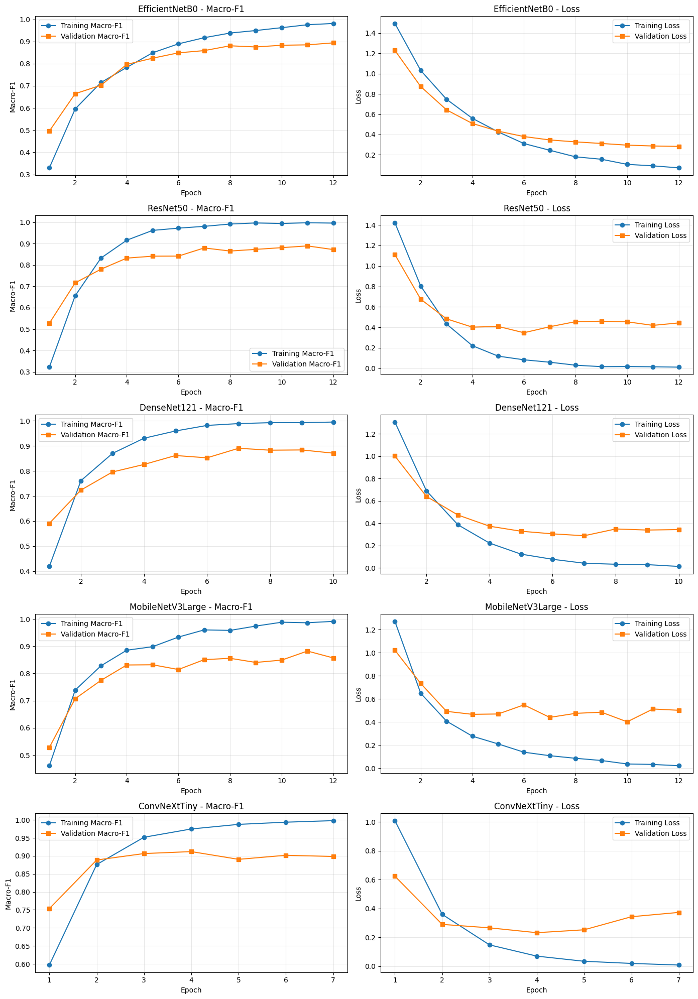


CELL 11 COMPLETED
✅ Five CNN histories analyzed
✅ Training/validation gaps calculated
✅ Learning curves generated
✅ Generalization summary saved

Figure: /kaggle/working/oralsense_model_results/CNN_training_validation_curves.png

IMPORTANT: Test dataset remains untouched.


In [25]:
# ============================================================
# SECTION 4 - CELL 11
# OVERFITTING AND LEARNING CURVE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("=" * 70)
print("SECTION 4 - MODEL GENERALIZATION ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Models to analyze
# ------------------------------------------------------------

CNN_MODELS = [
    "EfficientNetB0",
    "ResNet50",
    "DenseNet121",
    "MobileNetV3Large",
    "ConvNeXtTiny"
]

histories = {}
summary = []

# ------------------------------------------------------------
# 2. Load training histories
# ------------------------------------------------------------

for model_name in CNN_MODELS:

    history_path = (
        RESULTS_DIR / f"{model_name}_history.csv"
    )

    history = pd.read_csv(history_path)

    histories[model_name] = history

    # Best epoch based on validation Macro-F1
    best_idx = history["val_macro_f1"].idxmax()

    best = history.loc[best_idx]
    final = history.iloc[-1]

    accuracy_gap = (
        best["train_accuracy"]
        - best["val_accuracy"]
    ) * 100

    f1_gap = (
        best["train_macro_f1"]
        - best["val_macro_f1"]
    ) * 100

    summary.append({

        "Model": model_name,

        "Best Epoch": int(best["epoch"]),

        "Final Epoch": int(final["epoch"]),

        "Train Accuracy (%)": round(
            best["train_accuracy"] * 100, 2
        ),

        "Val Accuracy (%)": round(
            best["val_accuracy"] * 100, 2
        ),

        "Accuracy Gap (pp)": round(
            accuracy_gap, 2
        ),

        "Train Macro-F1": round(
            best["train_macro_f1"], 4
        ),

        "Val Macro-F1": round(
            best["val_macro_f1"], 4
        ),

        "F1 Gap (pp)": round(
            f1_gap, 2
        )
    })

# ------------------------------------------------------------
# 3. Display generalization summary
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary)

summary_df = summary_df.sort_values(
    "Val Macro-F1",
    ascending=False
).reset_index(drop=True)

print("\nTRAINING VS VALIDATION COMPARISON")
print("-" * 70)

display(summary_df)

# ------------------------------------------------------------
# 4. Plot learning curves for all five CNNs
# ------------------------------------------------------------

fig, axes = plt.subplots(
    5, 2,
    figsize=(14, 20)
)

for i, model_name in enumerate(CNN_MODELS):

    history = histories[model_name]

    epochs = history["epoch"]

    # Macro-F1 curves
    axes[i, 0].plot(
        epochs,
        history["train_macro_f1"],
        marker="o",
        label="Training Macro-F1"
    )

    axes[i, 0].plot(
        epochs,
        history["val_macro_f1"],
        marker="s",
        label="Validation Macro-F1"
    )

    axes[i, 0].set_title(
        f"{model_name} - Macro-F1"
    )

    axes[i, 0].set_xlabel("Epoch")
    axes[i, 0].set_ylabel("Macro-F1")

    axes[i, 0].legend()
    axes[i, 0].grid(alpha=0.3)

    # Loss curves
    axes[i, 1].plot(
        epochs,
        history["train_loss"],
        marker="o",
        label="Training Loss"
    )

    axes[i, 1].plot(
        epochs,
        history["val_loss"],
        marker="s",
        label="Validation Loss"
    )

    axes[i, 1].set_title(
        f"{model_name} - Loss"
    )

    axes[i, 1].set_xlabel("Epoch")
    axes[i, 1].set_ylabel("Loss")

    axes[i, 1].legend()
    axes[i, 1].grid(alpha=0.3)

plt.tight_layout()

figure_path = (
    RESULTS_DIR /
    "CNN_training_validation_curves.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Save summary
# ------------------------------------------------------------

summary_df.to_csv(
    RESULTS_DIR /
    "CNN_generalization_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("CELL 11 COMPLETED")
print("=" * 70)

print("✅ Five CNN histories analyzed")
print("✅ Training/validation gaps calculated")
print("✅ Learning curves generated")
print("✅ Generalization summary saved")

print("\nFigure:", figure_path)

print("\nIMPORTANT: Test dataset remains untouched.")

SECTION 4 - DISEASE-WISE ERROR ANALYSIS

✅ All six prediction files loaded
✅ Validation image alignment verified

PER-CLASS RECALL COMPARISON (%)


,Model,Calculus,Caries,Gingivitis,Hypodontia,Mouth Ulcer,Tooth Discoloration,Total Errors
0,EfficientNetB0,95.24,66.67,95.81,98.46,97.30,80.77,27
1,ResNet50,93.65,66.67,97.01,96.92,97.30,76.92,29
2,DenseNet121,96.83,70.37,96.41,98.46,94.59,73.08,27
3,MobileNetV3Large,90.48,66.67,95.21,97.69,97.30,73.08,34
4,ConvNeXtTiny,96.83,77.78,97.01,97.69,97.30,80.77,22
5,DINOv2SVM,95.24,66.67,98.20,98.46,91.89,73.08,27



CONVNEXT-TINY CONFUSION MATRIX


Predicted Disease,Calculus,Caries,Gingivitis,Hypodontia,Mouth Ulcer,Tooth Discoloration
Actual Disease,,,,,,
Calculus,61,0,2,0,0,0
Caries,2,21,3,0,0,1
Gingivitis,1,1,162,2,0,1
Hypodontia,0,2,0,127,0,1
Mouth Ulcer,0,0,0,0,36,1
Tooth Discoloration,0,5,0,0,0,21


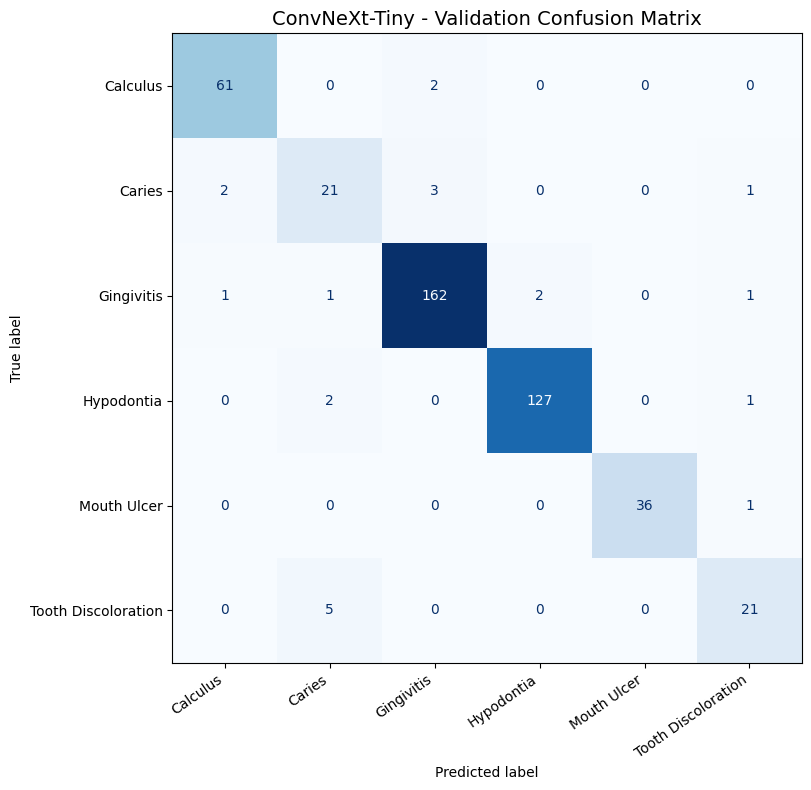


CONVNEXT-TINY - MOST COMMON CONFUSIONS


,Actual Disease,Predicted Disease,Number of Errors
0,Tooth Discoloration,Caries,5
1,Caries,Gingivitis,3
2,Caries,Calculus,2
3,Calculus,Gingivitis,2
4,Hypodontia,Caries,2
5,Gingivitis,Hypodontia,2
6,Caries,Tooth Discoloration,1
7,Gingivitis,Calculus,1
8,Gingivitis,Tooth Discoloration,1
9,Gingivitis,Caries,1



CELL 12 COMPLETED
Validation images: 450
Correct predictions: 428
Incorrect predictions: 22

✅ Six-model per-class recall compared
✅ ConvNeXt confusion matrix generated
✅ Disease-wise errors identified
✅ Results saved

IMPORTANT: Test dataset remains untouched.


In [26]:
# ============================================================
# SECTION 4 - CELL 12
# CONFUSION MATRIX AND DISEASE-WISE ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score
)

print("=" * 70)
print("SECTION 4 - DISEASE-WISE ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load all six validation prediction files
# ------------------------------------------------------------

MODEL_NAMES = [
    "EfficientNetB0",
    "ResNet50",
    "DenseNet121",
    "MobileNetV3Large",
    "ConvNeXtTiny",
    "DINOv2SVM"
]

predictions = {}

for model_name in MODEL_NAMES:

    file_path = (
        RESULTS_DIR /
        f"{model_name}_val_predictions.csv"
    )

    df = pd.read_csv(file_path)

    assert len(df) == len(val_df)

    # Verify predictions match our fixed validation order
    assert (
        df["image_path"].astype(str).tolist()
        ==
        val_df["image_path"].astype(str).tolist()
    ), f"Validation order mismatch: {model_name}"

    assert np.array_equal(
        df["true_label"].to_numpy(),
        val_df["class_name"]
        .map(CLASS_TO_IDX)
        .to_numpy()
    ), f"Label mismatch: {model_name}"

    predictions[model_name] = df

print("\n✅ All six prediction files loaded")
print("✅ Validation image alignment verified")

# ------------------------------------------------------------
# 2. Compare per-class recall
# ------------------------------------------------------------

recall_results = []

for model_name, df in predictions.items():

    recalls = recall_score(
        df["true_label"],
        df["predicted_label"],
        labels=list(range(NUM_CLASSES)),
        average=None,
        zero_division=0
    )

    row = {"Model": model_name}

    for idx, class_name in enumerate(CLASS_NAMES):

        row[class_name] = round(
            recalls[idx] * 100, 2
        )

    row["Total Errors"] = int(
        (
            df["true_label"]
            != df["predicted_label"]
        ).sum()
    )

    recall_results.append(row)

recall_df = pd.DataFrame(recall_results)

print("\n" + "=" * 70)
print("PER-CLASS RECALL COMPARISON (%)")
print("=" * 70)

display(recall_df)

recall_df.to_csv(
    RESULTS_DIR /
    "Six_Model_Per_Class_Recall.csv",
    index=False
)

# ------------------------------------------------------------
# 3. ConvNeXt-Tiny confusion matrix
# ------------------------------------------------------------

convnext_df = predictions["ConvNeXtTiny"]

y_true = convnext_df["true_label"].to_numpy()

y_pred = convnext_df["predicted_label"].to_numpy()

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

print("\n" + "=" * 70)
print("CONVNEXT-TINY CONFUSION MATRIX")
print("=" * 70)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

cm_df.index.name = "Actual Disease"
cm_df.columns.name = "Predicted Disease"

display(cm_df)

# ------------------------------------------------------------
# 4. Plot confusion matrix
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title(
    "ConvNeXt-Tiny - Validation Confusion Matrix",
    fontsize=14
)

plt.xticks(rotation=35, ha="right")

plt.tight_layout()

figure_path = (
    RESULTS_DIR /
    "ConvNeXtTiny_Confusion_Matrix.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Identify most common classification mistakes
# ------------------------------------------------------------

errors = []

for actual_idx in range(NUM_CLASSES):

    for predicted_idx in range(NUM_CLASSES):

        if actual_idx == predicted_idx:
            continue

        count = cm[actual_idx, predicted_idx]

        if count > 0:

            errors.append({
                "Actual Disease":
                    CLASS_NAMES[actual_idx],

                "Predicted Disease":
                    CLASS_NAMES[predicted_idx],

                "Number of Errors":
                    int(count)
            })

errors_df = pd.DataFrame(
    errors,
    columns=[
        "Actual Disease",
        "Predicted Disease",
        "Number of Errors"
    ]
)

errors_df = errors_df.sort_values(
    "Number of Errors",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("CONVNEXT-TINY - MOST COMMON CONFUSIONS")
print("=" * 70)

display(errors_df)

errors_df.to_csv(
    RESULTS_DIR /
    "ConvNeXtTiny_Error_Analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

total_errors = int(
    (y_true != y_pred).sum()
)

print("\n" + "=" * 70)
print("CELL 12 COMPLETED")
print("=" * 70)

print("Validation images:", len(y_true))
print("Correct predictions:", len(y_true) - total_errors)
print("Incorrect predictions:", total_errors)

print("\n✅ Six-model per-class recall compared")
print("✅ ConvNeXt confusion matrix generated")
print("✅ Disease-wise errors identified")
print("✅ Results saved")

print("\nIMPORTANT: Test dataset remains untouched.")

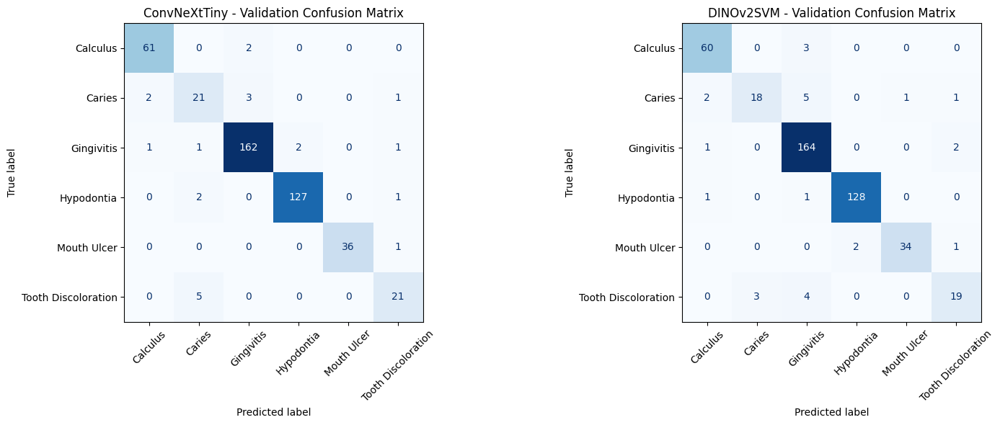

✅ Both confusion matrices generated!


In [27]:
# ============================================================
# CONVNEXT vs DINOV2 - CONFUSION MATRIX COMPARISON
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

models_to_compare = [
    "ConvNeXtTiny",
    "DINOv2SVM"
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for ax, model_name in zip(
    axes, models_to_compare
):

    df = predictions[model_name]

    cm = confusion_matrix(
        df["true_label"],
        df["predicted_label"],
        labels=list(range(NUM_CLASSES))
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"{model_name} - Validation Confusion Matrix"
    )

    ax.tick_params(
        axis="x",
        labelrotation=45
    )

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "ConvNeXt_vs_DINOv2_Confusion.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("✅ Both confusion matrices generated!")

In [28]:
# ============================================================
# SECTION 4 - CELL 14
# PRIMARY-SPECIALIST ERROR COMPLEMENTARITY
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

print("=" * 70)
print("PRIMARY-SPECIALIST COMPLEMENTARITY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Primary and specialist candidates
# ------------------------------------------------------------

PRIMARY = "ConvNeXtTiny"

SPECIALISTS = [
    "EfficientNetB0",
    "ResNet50",
    "DenseNet121",
    "MobileNetV3Large",
    "DINOv2SVM"
]

# Load primary predictions
primary_df = pd.read_csv(
    RESULTS_DIR / f"{PRIMARY}_val_predictions.csv"
)

y_true = primary_df["true_label"].to_numpy()
p_pred = primary_df["predicted_label"].to_numpy()

primary_correct = p_pred == y_true
primary_wrong = ~primary_correct

N = len(y_true)

print("\nPrimary:", PRIMARY)
print("Validation images:", N)
print("Correct predictions:", primary_correct.sum())
print("Incorrect predictions:", primary_wrong.sum())

# ------------------------------------------------------------
# 2. Identify lowest-confidence 20% of primary predictions
# ------------------------------------------------------------

prob_cols = [
    f"prob_{i}" for i in range(NUM_CLASSES)
]

primary_probs = primary_df[prob_cols].to_numpy()

primary_confidence = primary_probs.max(axis=1)

# Lowest-confidence images
uncertain_count = int(np.ceil(0.20 * N))

uncertain_indices = np.argsort(
    primary_confidence
)[:uncertain_count]

uncertain_mask = np.zeros(N, dtype=bool)
uncertain_mask[uncertain_indices] = True

print("\nLOW-CONFIDENCE SUBSET")
print("-" * 70)

print("Selected images:", uncertain_mask.sum())
print(
    "Primary errors in this subset:",
    (primary_wrong & uncertain_mask).sum()
)

# ------------------------------------------------------------
# 3. Compare every specialist
# ------------------------------------------------------------

results = []
specialist_predictions = {}

for specialist in SPECIALISTS:

    df = pd.read_csv(
        RESULTS_DIR / f"{specialist}_val_predictions.csv"
    )

    # Validate alignment
    assert len(df) == N

    assert np.array_equal(
        df["image_path"].astype(str).to_numpy(),
        primary_df["image_path"].astype(str).to_numpy()
    ), f"Image alignment mismatch: {specialist}"

    assert np.array_equal(
        df["true_label"].to_numpy(),
        y_true
    ), f"Label mismatch: {specialist}"

    s_pred = df["predicted_label"].to_numpy()

    specialist_predictions[specialist] = s_pred

    specialist_correct = s_pred == y_true
    specialist_wrong = ~specialist_correct

    # Primary wrong, specialist correct
    rescued = primary_wrong & specialist_correct

    # Primary correct, specialist wrong
    harmed = primary_correct & specialist_wrong

    # Both models wrong
    both_wrong = primary_wrong & specialist_wrong

    # Different predictions
    disagreement = p_pred != s_pred

    # Hypothetical oracle:
    # Correct whenever either model is correct.
    # This uses ground-truth labels and is NOT deployable.
    oracle_accuracy = (
        primary_correct | specialist_correct
    ).mean()

    # Exploratory switching:
    # Use specialist for the lowest-confidence 20%
    hybrid_predictions = np.where(
        uncertain_mask,
        s_pred,
        p_pred
    )

    hybrid_accuracy = accuracy_score(
        y_true,
        hybrid_predictions
    )

    hybrid_macro_f1 = f1_score(
        y_true,
        hybrid_predictions,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    results.append({

        "Specialist": specialist,

        "Specialist Errors": int(
            specialist_wrong.sum()
        ),

        "Primary Errors Rescued": int(
            rescued.sum()
        ),

        "New Errors If Switched": int(
            harmed.sum()
        ),

        "Both Wrong": int(
            both_wrong.sum()
        ),

        "Prediction Disagreements": int(
            disagreement.sum()
        ),

        "Oracle Accuracy (%)": round(
            oracle_accuracy * 100, 2
        ),

        "Rescued in Low-Conf 20%": int(
            (rescued & uncertain_mask).sum()
        ),

        "Harmed in Low-Conf 20%": int(
            (harmed & uncertain_mask).sum()
        ),

        "Low-Conf Switch Acc (%)": round(
            hybrid_accuracy * 100, 2
        ),

        "Low-Conf Switch Macro-F1": round(
            hybrid_macro_f1, 4
        )
    })

# ------------------------------------------------------------
# 4. Display comparison
# ------------------------------------------------------------

complementarity_df = pd.DataFrame(results)

complementarity_df = complementarity_df.sort_values(
    [
        "Primary Errors Rescued",
        "Harmed in Low-Conf 20%"
    ],
    ascending=[False, True]
).reset_index(drop=True)

print("\n" + "=" * 70)
print("SPECIALIST COMPLEMENTARITY COMPARISON")
print("=" * 70)

display(complementarity_df)

complementarity_df.to_csv(
    RESULTS_DIR / "Specialist_Complementarity.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Detailed DINOv2 rescue analysis
# ------------------------------------------------------------

dino_pred = specialist_predictions["DINOv2SVM"]

dino_rescued = (
    primary_wrong & (dino_pred == y_true)
)

dino_harmed = (
    primary_correct & (dino_pred != y_true)
)

class_results = []

for idx, name in enumerate(CLASS_NAMES):

    class_mask = y_true == idx

    class_results.append({

        "Disease": name,

        "ConvNeXt Errors": int(
            (primary_wrong & class_mask).sum()
        ),

        "Rescued by DINOv2": int(
            (dino_rescued & class_mask).sum()
        ),

        "DINOv2 New Errors": int(
            (dino_harmed & class_mask).sum()
        )
    })

dino_class_df = pd.DataFrame(class_results)

print("\n" + "=" * 70)
print("CONVNEXT vs DINOV2 - CLASS-WISE RESCUE ANALYSIS")
print("=" * 70)

display(dino_class_df)

dino_class_df.to_csv(
    RESULTS_DIR / "DINOv2_Class_Wise_Rescue.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 14 COMPLETED")
print("=" * 70)

print("Primary Model:", PRIMARY)
print("Primary Accuracy:", round(
    accuracy_score(y_true, p_pred) * 100, 2
), "%")

print("\n✅ Five specialist candidates compared")
print("✅ Corrected primary errors calculated")
print("✅ Harmful switches calculated")
print("✅ DINOv2 rescue analysis completed")
print("✅ Results saved")

print("\nNOTE:")
print("Oracle results are theoretical upper bounds.")
print("Low-confidence switching is exploratory only.")
print("No routing gate has been trained or validated.")
print("Test dataset remains untouched.")

PRIMARY-SPECIALIST COMPLEMENTARITY ANALYSIS

Primary: ConvNeXtTiny
Validation images: 450
Correct predictions: 428
Incorrect predictions: 22

LOW-CONFIDENCE SUBSET
----------------------------------------------------------------------
Selected images: 90
Primary errors in this subset: 19

SPECIALIST COMPLEMENTARITY COMPARISON


,Specialist,Specialist Errors,Primary Errors Rescued,New Errors If Switched,Both Wrong,Prediction Disagreements,Oracle Accuracy (%),Rescued in Low-Conf 20%,Harmed in Low-Conf 20%,Low-Conf Switch Acc (%),Low-Conf Switch Macro-F1
0,DenseNet121,27,8,13,14,24,96.89,8,9,94.89,0.9089
1,DINOv2SVM,27,8,13,14,27,96.89,7,9,94.67,0.9093
2,ResNet50,29,8,15,14,27,96.89,7,10,94.44,0.9026
3,EfficientNetB0,27,7,12,15,23,96.67,6,7,94.89,0.9059
4,MobileNetV3Large,34,7,19,15,33,96.67,7,10,94.44,0.9002



CONVNEXT vs DINOV2 - CLASS-WISE RESCUE ANALYSIS


,Disease,ConvNeXt Errors,Rescued by DINOv2,DINOv2 New Errors
0,Calculus,2,1,2
1,Caries,6,1,4
2,Gingivitis,5,4,2
3,Hypodontia,3,2,1
4,Mouth Ulcer,1,0,2
5,Tooth Discoloration,5,0,2



CELL 14 COMPLETED
Primary Model: ConvNeXtTiny
Primary Accuracy: 95.11 %

✅ Five specialist candidates compared
✅ Corrected primary errors calculated
✅ Harmful switches calculated
✅ DINOv2 rescue analysis completed
✅ Results saved

NOTE:
Oracle results are theoretical upper bounds.
Low-confidence switching is exploratory only.
No routing gate has been trained or validated.
Test dataset remains untouched.


In [29]:
# ============================================================
# SECTION 4 - CELL 15
# UNCERTAINTY RELIABILITY AND SPECIALIST ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

print("=" * 70)
print("UNCERTAINTY RELIABILITY AND SPECIALIST ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load primary model predictions
# ------------------------------------------------------------

primary_df = pd.read_csv(
    RESULTS_DIR / "ConvNeXtTiny_val_predictions.csv"
)

y_true = primary_df["true_label"].to_numpy()

primary_pred = (
    primary_df["predicted_label"].to_numpy()
)

prob_cols = [
    f"prob_{i}" for i in range(NUM_CLASSES)
]

primary_probs = primary_df[prob_cols].to_numpy()

confidence = primary_probs.max(axis=1)

uncertainty = 1.0 - confidence

errors = (primary_pred != y_true).astype(int)

N = len(y_true)

assert N == 450

# ------------------------------------------------------------
# 2. Evaluate uncertainty as an error detector
# ------------------------------------------------------------

error_auroc = roc_auc_score(
    errors,
    uncertainty
)

error_auprc = average_precision_score(
    errors,
    uncertainty
)

print("\nUNCERTAINTY ERROR-DETECTION PERFORMANCE")
print("-" * 70)

print("Total images:", N)
print("Total primary errors:", errors.sum())

print(f"Error Detection AUROC: {error_auroc:.4f}")
print(f"Error Detection AUPRC: {error_auprc:.4f}")

print(
    f"Baseline Error Rate: {errors.mean():.4f}"
)

# ------------------------------------------------------------
# 3. Selective prediction analysis
# ------------------------------------------------------------

# Sort predictions by highest confidence first
sorted_indices = np.argsort(-confidence)

coverage_levels = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    1.00
]

coverage_results = []

for coverage in coverage_levels:

    n_selected = int(round(N * coverage))

    selected_idx = sorted_indices[:n_selected]

    selected_errors = errors[selected_idx].sum()

    accepted_accuracy = (
        1.0 - selected_errors / n_selected
    )

    coverage_results.append({

        "Coverage (%)": round(coverage * 100, 1),

        "Accepted Images": n_selected,

        "Errors": int(selected_errors),

        "Accepted Accuracy (%)": round(
            accepted_accuracy * 100, 2
        ),

        "Error Rate (%)": round(
            selected_errors / n_selected * 100,
            2
        )
    })

coverage_df = pd.DataFrame(coverage_results)

print("\n" + "=" * 70)
print("CONFIDENCE-BASED SELECTIVE PREDICTION")
print("=" * 70)

display(coverage_df)

coverage_df.to_csv(
    RESULTS_DIR / "Confidence_Coverage_Analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Compare class-wise specialist corrections
# ------------------------------------------------------------

SPECIALISTS = [
    "EfficientNetB0",
    "ResNet50",
    "DenseNet121",
    "MobileNetV3Large",
    "DINOv2SVM"
]

rescue_results = []

for specialist in SPECIALISTS:

    df = pd.read_csv(
        RESULTS_DIR /
        f"{specialist}_val_predictions.csv"
    )

    assert np.array_equal(
        df["image_path"].astype(str).to_numpy(),
        primary_df["image_path"].astype(str).to_numpy()
    )

    assert np.array_equal(
        df["true_label"].to_numpy(),
        y_true
    )

    specialist_pred = (
        df["predicted_label"].to_numpy()
    )

    primary_wrong = primary_pred != y_true

    specialist_correct = specialist_pred == y_true

    specialist_wrong = ~specialist_correct

    rescued = (
        primary_wrong & specialist_correct
    )

    harmed = (
        ~primary_wrong & specialist_wrong
    )

    row = {
        "Specialist": specialist,
        "Total Rescued": int(rescued.sum()),
        "Total Harmed": int(harmed.sum())
    }

    for idx, class_name in enumerate(CLASS_NAMES):

        class_mask = y_true == idx

        row[f"{class_name} Rescued"] = int(
            (rescued & class_mask).sum()
        )

    rescue_results.append(row)

rescue_df = pd.DataFrame(rescue_results)

print("\n" + "=" * 70)
print("DISEASE-WISE SPECIALIST CORRECTIONS")
print("=" * 70)

display(rescue_df)

rescue_df.to_csv(
    RESULTS_DIR /
    "All_Specialists_Class_Wise_Rescue.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Save uncertainty information
# ------------------------------------------------------------

uncertainty_df = primary_df[
    ["image_path", "class_name", "near_duplicate_group"]
].copy()

uncertainty_df["true_label"] = y_true
uncertainty_df["predicted_label"] = primary_pred

uncertainty_df["confidence"] = confidence
uncertainty_df["uncertainty"] = uncertainty
uncertainty_df["is_error"] = errors

uncertainty_df.to_csv(
    RESULTS_DIR /
    "ConvNeXt_Uncertainty_Analysis.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 15 COMPLETED")
print("=" * 70)

print("✅ Uncertainty discrimination evaluated")
print("✅ Confidence-coverage analysis completed")
print("✅ Class-wise specialist corrections compared")
print("✅ Results saved")

print("\nNOTE:")
print("These are exploratory validation results.")
print("Softmax probabilities are not yet calibrated.")
print("Coverage is not the same as overall accuracy.")
print("Test dataset remains untouched.")

UNCERTAINTY RELIABILITY AND SPECIALIST ANALYSIS

UNCERTAINTY ERROR-DETECTION PERFORMANCE
----------------------------------------------------------------------
Total images: 450
Total primary errors: 22
Error Detection AUROC: 0.9190
Error Detection AUPRC: 0.4036
Baseline Error Rate: 0.0489

CONFIDENCE-BASED SELECTIVE PREDICTION


,Coverage (%),Accepted Images,Errors,Accepted Accuracy (%),Error Rate (%)
0,50.0,225,0,100.00,0.00
1,60.0,270,1,99.63,0.37
2,70.0,315,2,99.37,0.63
3,80.0,360,3,99.17,0.83
4,90.0,405,7,98.27,1.73
5,100.0,450,22,95.11,4.89



DISEASE-WISE SPECIALIST CORRECTIONS


,Specialist,Total Rescued,Total Harmed,Calculus Rescued,Caries Rescued,Gingivitis Rescued,Hypodontia Rescued,Mouth Ulcer Rescued,Tooth Discoloration Rescued
0,EfficientNetB0,7,12,1,0,3,1,1,1
1,ResNet50,8,15,1,0,3,3,0,1
2,DenseNet121,8,13,0,0,4,1,1,2
3,MobileNetV3Large,7,19,0,2,4,1,0,0
4,DINOv2SVM,8,13,1,1,4,2,0,0



CELL 15 COMPLETED
✅ Uncertainty discrimination evaluated
✅ Confidence-coverage analysis completed
✅ Class-wise specialist corrections compared
✅ Results saved

NOTE:
These are exploratory validation results.
Softmax probabilities are not yet calibrated.
Coverage is not the same as overall accuracy.
Test dataset remains untouched.


CONVNEXT - VISUAL ERROR INSPECTION

Total ConvNeXt errors: 22

High-confidence errors appear first.


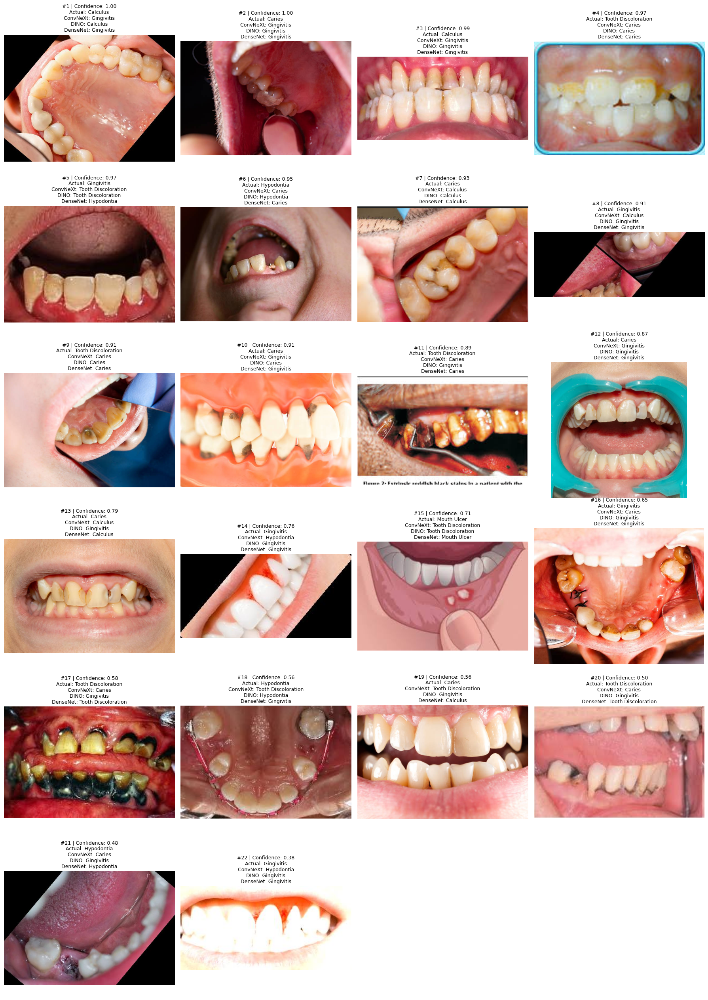


CELL 16 COMPLETED
✅ All incorrect images displayed
✅ Predictions from three models compared
✅ High-confidence mistakes identified
✅ Detailed error report saved

DINOv2 rescues: 8
DenseNet rescues: 8

Test dataset remains untouched.


In [30]:
# ============================================================
# SECTION 4 - CELL 16
# VISUAL INSPECTION OF CONVNEXT CLASSIFICATION ERRORS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

print("=" * 70)
print("CONVNEXT - VISUAL ERROR INSPECTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load model predictions
# ------------------------------------------------------------

primary_df = pd.read_csv(
    RESULTS_DIR / "ConvNeXtTiny_val_predictions.csv"
)

dino_df = pd.read_csv(
    RESULTS_DIR / "DINOv2SVM_val_predictions.csv"
)

dense_df = pd.read_csv(
    RESULTS_DIR / "DenseNet121_val_predictions.csv"
)

# Verify image alignment
assert (
    primary_df["image_path"].tolist()
    == dino_df["image_path"].tolist()
    == dense_df["image_path"].tolist()
)

# ------------------------------------------------------------
# 2. Extract incorrect predictions
# ------------------------------------------------------------

prob_cols = [
    f"prob_{i}" for i in range(NUM_CLASSES)
]

primary_df["confidence"] = (
    primary_df[prob_cols].max(axis=1)
)

error_mask = (
    primary_df["true_label"]
    != primary_df["predicted_label"]
)

errors_df = primary_df.loc[error_mask].copy()

# Add other models' predictions
errors_df["DINO_prediction"] = (
    dino_df.loc[error_mask, "predicted_label"]
)

errors_df["DenseNet_prediction"] = (
    dense_df.loc[error_mask, "predicted_label"]
)

# Identify successful specialist rescues
errors_df["DINO_rescued"] = (
    errors_df["DINO_prediction"]
    == errors_df["true_label"]
)

errors_df["DenseNet_rescued"] = (
    errors_df["DenseNet_prediction"]
    == errors_df["true_label"]
)

# High-confidence errors first
errors_df = errors_df.sort_values(
    "confidence",
    ascending=False
).reset_index(drop=True)

print("\nTotal ConvNeXt errors:", len(errors_df))

print("\nHigh-confidence errors appear first.")

# ------------------------------------------------------------
# 3. Display error images
# ------------------------------------------------------------

n_images = len(errors_df)
n_cols = 4
n_rows = int(np.ceil(n_images / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, n_rows * 4.2)
)

axes = np.array(axes).reshape(-1)

for i, row in errors_df.iterrows():

    ax = axes[i]

    with Image.open(row["image_path"]) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        ax.imshow(img)

    actual = CLASS_NAMES[int(row["true_label"])]

    conv_pred = CLASS_NAMES[
        int(row["predicted_label"])
    ]

    dino_pred = CLASS_NAMES[
        int(row["DINO_prediction"])
    ]

    dense_pred = CLASS_NAMES[
        int(row["DenseNet_prediction"])
    ]

    ax.set_title(
        f"#{i + 1} | Confidence: {row['confidence']:.2f}\n"
        f"Actual: {actual}\n"
        f"ConvNeXt: {conv_pred}\n"
        f"DINO: {dino_pred}\n"
        f"DenseNet: {dense_pred}",
        fontsize=9
    )

    ax.axis("off")

for j in range(n_images, len(axes)):
    axes[j].axis("off")

plt.tight_layout()

figure_path = (
    RESULTS_DIR /
    "ConvNeXt_22_Validation_Errors.png"
)

plt.savefig(
    figure_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Save detailed error table
# ------------------------------------------------------------

errors_df.to_csv(
    RESULTS_DIR /
    "ConvNeXt_Detailed_Error_Inspection.csv",
    index=False
)

print("\n" + "=" * 70)
print("CELL 16 COMPLETED")
print("=" * 70)

print("✅ All incorrect images displayed")
print("✅ Predictions from three models compared")
print("✅ High-confidence mistakes identified")
print("✅ Detailed error report saved")

print("\nDINOv2 rescues:",
      errors_df["DINO_rescued"].sum())

print("DenseNet rescues:",
      errors_df["DenseNet_rescued"].sum())

print("\nTest dataset remains untouched.")

CONVNEXT-TINY - GRAD-CAM EXPLAINABILITY

✅ Best ConvNeXt checkpoint loaded
Best epoch: 4

Selected images: 6
Incorrect examples: 4
Correct examples: 2


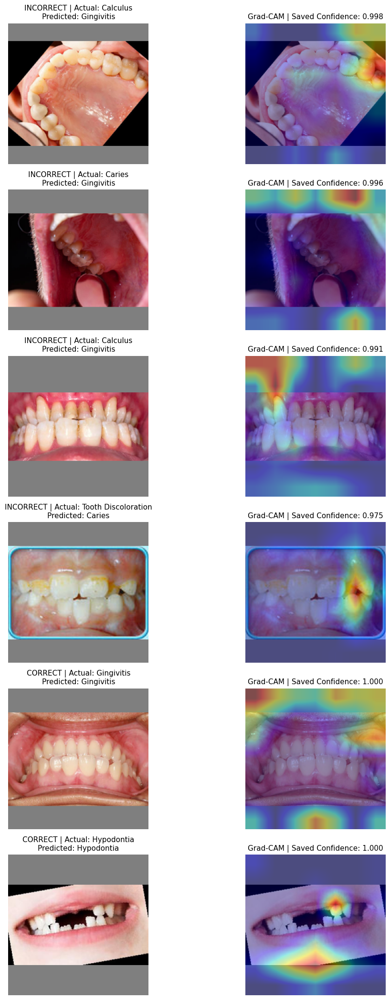


CELL 17 COMPLETED
✅ ConvNeXt checkpoint loaded
✅ Six images analyzed
✅ Grad-CAM heatmaps generated
✅ Results saved

Figure: /kaggle/working/oralsense_model_results/ConvNeXt_GradCAM_Analysis.png

Test dataset remains untouched.


In [31]:
# ============================================================
# SECTION 4 - CELL 17
# CONVNEXT-TINY GRAD-CAM EXPLAINABILITY
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from torchvision.models import convnext_tiny

print("=" * 70)
print("CONVNEXT-TINY - GRAD-CAM EXPLAINABILITY")
print("=" * 70)


# ------------------------------------------------------------
# 1. Load best saved ConvNeXt checkpoint
# ------------------------------------------------------------

checkpoint_path = (
    RESULTS_DIR / "ConvNeXtTiny_best.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model = convnext_tiny(weights=None)

in_features = model.classifier[2].in_features

model.classifier[2] = nn.Linear(
    in_features,
    NUM_CLASSES
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

print("\n✅ Best ConvNeXt checkpoint loaded")
print("Best epoch:", checkpoint["epoch"])


# ------------------------------------------------------------
# 2. Load validation predictions
# ------------------------------------------------------------

df = pd.read_csv(
    RESULTS_DIR / "ConvNeXtTiny_val_predictions.csv"
)

prob_cols = [
    f"prob_{i}" for i in range(NUM_CLASSES)
]

df["confidence"] = df[prob_cols].max(axis=1)

wrong_df = df[
    df["true_label"] != df["predicted_label"]
].sort_values(
    "confidence",
    ascending=False
)

correct_df = df[
    df["true_label"] == df["predicted_label"]
].sort_values(
    "confidence",
    ascending=False
)

# Four high-confidence mistakes
wrong_samples = wrong_df.head(4).copy()

# Two high-confidence correct examples
# from different classes
correct_samples = (
    correct_df
    .groupby("true_label", sort=False)
    .head(1)
    .head(2)
    .copy()
)

samples = pd.concat(
    [wrong_samples, correct_samples],
    ignore_index=True
)

print("\nSelected images:", len(samples))
print("Incorrect examples:", len(wrong_samples))
print("Correct examples:", len(correct_samples))


# ------------------------------------------------------------
# 3. Register Grad-CAM forward hook
# ------------------------------------------------------------

captured = {}

def capture_activations(module, inputs, output):

    captured["activations"] = output
    output.retain_grad()


# Final convolutional feature stage
target_layer = model.features[-1]

hook_handle = target_layer.register_forward_hook(
    capture_activations
)


# ------------------------------------------------------------
# 4. Generate Grad-CAM
# ------------------------------------------------------------

def generate_gradcam(image_tensor):

    model.zero_grad(set_to_none=True)

    outputs = model(image_tensor)

    predicted_class = int(
        outputs.argmax(dim=1).item()
    )

    # Gradient of predicted-class logit
    score = outputs[0, predicted_class]

    score.backward()

    activations = captured["activations"]

    gradients = activations.grad

    # Global average pooling of gradients
    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    # Weighted combination of feature maps
    cam = (
        weights * activations
    ).sum(
        dim=1,
        keepdim=True
    )

    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(IMG_SIZE, IMG_SIZE),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0]

    # Normalize between 0 and 1
    cam = cam - cam.min()

    cam = cam / (
        cam.max() + 1e-8
    )

    return (
        cam.detach().cpu().numpy(),
        predicted_class
    )


# ------------------------------------------------------------
# 5. Visualize original images and Grad-CAM
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(samples),
    2,
    figsize=(12, 21)
)

try:

    for i, row in samples.iterrows():

        with Image.open(row["image_path"]) as img:

            image = prepare_image(img)

        image_array = np.array(image)

        image_tensor = (
            val_transform(image)
            .unsqueeze(0)
            .to(DEVICE)
        )

        heatmap, predicted_idx = generate_gradcam(
            image_tensor
        )

        actual_name = CLASS_NAMES[
            int(row["true_label"])
        ]

        predicted_name = CLASS_NAMES[
            predicted_idx
        ]

        status = (
            "INCORRECT"
            if predicted_idx != int(row["true_label"])
            else "CORRECT"
        )

        # Original
        axes[i, 0].imshow(image_array)

        axes[i, 0].set_title(
            f"{status} | Actual: {actual_name}\n"
            f"Predicted: {predicted_name}",
            fontsize=11
        )

        axes[i, 0].axis("off")

        # Grad-CAM overlay
        axes[i, 1].imshow(image_array)

        axes[i, 1].imshow(
            heatmap,
            cmap="jet",
            alpha=0.40,
            vmin=0,
            vmax=1
        )

        axes[i, 1].set_title(
            f"Grad-CAM | Saved Confidence: "
            f"{row['confidence']:.3f}",
            fontsize=11
        )

        axes[i, 1].axis("off")

finally:

    hook_handle.remove()


plt.tight_layout()

figure_path = (
    RESULTS_DIR /
    "ConvNeXt_GradCAM_Analysis.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 6. Save selected samples
# ------------------------------------------------------------

samples.to_csv(
    RESULTS_DIR /
    "ConvNeXt_GradCAM_Samples.csv",
    index=False
)

print("\n" + "=" * 70)
print("CELL 17 COMPLETED")
print("=" * 70)

print("✅ ConvNeXt checkpoint loaded")
print("✅ Six images analyzed")
print("✅ Grad-CAM heatmaps generated")
print("✅ Results saved")

print("\nFigure:", figure_path)

print("\nTest dataset remains untouched.")

CONVNEXT-TINY - OCCLUSION SENSITIVITY

Samples: 6
Device: cuda


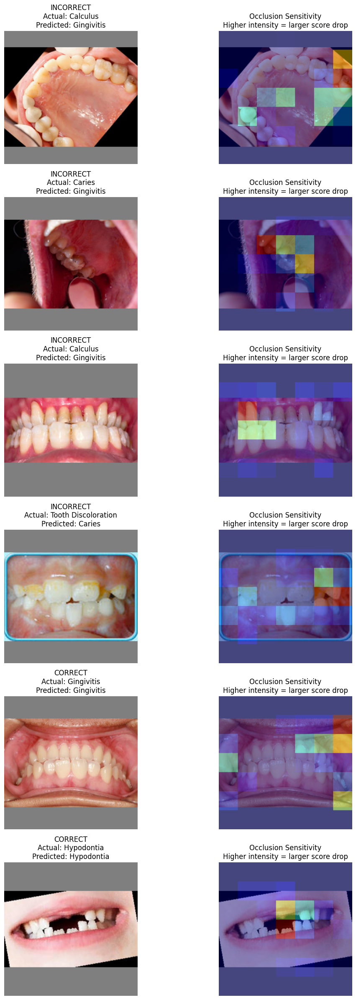


OCCLUSION SENSITIVITY SUMMARY


,Image,Actual,Predicted,Correct,Maximum Logit Drop,Most Influential Row,Most Influential Column
0,1,Calculus,Gingivitis,False,0.4922,2,6
1,2,Caries,Gingivitis,False,2.9238,2,2
2,3,Calculus,Gingivitis,False,0.7812,2,1
3,4,Tooth Discoloration,Caries,False,1.2383,3,5
4,5,Gingivitis,Gingivitis,True,0.2422,1,6
5,6,Hypodontia,Hypodontia,True,0.1953,3,3



CELL 18 COMPLETED
✅ Six images analyzed
✅ Occlusion heatmaps generated
✅ Prediction sensitivity measured
✅ Results saved

Figure: /kaggle/working/oralsense_model_results/ConvNeXt_Occlusion_Sensitivity.png

Test dataset remains untouched.


In [32]:
# ============================================================
# SECTION 4 - CELL 18
# CONVNEXT-TINY OCCLUSION SENSITIVITY ANALYSIS
# ============================================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

print("=" * 70)
print("CONVNEXT-TINY - OCCLUSION SENSITIVITY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load the six Grad-CAM samples
# ------------------------------------------------------------

samples_df = pd.read_csv(
    RESULTS_DIR / "ConvNeXt_GradCAM_Samples.csv"
)

assert len(samples_df) == 6

# Reuse the ConvNeXt model loaded in Cell 17
model.eval()

print("\nSamples:", len(samples_df))
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. Occlusion configuration
# ------------------------------------------------------------

PATCH_SIZE = 32
STEP = 32

# Neutral gray used in our preprocessing
neutral_values = torch.tensor(
    [
        (127 / 255 - m) / s
        for m, s in zip(MEAN, STD)
    ],
    dtype=torch.float32,
    device=DEVICE
).view(3, 1, 1)

# ------------------------------------------------------------
# 3. Occlusion sensitivity function
# ------------------------------------------------------------

def calculate_occlusion_map(image_tensor):

    model.eval()

    with torch.inference_mode():

        with torch.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):

            original_output = model(image_tensor)

        predicted_class = int(
            original_output.argmax(dim=1).item()
        )

        original_score = float(
            original_output[0, predicted_class].item()
        )

        locations = []

        for y in range(0, IMG_SIZE, STEP):

            for x in range(0, IMG_SIZE, STEP):

                locations.append((y, x))

        scores = []

        # Process small batches to avoid GPU OOM
        for start in range(0, len(locations), 8):

            batch_locations = locations[start:start + 8]

            occluded_batch = image_tensor.repeat(
                len(batch_locations), 1, 1, 1
            ).clone()

            for i, (y, x) in enumerate(batch_locations):

                occluded_batch[
                    i,
                    :,
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] = neutral_values

            with torch.autocast(
                device_type="cuda",
                enabled=(DEVICE.type == "cuda")
            ):

                outputs = model(occluded_batch)

            class_scores = outputs[
                :, predicted_class
            ].float()

            score_drops = (
                original_score - class_scores
            )

            scores.extend(
                score_drops.cpu().numpy()
            )

    grid_size = IMG_SIZE // STEP

    score_map = np.array(scores).reshape(
        grid_size,
        grid_size
    )

    # Positive drop means occlusion reduced
    # the original predicted-class logit
    positive_map = np.maximum(score_map, 0)

    # Expand from 7x7 to 224x224
    heatmap = np.repeat(
        np.repeat(
            positive_map,
            STEP,
            axis=0
        ),
        STEP,
        axis=1
    )

    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    return heatmap, score_map, predicted_class


# ------------------------------------------------------------
# 4. Analyze and visualize six images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(samples_df),
    2,
    figsize=(12, 24)
)

results = []

for i, row in samples_df.iterrows():

    with Image.open(row["image_path"]) as img:

        image = prepare_image(img)

    image_array = np.array(image)

    image_tensor = (
        val_transform(image)
        .unsqueeze(0)
        .to(DEVICE)
    )

    heatmap, score_map, predicted_idx = (
        calculate_occlusion_map(image_tensor)
    )

    actual_name = CLASS_NAMES[
        int(row["true_label"])
    ]

    predicted_name = CLASS_NAMES[
        predicted_idx
    ]

    status = (
        "CORRECT"
        if predicted_idx == int(row["true_label"])
        else "INCORRECT"
    )

    # Original image
    axes[i, 0].imshow(image_array)

    axes[i, 0].set_title(
        f"{status}\n"
        f"Actual: {actual_name}\n"
        f"Predicted: {predicted_name}"
    )

    axes[i, 0].axis("off")

    # Occlusion heatmap
    axes[i, 1].imshow(image_array)

    axes[i, 1].imshow(
        heatmap,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    axes[i, 1].set_title(
        "Occlusion Sensitivity\n"
        "Higher intensity = larger score drop"
    )

    axes[i, 1].axis("off")

    # Record most influential patch
    max_pos = np.unravel_index(
        np.argmax(score_map),
        score_map.shape
    )

    results.append({

        "Image": i + 1,

        "Actual": actual_name,

        "Predicted": predicted_name,

        "Correct": status == "CORRECT",

        "Maximum Logit Drop": round(
            float(score_map.max()), 4
        ),

        "Most Influential Row": int(max_pos[0]),

        "Most Influential Column": int(max_pos[1])
    })

plt.tight_layout()

figure_path = (
    RESULTS_DIR /
    "ConvNeXt_Occlusion_Sensitivity.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Save numerical results
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("OCCLUSION SENSITIVITY SUMMARY")
print("=" * 70)

display(results_df)

results_df.to_csv(
    RESULTS_DIR /
    "ConvNeXt_Occlusion_Summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("CELL 18 COMPLETED")
print("=" * 70)

print("✅ Six images analyzed")
print("✅ Occlusion heatmaps generated")
print("✅ Prediction sensitivity measured")
print("✅ Results saved")

print("\nFigure:", figure_path)
print("\nTest dataset remains untouched.")

In [33]:
# ============================================================
# SECTION 4 - CELL 19
# CONVNEXT PADDING SENSITIVITY ANALYSIS
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import pandas as pd

from PIL import Image, ImageOps
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision.models import convnext_tiny

print("=" * 70)
print("CONVNEXT - PADDING SENSITIVITY ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load best ConvNeXt checkpoint
# ------------------------------------------------------------

model = convnext_tiny(weights=None)

in_features = model.classifier[2].in_features

model.classifier[2] = nn.Linear(
    in_features,
    NUM_CLASSES
)

checkpoint = torch.load(
    RESULTS_DIR / "ConvNeXtTiny_best.pth",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

print("\n✅ Best ConvNeXt model loaded")


# ------------------------------------------------------------
# 2. Dataset with three padding variations
# ------------------------------------------------------------

PADDING_COLORS = [127, 0, 255]
PADDING_NAMES = ["Gray", "Black", "White"]


class PaddingSensitivityDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.df)

    def __getitem__(self, idx):

        path = self.df.iloc[idx]["image_path"]

        with Image.open(path) as original:

            image = ImageOps.exif_transpose(
                original
            ).convert("RGB")

        # Identify padding area using a binary mask
        content_mask = ImageOps.pad(
            Image.new("L", image.size, 255),
            size=(IMG_SIZE, IMG_SIZE),
            method=Image.Resampling.NEAREST,
            color=0
        )

        padding_fraction = (
            np.asarray(content_mask) == 0
        ).mean()

        versions = []

        for color in PADDING_COLORS:

            padded_image = ImageOps.pad(
                image,
                size=(IMG_SIZE, IMG_SIZE),
                method=Image.Resampling.BICUBIC,
                color=(color, color, color)
            )

            versions.append(
                val_transform(padded_image)
            )

        return (
            torch.stack(versions),
            float(padding_fraction)
        )


# ------------------------------------------------------------
# 3. DataLoader
# ------------------------------------------------------------

padding_dataset = PaddingSensitivityDataset(
    val_df
)

padding_loader = DataLoader(
    padding_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Validation images:", len(padding_dataset))


# ------------------------------------------------------------
# 4. Evaluate all padding variations
# ------------------------------------------------------------

all_probabilities = []
all_padding_fractions = []

with torch.inference_mode():

    for images, padding_fraction in padding_loader:

        batch_size = images.shape[0]

        images = images.reshape(
            -1, 3, IMG_SIZE, IMG_SIZE
        ).to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            enabled=(DEVICE.type == "cuda")
        ):

            outputs = model(images)

        probabilities = torch.softmax(
            outputs.float(), dim=1
        )

        probabilities = probabilities.reshape(
            batch_size,
            3,
            NUM_CLASSES
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

        all_padding_fractions.extend(
            padding_fraction.numpy()
        )

all_probabilities = np.concatenate(
    all_probabilities,
    axis=0
)

padding_fractions = np.array(
    all_padding_fractions
)

assert all_probabilities.shape == (
    len(val_df), 3, NUM_CLASSES
)

print("\n✅ All padding variations evaluated")


# ------------------------------------------------------------
# 5. Compare disease predictions
# ------------------------------------------------------------

predictions = all_probabilities.argmax(axis=2)

gray_pred = predictions[:, 0]
black_pred = predictions[:, 1]
white_pred = predictions[:, 2]

has_padding = padding_fractions > 0

black_changed = gray_pred != black_pred
white_changed = gray_pred != white_pred

saved_predictions = pd.read_csv(
    RESULTS_DIR / "ConvNeXtTiny_val_predictions.csv"
)

baseline_matches = np.sum(
    gray_pred ==
    saved_predictions["predicted_label"].to_numpy()
)

print("\nBASELINE VERIFICATION")
print("-" * 70)

print(
    "Gray predictions matching saved results:",
    baseline_matches,
    "/",
    len(val_df)
)

print(
    "Images containing padding:",
    int(has_padding.sum())
)


# ------------------------------------------------------------
# 6. Numerical summary
# ------------------------------------------------------------

summary = pd.DataFrame({

    "Padding Color": [
        "Black",
        "White"
    ],

    "Prediction Changes": [
        int(black_changed.sum()),
        int(white_changed.sum())
    ],

    "Changes Among Padded Images": [
        int((black_changed & has_padding).sum()),
        int((white_changed & has_padding).sum())
    ],

    "Total Validation Images": [
        len(val_df),
        len(val_df)
    ]

})

print("\n" + "=" * 70)
print("PADDING SENSITIVITY RESULTS")
print("=" * 70)

display(summary)


# ------------------------------------------------------------
# 7. Save image-wise results
# ------------------------------------------------------------

results_df = val_df[
    ["image_path", "class_name"]
].copy().reset_index(drop=True)

results_df["padding_fraction"] = padding_fractions

results_df["gray_prediction"] = gray_pred
results_df["black_prediction"] = black_pred
results_df["white_prediction"] = white_pred

results_df["black_changed"] = black_changed
results_df["white_changed"] = white_changed

results_df["any_prediction_change"] = (
    black_changed | white_changed
)

results_df.to_csv(
    RESULTS_DIR /
    "ConvNeXt_Padding_Sensitivity.csv",
    index=False
)

print("\nImages changing under either variation:")

print(
    int(results_df["any_prediction_change"].sum())
)

print("\n" + "=" * 70)
print("CELL 19 COMPLETED")
print("=" * 70)

print("✅ Padding sensitivity evaluated")
print("✅ Original photographs preserved")
print("✅ Prediction changes calculated")
print("✅ Results saved")

print("\nTest dataset remains untouched.")

CONVNEXT - PADDING SENSITIVITY ANALYSIS

✅ Best ConvNeXt model loaded
Validation images: 450

✅ All padding variations evaluated

BASELINE VERIFICATION
----------------------------------------------------------------------
Gray predictions matching saved results: 450 / 450
Images containing padding: 447

PADDING SENSITIVITY RESULTS


,Padding Color,Prediction Changes,Changes Among Padded Images,Total Validation Images
0,Black,5,5,450
1,White,2,2,450



Images changing under either variation:
5

CELL 19 COMPLETED
✅ Padding sensitivity evaluated
✅ Original photographs preserved
✅ Prediction changes calculated
✅ Results saved

Test dataset remains untouched.


In [34]:
# ============================================================
# SECTION 5 - CELL 20
# PREPARE GROUP-AWARE FOLDS FOR ADAPTIVE GATE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

print("=" * 70)
print("ADAPTIVE GATE - GROUP-AWARE FOLD PREPARATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Prepare training labels and group IDs
# ------------------------------------------------------------

y_train = (
    train_df["class_name"]
    .map(CLASS_TO_IDX)
    .to_numpy()
)

groups = (
    train_df["near_duplicate_group"]
    .astype(str)
    .to_numpy()
)

assert len(y_train) == 2096
assert len(groups) == 2096

# ------------------------------------------------------------
# 2. Create 4 group-aware folds
# ------------------------------------------------------------

N_FOLDS = 4

cv = StratifiedGroupKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

fold_assignments = np.full(
    len(train_df),
    -1,
    dtype=int
)

gate_cv_splits = list(
    cv.split(
        np.zeros(len(y_train)),
        y_train,
        groups=groups
    )
)

# ------------------------------------------------------------
# 3. Verify fold separation
# ------------------------------------------------------------

fold_summary = []

for fold, (train_idx, valid_idx) in enumerate(
    gate_cv_splits
):

    train_groups = set(groups[train_idx])
    valid_groups = set(groups[valid_idx])

    assert train_groups.isdisjoint(valid_groups)

    fold_assignments[valid_idx] = fold

    counts = np.bincount(
        y_train[valid_idx],
        minlength=NUM_CLASSES
    )

    row = {
        "Fold": fold + 1,
        "Training Images": len(train_idx),
        "OOF Images": len(valid_idx),
        "Training Groups": len(train_groups),
        "OOF Groups": len(valid_groups)
    }

    for idx, name in enumerate(CLASS_NAMES):
        row[name] = int(counts[idx])

    fold_summary.append(row)

assert np.all(fold_assignments >= 0)

# ------------------------------------------------------------
# 4. Save fold assignments
# ------------------------------------------------------------

gate_fold_df = train_df[
    [
        "image_path",
        "class_name",
        "near_duplicate_group"
    ]
].copy()

gate_fold_df["fold"] = fold_assignments

gate_fold_df.to_csv(
    RESULTS_DIR / "Adaptive_Gate_OOF_Folds.csv",
    index=False
)

# ------------------------------------------------------------
# 5. Display summary
# ------------------------------------------------------------

summary_df = pd.DataFrame(fold_summary)

print("\nGROUP-AWARE FOLD SUMMARY")
print("-" * 70)

display(summary_df)

print("\nTotal images:", len(train_df))
print("Unique groups:", len(set(groups)))
print("Number of folds:", N_FOLDS)

print("\n✅ Every training image assigned to one OOF fold")
print("✅ No near-duplicate group overlap within folds")
print("✅ Fixed fold assignments saved")

print("\n" + "=" * 70)
print("CELL 20 COMPLETED")
print("=" * 70)

print("Test dataset remains untouched.")

ADAPTIVE GATE - GROUP-AWARE FOLD PREPARATION

GROUP-AWARE FOLD SUMMARY
----------------------------------------------------------------------


,Fold,Training Images,OOF Images,Training Groups,OOF Groups,Calculus,Caries,Gingivitis,Hypodontia,Mouth Ulcer,Tooth Discoloration
0,1,1525,571,1153,383,78,30,233,169,35,26
1,2,1611,485,1153,383,46,39,184,145,44,27
2,3,1588,508,1151,385,71,33,204,132,42,26
3,4,1564,532,1151,385,69,28,229,121,45,40



Total images: 2096
Unique groups: 1536
Number of folds: 4

✅ Every training image assigned to one OOF fold
✅ No near-duplicate group overlap within folds
✅ Fixed fold assignments saved

CELL 20 COMPLETED
Test dataset remains untouched.


In [35]:
# ============================================================
# SECTION 5 - CELL 21
# GENERATE GROUP-AWARE CONVNEXT OUT-OF-FOLD PREDICTIONS
# ============================================================

import gc
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)
from sklearn.metrics import accuracy_score, f1_score

print("=" * 70)
print("ADAPTIVE GATE - CONVNEXT OOF PREDICTIONS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

OOF_EPOCHS = 4
OOF_BATCH_SIZE = 16

OOF_DIR = RESULTS_DIR / "oof_predictions"
OOF_DIR.mkdir(parents=True, exist_ok=True)

N = len(train_df)

y_train_oof = (
    train_df["class_name"]
    .map(CLASS_TO_IDX)
    .to_numpy()
)

oof_probabilities = np.full(
    (N, NUM_CLASSES),
    np.nan,
    dtype=np.float32
)

oof_fold_ids = np.full(N, -1, dtype=int)

print("\nTraining images:", N)
print("OOF folds:", len(gate_cv_splits))
print("Epochs per fold:", OOF_EPOCHS)
print("Device:", DEVICE)

# ------------------------------------------------------------
# 2. Datasets
# ------------------------------------------------------------

oof_train_dataset = OralDiseaseDataset(
    train_df,
    transform=train_transform
)

oof_eval_dataset = OralDiseaseDataset(
    train_df,
    transform=val_transform
)

start_time = time.time()

# ------------------------------------------------------------
# 3. Train and predict each fold
# ------------------------------------------------------------

for fold, (train_idx, valid_idx) in enumerate(
    gate_cv_splits, start=1
):

    print("\n" + "=" * 70)
    print(f"FOLD {fold}/4")
    print("=" * 70)

    fold_file = (
        OOF_DIR / f"ConvNeXt_OOF_4ep_fold{fold}.npz"
    )

    # Reuse completed folds if a later fold fails
    if fold_file.exists():

        saved = np.load(fold_file)

        assert np.array_equal(
            saved["indices"], valid_idx
        ), "Saved fold indices do not match!"

        fold_probs = saved["probabilities"]

        assert fold_probs.shape == (
            len(valid_idx), NUM_CLASSES
        )

        assert np.isfinite(fold_probs).all()

        print("✅ Loading previously completed fold")

    else:

        random.seed(SEED + fold)
        np.random.seed(SEED + fold)
        torch.manual_seed(SEED + fold)

        if DEVICE.type == "cuda":
            torch.cuda.manual_seed_all(SEED + fold)

        # ----------------------------------------------------
        # DataLoaders
        # ----------------------------------------------------

        fold_train_loader = DataLoader(
            Subset(oof_train_dataset, train_idx.tolist()),
            batch_size=OOF_BATCH_SIZE,
            shuffle=True,
            num_workers=0,
            pin_memory=(DEVICE.type == "cuda")
        )

        fold_valid_loader = DataLoader(
            Subset(oof_eval_dataset, valid_idx.tolist()),
            batch_size=OOF_BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            pin_memory=(DEVICE.type == "cuda")
        )

        print("Training images:", len(train_idx))
        print("OOF images:", len(valid_idx))

        # ----------------------------------------------------
        # Initialize independently pretrained ConvNeXt
        # ----------------------------------------------------

        model = convnext_tiny(
            weights=ConvNeXt_Tiny_Weights.DEFAULT
        )

        in_features = model.classifier[2].in_features

        model.classifier[2] = nn.Linear(
            in_features,
            NUM_CLASSES
        )

        model = model.to(DEVICE)

        # ----------------------------------------------------
        # Class weights using ONLY fold-training labels
        # ----------------------------------------------------

        fold_counts = np.bincount(
            y_train_oof[train_idx],
            minlength=NUM_CLASSES
        )

        assert np.all(fold_counts > 0)

        fold_weights = np.sqrt(
            len(train_idx) /
            (NUM_CLASSES * fold_counts)
        )

        fold_weights = torch.tensor(
            fold_weights,
            dtype=torch.float32,
            device=DEVICE
        )

        criterion = nn.CrossEntropyLoss(
            weight=fold_weights
        )

        # ----------------------------------------------------
        # Differential learning rates
        # ----------------------------------------------------

        head = model.classifier[2]

        head_ids = {
            id(p) for p in head.parameters()
        }

        backbone_params = [
            p for p in model.parameters()
            if id(p) not in head_ids
        ]

        optimizer = torch.optim.AdamW(
            [
                {
                    "params": backbone_params,
                    "lr": 3e-5
                },
                {
                    "params": head.parameters(),
                    "lr": 3e-4
                }
            ],
            weight_decay=1e-4
        )

        scaler = torch.amp.GradScaler(
            "cuda",
            enabled=(DEVICE.type == "cuda")
        )

        # ----------------------------------------------------
        # Train using FIXED epochs
        # ----------------------------------------------------

        for epoch in range(1, OOF_EPOCHS + 1):

            model.train()

            running_loss = 0.0

            for images, labels in fold_train_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                optimizer.zero_grad(set_to_none=True)

                with torch.autocast(
                    device_type="cuda",
                    enabled=(DEVICE.type == "cuda")
                ):

                    outputs = model(images)
                    loss = criterion(outputs, labels)

                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

                running_loss += (
                    loss.item() * len(labels)
                )

            print(
                f"Fold {fold} | Epoch {epoch}/{OOF_EPOCHS}"
                f" | Train Loss: "
                f"{running_loss / len(train_idx):.4f}"
            )

        # ----------------------------------------------------
        # Predict unseen fold images
        # ----------------------------------------------------

        model.eval()

        probabilities = []

        with torch.inference_mode():

            for images, labels in fold_valid_loader:

                images = images.to(DEVICE)

                with torch.autocast(
                    device_type="cuda",
                    enabled=(DEVICE.type == "cuda")
                ):

                    outputs = model(images)

                probs = torch.softmax(
                    outputs.float(),
                    dim=1
                )

                probabilities.append(
                    probs.cpu().numpy()
                )

        fold_probs = np.concatenate(
            probabilities,
            axis=0
        )

        assert fold_probs.shape == (
            len(valid_idx), NUM_CLASSES
        )

        # Save immediately
        np.savez_compressed(
            fold_file,
            indices=valid_idx,
            probabilities=fold_probs
        )

        print("✅ Fold predictions saved")

        # Clear GPU memory
        del model, optimizer, scaler

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # --------------------------------------------------------
    # Insert fold predictions into original image order
    # --------------------------------------------------------

    assert np.isnan(
        oof_probabilities[valid_idx]
    ).all(), "Some OOF images were assigned twice!"

    oof_probabilities[valid_idx] = fold_probs

    oof_fold_ids[valid_idx] = fold - 1

    fold_predictions = fold_probs.argmax(axis=1)

    fold_accuracy = accuracy_score(
        y_train_oof[valid_idx],
        fold_predictions
    )

    fold_f1 = f1_score(
        y_train_oof[valid_idx],
        fold_predictions,
        average="macro",
        labels=list(range(NUM_CLASSES)),
        zero_division=0
    )

    print(
        f"✅ Fold {fold} OOF Accuracy: "
        f"{fold_accuracy:.4f}"
    )

    print(
        f"✅ Fold {fold} OOF Macro-F1: "
        f"{fold_f1:.4f}"
    )

# ------------------------------------------------------------
# 4. Verify complete OOF predictions
# ------------------------------------------------------------

assert np.isfinite(oof_probabilities).all()
assert np.all(oof_fold_ids >= 0)

assert np.array_equal(
    oof_fold_ids,
    fold_assignments
)

oof_predictions = oof_probabilities.argmax(axis=1)

oof_accuracy = accuracy_score(
    y_train_oof,
    oof_predictions
)

oof_macro_f1 = f1_score(
    y_train_oof,
    oof_predictions,
    average="macro",
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)

# ------------------------------------------------------------
# 5. Save complete OOF prediction CSV
# ------------------------------------------------------------

oof_df = train_df[
    [
        "image_path",
        "class_name",
        "near_duplicate_group"
    ]
].copy().reset_index(drop=True)

oof_df["fold"] = oof_fold_ids

oof_df["true_label"] = y_train_oof

oof_df["predicted_label"] = oof_predictions

for idx in range(NUM_CLASSES):

    oof_df[f"prob_{idx}"] = (
        oof_probabilities[:, idx]
    )

output_path = (
    RESULTS_DIR /
    "ConvNeXt_OOF_Train_Predictions.csv"
)

oof_df.to_csv(
    output_path,
    index=False
)

# ------------------------------------------------------------
# 6. Final results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CONVNEXT OOF RESULTS")
print("=" * 70)

print("OOF images:", len(oof_df))

print(f"OOF Accuracy : {oof_accuracy:.4f}")
print(f"OOF Macro-F1 : {oof_macro_f1:.4f}")

print(
    "Time (minutes):",
    round((time.time() - start_time) / 60, 2)
)

print("\nSaved:", output_path)

print("\n✅ CELL 21 COMPLETED")
print("✅ Every training image has an unseen-fold prediction")
print("✅ All four folds saved individually")
print("✅ Ready for specialist OOF predictions")
print("\nTest dataset remains untouched.")

ADAPTIVE GATE - CONVNEXT OOF PREDICTIONS

Training images: 2096
OOF folds: 4
Epochs per fold: 4
Device: cuda

FOLD 1/4
Training images: 1525
OOF images: 571
Fold 1 | Epoch 1/4 | Train Loss: 1.1370
Fold 1 | Epoch 2/4 | Train Loss: 0.4458
Fold 1 | Epoch 3/4 | Train Loss: 0.2132
Fold 1 | Epoch 4/4 | Train Loss: 0.0972
✅ Fold predictions saved
✅ Fold 1 OOF Accuracy: 0.9457
✅ Fold 1 OOF Macro-F1: 0.9074

FOLD 2/4
Training images: 1611
OOF images: 485
Fold 2 | Epoch 1/4 | Train Loss: 1.0912
Fold 2 | Epoch 2/4 | Train Loss: 0.4147
Fold 2 | Epoch 3/4 | Train Loss: 0.1855
Fold 2 | Epoch 4/4 | Train Loss: 0.0879
✅ Fold predictions saved
✅ Fold 2 OOF Accuracy: 0.9175
✅ Fold 2 OOF Macro-F1: 0.8666

FOLD 3/4
Training images: 1588
OOF images: 508
Fold 3 | Epoch 1/4 | Train Loss: 1.1165
Fold 3 | Epoch 2/4 | Train Loss: 0.4058
Fold 3 | Epoch 3/4 | Train Loss: 0.1790
Fold 3 | Epoch 4/4 | Train Loss: 0.0743
✅ Fold predictions saved
✅ Fold 3 OOF Accuracy: 0.9350
✅ Fold 3 OOF Macro-F1: 0.8999

FOLD 4/4
Tr

In [36]:
# ============================================================
# SECTION 5 - CELL 22
# DINOV2-SVM OUT-OF-FOLD PREDICTIONS FOR ADAPTIVE GATE
# ============================================================

import numpy as np
import pandas as pd
import joblib
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score

print("=" * 70)
print("ADAPTIVE GATE - DINOV2-SVM OOF PREDICTIONS")
print("=" * 70)

start_time = time.time()

# ------------------------------------------------------------
# 1. Load existing DINOv2 features
# ------------------------------------------------------------

feature_file = np.load(
    RESULTS_DIR / "DINOv2_features.npz"
)

X = feature_file["X_train"]
y = feature_file["y_train"]

groups = (
    train_df["near_duplicate_group"]
    .astype(str)
    .to_numpy()
)

assert X.shape == (2096, 384)
assert len(y) == len(groups)

assert np.array_equal(
    y,
    train_df["class_name"]
    .map(CLASS_TO_IDX)
    .to_numpy()
)

# Verify ConvNeXt OOF predictions exist
conv_oof = pd.read_csv(
    RESULTS_DIR / "ConvNeXt_OOF_Train_Predictions.csv"
)

assert np.array_equal(
    conv_oof["true_label"].to_numpy(),
    y
)

assert np.array_equal(
    conv_oof["image_path"].to_numpy(),
    train_df["image_path"].to_numpy()
)

print("\n✅ DINOv2 features loaded")
print("✅ ConvNeXt OOF predictions verified")
print("✅ Training image alignment verified")

# ------------------------------------------------------------
# 2. Reuse selected SVM hyperparameters
# ------------------------------------------------------------

saved_svm = joblib.load(
    RESULTS_DIR / "DINOv2SVM_best.joblib"
)

best_params = saved_svm["best_params"]

print("\nSVM Hyperparameters:")
print(best_params)

# ------------------------------------------------------------
# 3. Allocate OOF predictions
# ------------------------------------------------------------

oof_probs = np.full(
    (len(y), NUM_CLASSES),
    np.nan,
    dtype=np.float32
)

oof_folds = np.full(
    len(y),
    -1,
    dtype=int
)

OOF_DIR = RESULTS_DIR / "oof_predictions"
OOF_DIR.mkdir(exist_ok=True, parents=True)

# ------------------------------------------------------------
# 4. Train specialist on each fold
# ------------------------------------------------------------

for fold, (train_idx, valid_idx) in enumerate(
    gate_cv_splits,
    start=1
):

    print("\n" + "=" * 70)
    print(f"DINOV2-SVM FOLD {fold}/4")
    print("=" * 70)

    fold_path = (
        OOF_DIR / f"DINOv2SVM_OOF_fold{fold}.npz"
    )

    # Resume previously completed folds
    if fold_path.exists():

        saved_fold = np.load(fold_path)

        assert np.array_equal(
            saved_fold["indices"],
            valid_idx
        )

        fold_probs = saved_fold["probabilities"]

        print("✅ Previous fold predictions loaded")

    else:

        X_fold_train = X[train_idx]
        y_fold_train = y[train_idx]

        X_fold_valid = X[valid_idx]
        y_fold_valid = y[valid_idx]

        fold_groups = groups[train_idx]

        assert set(groups[train_idx]).isdisjoint(
            set(groups[valid_idx])
        )

        print("Training images:", len(train_idx))
        print("OOF images:", len(valid_idx))

        # --------------------------------------------
        # SVM pipeline
        # --------------------------------------------

        svm_pipeline = Pipeline([

            ("scaler", StandardScaler()),

            ("svc", SVC(
                kernel="rbf",
                C=best_params["svc__C"],
                gamma=best_params["svc__gamma"],
                class_weight=best_params["svc__class_weight"],
                probability=False,
                random_state=SEED
            ))

        ])

        # --------------------------------------------
        # Group-aware calibration folds
        # --------------------------------------------

        inner_cv = StratifiedGroupKFold(
            n_splits=4,
            shuffle=True,
            random_state=SEED + fold
        )

        inner_splits = list(
            inner_cv.split(
                X_fold_train,
                y_fold_train,
                groups=fold_groups
            )
        )

        for inner_train, inner_valid in inner_splits:

            assert set(
                fold_groups[inner_train]
            ).isdisjoint(
                set(fold_groups[inner_valid])
            )

            assert len(np.unique(
                y_fold_train[inner_train]
            )) == NUM_CLASSES

        # --------------------------------------------
        # Calibrate using outer training fold only
        # --------------------------------------------

        calibrated_svm = CalibratedClassifierCV(
            estimator=svm_pipeline,
            method="sigmoid",
            cv=inner_splits,
            ensemble=False
        )

        calibrated_svm.fit(
            X_fold_train,
            y_fold_train
        )

        # --------------------------------------------
        # Predict unseen outer fold
        # --------------------------------------------

        fold_probs = calibrated_svm.predict_proba(
            X_fold_valid
        )

        assert np.array_equal(
            calibrated_svm.classes_,
            np.arange(NUM_CLASSES)
        )

        assert fold_probs.shape == (
            len(valid_idx),
            NUM_CLASSES
        )

        # Save fold immediately
        np.savez_compressed(
            fold_path,
            indices=valid_idx,
            probabilities=fold_probs
        )

        print("✅ Fold predictions saved")

    # --------------------------------------------
    # Store in original image order
    # --------------------------------------------

    assert np.isnan(
        oof_probs[valid_idx]
    ).all()

    oof_probs[valid_idx] = fold_probs

    oof_folds[valid_idx] = fold - 1

    fold_pred = fold_probs.argmax(axis=1)

    print(
        "OOF Accuracy:",
        round(
            accuracy_score(y[valid_idx], fold_pred),
            4
        )
    )

    print(
        "OOF Macro-F1:",
        round(
            f1_score(
                y[valid_idx],
                fold_pred,
                average="macro",
                labels=list(range(NUM_CLASSES)),
                zero_division=0
            ),
            4
        )
    )

# ------------------------------------------------------------
# 5. Verify complete predictions
# ------------------------------------------------------------

assert np.isfinite(oof_probs).all()
assert np.all(oof_folds >= 0)

assert np.array_equal(
    oof_folds,
    fold_assignments
)

assert np.allclose(
    oof_probs.sum(axis=1),
    1.0,
    atol=1e-5
)

oof_pred = oof_probs.argmax(axis=1)

# ------------------------------------------------------------
# 6. Evaluate overall OOF performance
# ------------------------------------------------------------

oof_acc = accuracy_score(
    y,
    oof_pred
)

oof_f1 = f1_score(
    y,
    oof_pred,
    average="macro",
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)

# ------------------------------------------------------------
# 7. Save complete DINOv2 OOF predictions
# ------------------------------------------------------------

oof_df = train_df[
    [
        "image_path",
        "class_name",
        "near_duplicate_group"
    ]
].copy().reset_index(drop=True)

oof_df["fold"] = oof_folds

oof_df["true_label"] = y

oof_df["predicted_label"] = oof_pred

for idx in range(NUM_CLASSES):

    oof_df[f"prob_{idx}"] = oof_probs[:, idx]

output_path = (
    RESULTS_DIR /
    "DINOv2SVM_OOF_Train_Predictions.csv"
)

oof_df.to_csv(
    output_path,
    index=False
)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DINOV2-SVM OOF RESULTS")
print("=" * 70)

print("OOF Images:", len(oof_df))

print(f"OOF Accuracy : {oof_acc:.4f}")
print(f"OOF Macro-F1 : {oof_f1:.4f}")

print(
    "Time (minutes):",
    round((time.time() - start_time) / 60, 2)
)

print("\nSaved:", output_path)

print("\n✅ CELL 22 COMPLETED")
print("✅ All four specialist OOF folds completed")
print("✅ DINOv2 OOF predictions saved")
print("✅ Ready to train the adaptive decision gate")

print("\nTest dataset remains untouched.")

ADAPTIVE GATE - DINOV2-SVM OOF PREDICTIONS

✅ DINOv2 features loaded
✅ ConvNeXt OOF predictions verified
✅ Training image alignment verified

SVM Hyperparameters:
{'svc__C': 100, 'svc__class_weight': None, 'svc__gamma': 0.001}

DINOV2-SVM FOLD 1/4
Training images: 1525
OOF images: 571
✅ Fold predictions saved
OOF Accuracy: 0.9089
OOF Macro-F1: 0.8582

DINOV2-SVM FOLD 2/4
Training images: 1611
OOF images: 485
✅ Fold predictions saved
OOF Accuracy: 0.9175
OOF Macro-F1: 0.8603

DINOV2-SVM FOLD 3/4
Training images: 1588
OOF images: 508
✅ Fold predictions saved
OOF Accuracy: 0.9311
OOF Macro-F1: 0.8967

DINOV2-SVM FOLD 4/4
Training images: 1564
OOF images: 532
✅ Fold predictions saved
OOF Accuracy: 0.9229
OOF Macro-F1: 0.8746

DINOV2-SVM OOF RESULTS
OOF Images: 2096
OOF Accuracy : 0.9198
OOF Macro-F1 : 0.8710
Time (minutes): 0.13

Saved: /kaggle/working/oralsense_model_results/DINOv2SVM_OOF_Train_Predictions.csv

✅ CELL 22 COMPLETED
✅ All four specialist OOF folds completed
✅ DINOv2 OOF pre

In [37]:
# ============================================================
# SECTION 5 - CELL 23
# TRAIN AND VALIDATE ADAPTIVE DECISION GATE
# ============================================================

import numpy as np
import pandas as pd
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score

print("=" * 70)
print("ORALSENSE AI - ADAPTIVE DECISION GATE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load OOF and validation predictions
# ------------------------------------------------------------

def load_prediction_pair(split):

    suffix = (
        "OOF_Train_Predictions.csv"
        if split == "train"
        else "val_predictions.csv"
    )

    primary = pd.read_csv(
        RESULTS_DIR / f"ConvNeXt_{suffix}"
    ) if split == "train" else pd.read_csv(
        RESULTS_DIR / "ConvNeXtTiny_val_predictions.csv"
    )

    specialist = pd.read_csv(
        RESULTS_DIR / f"DINOv2SVM_{suffix}"
    )

    assert np.array_equal(
        primary["image_path"].astype(str).to_numpy(),
        specialist["image_path"].astype(str).to_numpy()
    )

    assert np.array_equal(
        primary["true_label"].to_numpy(),
        specialist["true_label"].to_numpy()
    )

    return primary, specialist


train_primary, train_specialist = load_prediction_pair("train")
val_primary, val_specialist = load_prediction_pair("val")

prob_cols = [f"prob_{i}" for i in range(NUM_CLASSES)]

print("Training images:", len(train_primary))
print("Validation images:", len(val_primary))

# ------------------------------------------------------------
# 2. Create gate features
# ------------------------------------------------------------

FEATURE_NAMES = [
    "primary_confidence",
    "specialist_confidence",
    "primary_margin",
    "specialist_margin",
    "primary_entropy",
    "specialist_entropy",
    "primary_support_for_specialist",
    "specialist_support_for_primary"
]

def gate_features(primary_probs, specialist_probs):

    p = primary_probs
    s = specialist_probs

    p_sorted = np.sort(p, axis=1)
    s_sorted = np.sort(s, axis=1)

    p_pred = p.argmax(axis=1)
    s_pred = s.argmax(axis=1)

    indices = np.arange(len(p))

    p_entropy = -np.sum(
        p * np.log(np.clip(p, 1e-9, 1)),
        axis=1
    )

    s_entropy = -np.sum(
        s * np.log(np.clip(s, 1e-9, 1)),
        axis=1
    )

    return np.column_stack([
        p_sorted[:, -1],
        s_sorted[:, -1],
        p_sorted[:, -1] - p_sorted[:, -2],
        s_sorted[:, -1] - s_sorted[:, -2],
        p_entropy,
        s_entropy,
        p[indices, s_pred],
        s[indices, p_pred]
    ])


def prepare_pair(primary_df, specialist_df):

    p_probs = primary_df[prob_cols].to_numpy()
    s_probs = specialist_df[prob_cols].to_numpy()

    assert np.isfinite(p_probs).all()
    assert np.isfinite(s_probs).all()

    p_pred = p_probs.argmax(axis=1)
    s_pred = s_probs.argmax(axis=1)

    y_true = primary_df["true_label"].to_numpy()

    assert np.array_equal(
        p_pred,
        primary_df["predicted_label"].to_numpy()
    )

    assert np.array_equal(
        s_pred,
        specialist_df["predicted_label"].to_numpy()
    )

    return {
        "X": gate_features(p_probs, s_probs),
        "y": y_true,
        "primary": p_pred,
        "specialist": s_pred,
        "disagree": p_pred != s_pred
    }


train_data = prepare_pair(
    train_primary, train_specialist
)

val_data = prepare_pair(
    val_primary, val_specialist
)

# ------------------------------------------------------------
# 3. Define what the gate must learn
# ------------------------------------------------------------

# A beneficial switch occurs ONLY when:
# ConvNeXt is wrong AND DINOv2 is correct.

p_wrong = (
    train_data["primary"] != train_data["y"]
)

s_correct = (
    train_data["specialist"] == train_data["y"]
)

beneficial_switch = (
    p_wrong & s_correct
).astype(int)

# Train the gate only where models disagree.
# If both models predict the same class, switching
# cannot change the final classification.

train_mask = train_data["disagree"]

X_gate = train_data["X"][train_mask]

y_gate = beneficial_switch[train_mask]

gate_groups = (
    train_primary.loc[
        train_mask, "near_duplicate_group"
    ]
    .astype(str)
    .to_numpy()
)

print("\nGATE TRAINING DATA")
print("-" * 70)

print("Model disagreements:", train_mask.sum())
print("Beneficial switches:", y_gate.sum())
print("Other disagreements:", len(y_gate) - y_gate.sum())

assert len(np.unique(y_gate)) == 2, (
    "Gate requires both beneficial and "
    "non-beneficial switching examples."
)

# ------------------------------------------------------------
# 4. Define the learned decision gate
# ------------------------------------------------------------

def build_gate():

    return Pipeline([
        ("scaler", StandardScaler()),

        ("classifier", LogisticRegression(
            C=0.1,
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED
        ))
    ])


# ------------------------------------------------------------
# 5. Group-aware CV for switching threshold
# ------------------------------------------------------------

gate_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

cv_scores = np.full(
    len(y_gate), np.nan
)

print("\nTraining gate with 4-fold CV...")

for fold, (tr_idx, va_idx) in enumerate(
    gate_cv.split(
        X_gate,
        y_gate,
        groups=gate_groups
    ),
    start=1
):

    assert set(gate_groups[tr_idx]).isdisjoint(
        set(gate_groups[va_idx])
    )

    fold_gate = build_gate()

    fold_gate.fit(
        X_gate[tr_idx],
        y_gate[tr_idx]
    )

    cv_scores[va_idx] = (
        fold_gate.predict_proba(
            X_gate[va_idx]
        )[:, 1]
    )

    print(f"Gate CV fold {fold}/4 completed")

assert np.isfinite(cv_scores).all()

# ------------------------------------------------------------
# 6. Select switching threshold using CV ONLY
# ------------------------------------------------------------

# Net gain = corrected primary errors - new errors

gate_primary_correct = (
    train_data["primary"][train_mask]
    == train_data["y"][train_mask]
)

gate_specialist_correct = (
    train_data["specialist"][train_mask]
    == train_data["y"][train_mask]
)

threshold_results = []

thresholds = np.append(
    np.linspace(0.50, 0.99, 50),
    1.01
)

for threshold in thresholds:

    switch = cv_scores >= threshold

    rescued = np.sum(
        switch
        & ~gate_primary_correct
        & gate_specialist_correct
    )

    harmed = np.sum(
        switch
        & gate_primary_correct
        & ~gate_specialist_correct
    )

    threshold_results.append({
        "Threshold": float(threshold),
        "Switches": int(switch.sum()),
        "Rescued": int(rescued),
        "Harmed": int(harmed),
        "Net_Gain": int(rescued - harmed)
    })

threshold_df = pd.DataFrame(threshold_results)

# Choose largest net gain.
# In a tie, prefer fewer switches.
best_row = threshold_df.sort_values(
    ["Net_Gain", "Switches"],
    ascending=[False, True]
).iloc[0]

BEST_THRESHOLD = float(
    best_row["Threshold"]
)

print("\nSELECTED GATE THRESHOLD")
print("-" * 70)

print("Threshold:", round(BEST_THRESHOLD, 3))
print("CV switches:", int(best_row["Switches"]))
print("CV rescues:", int(best_row["Rescued"]))
print("CV harms:", int(best_row["Harmed"]))
print("CV net gain:", int(best_row["Net_Gain"]))

threshold_df.to_csv(
    RESULTS_DIR / "Gate_Threshold_CV.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Train final gate on OOF training predictions
# ------------------------------------------------------------

final_gate = build_gate()

final_gate.fit(
    X_gate,
    y_gate
)

print("\n✅ Adaptive gate trained successfully!")

# ------------------------------------------------------------
# 8. Evaluate on held-out validation data
# ------------------------------------------------------------

val_switch = np.zeros(
    len(val_data["y"]),
    dtype=bool
)

val_gate_scores = np.full(
    len(val_data["y"]),
    np.nan
)

val_disagree = val_data["disagree"]

val_gate_scores[val_disagree] = (
    final_gate.predict_proba(
        val_data["X"][val_disagree]
    )[:, 1]
)

val_switch[val_disagree] = (
    val_gate_scores[val_disagree]
    >= BEST_THRESHOLD
)

# Apply the learned switching decision
adaptive_predictions = np.where(
    val_switch,
    val_data["specialist"],
    val_data["primary"]
)

# ------------------------------------------------------------
# 9. Calculate validation performance
# ------------------------------------------------------------

y_true = val_data["y"]

primary_pred = val_data["primary"]
specialist_pred = val_data["specialist"]

primary_acc = accuracy_score(
    y_true, primary_pred
)

adaptive_acc = accuracy_score(
    y_true, adaptive_predictions
)

primary_f1 = f1_score(
    y_true, primary_pred,
    average="macro"
)

adaptive_f1 = f1_score(
    y_true, adaptive_predictions,
    average="macro"
)

rescued = np.sum(
    val_switch
    & (primary_pred != y_true)
    & (specialist_pred == y_true)
)

harmed = np.sum(
    val_switch
    & (primary_pred == y_true)
    & (specialist_pred != y_true)
)

print("\n" + "=" * 70)
print("ADAPTIVE SYSTEM - VALIDATION RESULTS")
print("=" * 70)

comparison = pd.DataFrame([
    {
        "System": "ConvNeXt Alone",
        "Accuracy": primary_acc,
        "Macro-F1": primary_f1
    },
    {
        "System": "ConvNeXt + Learned DINOv2 Gate",
        "Accuracy": adaptive_acc,
        "Macro-F1": adaptive_f1
    }
])

display(comparison)

print("\nGATE DECISIONS")
print("-" * 70)

print("Model disagreements:", val_disagree.sum())
print("Specialist switches:", val_switch.sum())
print("ConvNeXt errors corrected:", rescued)
print("New errors introduced:", harmed)
print("Net corrected images:", rescued - harmed)

# ------------------------------------------------------------
# 10. Save trained gate and validation results
# ------------------------------------------------------------

joblib.dump(
    {
        "gate": final_gate,
        "threshold": BEST_THRESHOLD,
        "feature_names": FEATURE_NAMES,
        "primary_model": "ConvNeXtTiny",
        "specialist_model": "DINOv2SVM",
        "class_names": CLASS_NAMES
    },
    RESULTS_DIR / "Adaptive_Decision_Gate.joblib"
)

output_df = val_primary[
    ["image_path", "class_name", "near_duplicate_group"]
].copy()

output_df["true_label"] = y_true
output_df["primary_prediction"] = primary_pred
output_df["specialist_prediction"] = specialist_pred
output_df["gate_score"] = val_gate_scores
output_df["switched"] = val_switch
output_df["adaptive_prediction"] = adaptive_predictions

output_df.to_csv(
    RESULTS_DIR / "Adaptive_Gate_Validation_Predictions.csv",
    index=False
)

comparison.to_csv(
    RESULTS_DIR / "Adaptive_Gate_Validation_Comparison.csv",
    index=False
)

print("\n" + "=" * 70)
print("CELL 23 COMPLETED")
print("=" * 70)

print("✅ Learned decision gate trained")
print("✅ Switching threshold selected using OOF CV")
print("✅ Adaptive predictions generated")
print("✅ Validation comparison completed")
print("✅ Gate and results saved")

print("\nIMPORTANT:")
print("No validation labels were used to train the gate.")
print("Test dataset remains untouched.")

ORALSENSE AI - ADAPTIVE DECISION GATE
Training images: 2096
Validation images: 450

GATE TRAINING DATA
----------------------------------------------------------------------
Model disagreements: 203
Beneficial switches: 80
Other disagreements: 123

Training gate with 4-fold CV...
Gate CV fold 1/4 completed
Gate CV fold 2/4 completed
Gate CV fold 3/4 completed
Gate CV fold 4/4 completed

SELECTED GATE THRESHOLD
----------------------------------------------------------------------
Threshold: 0.51
CV switches: 86
CV rescues: 51
CV harms: 24
CV net gain: 27

✅ Adaptive gate trained successfully!

ADAPTIVE SYSTEM - VALIDATION RESULTS


,System,Accuracy,Macro-F1
0,ConvNeXt Alone,0.951111,0.911869
1,ConvNeXt + Learned DINOv2 Gate,0.953333,0.914436



GATE DECISIONS
----------------------------------------------------------------------
Model disagreements: 27
Specialist switches: 10
ConvNeXt errors corrected: 4
New errors introduced: 3
Net corrected images: 1

CELL 23 COMPLETED
✅ Learned decision gate trained
✅ Switching threshold selected using OOF CV
✅ Adaptive predictions generated
✅ Validation comparison completed
✅ Gate and results saved

IMPORTANT:
No validation labels were used to train the gate.
Test dataset remains untouched.


In [38]:
# ============================================================
# SECTION 5 - CELL 24
# COMPLETE UNCERTAINTY-AWARE ADAPTIVE DECISION POLICY
# ============================================================

import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import accuracy_score, f1_score

print("=" * 70)
print("ORALSENSE AI - COMPLETE ADAPTIVE DECISION POLICY")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load trained decision gate
# ------------------------------------------------------------

saved_gate = joblib.load(
    RESULTS_DIR / "Adaptive_Decision_Gate.joblib"
)

gate = saved_gate["gate"]
GATE_THRESHOLD = saved_gate["threshold"]

print("\n✅ Learned adaptive gate loaded")
print("Gate threshold:", GATE_THRESHOLD)


# ------------------------------------------------------------
# 2. Load validation predictions
# ------------------------------------------------------------

primary_df = pd.read_csv(
    RESULTS_DIR / "ConvNeXtTiny_val_predictions.csv"
)

specialist_df = pd.read_csv(
    RESULTS_DIR / "DINOv2SVM_val_predictions.csv"
)

assert np.array_equal(
    primary_df["image_path"].to_numpy(),
    specialist_df["image_path"].to_numpy()
)

assert np.array_equal(
    primary_df["true_label"].to_numpy(),
    specialist_df["true_label"].to_numpy()
)

prob_cols = [
    f"prob_{i}" for i in range(NUM_CLASSES)
]

p_probs = primary_df[prob_cols].to_numpy()
s_probs = specialist_df[prob_cols].to_numpy()

p_pred = p_probs.argmax(axis=1)
s_pred = s_probs.argmax(axis=1)

y_true = primary_df["true_label"].to_numpy()

print("✅ Validation predictions verified")


# ------------------------------------------------------------
# 3. Primary model uncertainty
# ------------------------------------------------------------

primary_confidence = p_probs.max(axis=1)

UNCERTAINTY_FRACTION = 0.20

# Determine confidence cutoff from validation scores
PRIMARY_CONFIDENCE_THRESHOLD = float(
    np.quantile(
        primary_confidence,
        UNCERTAINTY_FRACTION
    )
)

# Images below threshold require specialist assessment
uncertain = (
    primary_confidence <= PRIMARY_CONFIDENCE_THRESHOLD
)

print("\nUNCERTAINTY DETECTION")
print("-" * 70)

print(
    "Primary confidence threshold:",
    round(PRIMARY_CONFIDENCE_THRESHOLD, 4)
)

print("Uncertain images:", int(uncertain.sum()))
print("Confident images:", int((~uncertain).sum()))


# ------------------------------------------------------------
# 4. Apply learned gate ONLY to uncertain disagreements
# ------------------------------------------------------------

disagree = p_pred != s_pred

gate_candidates = uncertain & disagree

gate_scores = np.full(
    len(y_true),
    np.nan
)

if gate_candidates.any():

    X_gate = gate_features(
        p_probs[gate_candidates],
        s_probs[gate_candidates]
    )

    gate_scores[gate_candidates] = (
        gate.predict_proba(X_gate)[:, 1]
    )

switch_to_specialist = (
    gate_candidates
    & (gate_scores >= GATE_THRESHOLD)
)

print("\nSPECIALIST ROUTING")
print("-" * 70)

print(
    "Specialist consultations:",
    int(uncertain.sum())
)

print(
    "Uncertain model disagreements:",
    int(gate_candidates.sum())
)

print(
    "Accepted specialist switches:",
    int(switch_to_specialist.sum())
)


# ------------------------------------------------------------
# 5. Final three-way decision policy
# ------------------------------------------------------------

# PRIMARY:
# ConvNeXt is sufficiently confident.
#
# SPECIALIST:
# ConvNeXt is uncertain, and the gate
# supports switching to DINOv2.
#
# REFER:
# ConvNeXt is uncertain, but the gate
# does not support a specialist switch.

decisions = np.where(
    ~uncertain,
    "PRIMARY",
    np.where(
        switch_to_specialist,
        "SPECIALIST",
        "REFER"
    )
)

# Predicted class for non-referred images
final_predictions = np.where(
    switch_to_specialist,
    s_pred,
    p_pred
)

# Referral samples have no accepted disease prediction
accepted = decisions != "REFER"

print("\nFINAL DECISIONS")
print("-" * 70)

print("Primary accepted:",
      int((decisions == "PRIMARY").sum()))

print("Specialist accepted:",
      int((decisions == "SPECIALIST").sum()))

print("Expert referrals:",
      int((decisions == "REFER").sum()))


# ------------------------------------------------------------
# 6. Evaluate prediction performance
# ------------------------------------------------------------

baseline_accuracy = accuracy_score(
    y_true,
    p_pred
)

# Diagnostic accuracy if referral decisions
# instead defaulted to ConvNeXt
forced_accuracy = accuracy_score(
    y_true,
    final_predictions
)

forced_macro_f1 = f1_score(
    y_true,
    final_predictions,
    average="macro",
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)

coverage = accepted.mean()

accepted_accuracy = accuracy_score(
    y_true[accepted],
    final_predictions[accepted]
)

accepted_macro_f1 = f1_score(
    y_true[accepted],
    final_predictions[accepted],
    average="macro",
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)

print("\n" + "=" * 70)
print("ADAPTIVE SYSTEM - VALIDATION PERFORMANCE")
print("=" * 70)

print(
    "ConvNeXt baseline accuracy:",
    f"{baseline_accuracy * 100:.2f}%"
)

print(
    "Forced prediction accuracy:",
    f"{forced_accuracy * 100:.2f}%"
)

print(
    "Forced prediction Macro-F1:",
    f"{forced_macro_f1:.4f}"
)

print(
    "System coverage:",
    f"{coverage * 100:.2f}%"
)

print(
    "Accepted prediction accuracy:",
    f"{accepted_accuracy * 100:.2f}%"
)

print(
    "Accepted prediction Macro-F1:",
    f"{accepted_macro_f1:.4f}"
)


# ------------------------------------------------------------
# 7. Count successful and harmful specialist switches
# ------------------------------------------------------------

rescued = (
    switch_to_specialist
    & (p_pred != y_true)
    & (s_pred == y_true)
)

harmed = (
    switch_to_specialist
    & (p_pred == y_true)
    & (s_pred != y_true)
)

print("\nSPECIALIST EFFECTIVENESS")
print("-" * 70)

print("Errors corrected:", int(rescued.sum()))
print("New errors introduced:", int(harmed.sum()))
print("Net correction:", int(rescued.sum() - harmed.sum()))


# ------------------------------------------------------------
# 8. Save complete decision results
# ------------------------------------------------------------

results_df = primary_df[
    ["image_path", "class_name", "near_duplicate_group"]
].copy()

results_df["true_label"] = y_true

results_df["primary_prediction"] = p_pred
results_df["specialist_prediction"] = s_pred

results_df["primary_confidence"] = primary_confidence
results_df["uncertain"] = uncertain

results_df["gate_score"] = gate_scores
results_df["switch_to_specialist"] = switch_to_specialist

results_df["decision"] = decisions

results_df["accepted_prediction"] = np.where(
    accepted,
    final_predictions,
    -1
)

results_df["correct_if_accepted"] = np.where(
    accepted,
    final_predictions == y_true,
    np.nan
)

results_df.to_csv(
    RESULTS_DIR / "Adaptive_System_Validation_Results.csv",
    index=False
)


# ------------------------------------------------------------
# 9. Save final decision policy
# ------------------------------------------------------------

policy_path = (
    RESULTS_DIR / "OralSense_Adaptive_Policy.joblib"
)

joblib.dump(
    {
        "gate": gate,
        "gate_threshold": GATE_THRESHOLD,
        "primary_confidence_threshold":
            PRIMARY_CONFIDENCE_THRESHOLD,
        "primary_model": "ConvNeXtTiny",
        "specialist_model": "DINOv2SVM",
        "class_names": CLASS_NAMES,
        "uncertainty_method": "1 - maximum softmax probability",
        "uncertainty_fraction": UNCERTAINTY_FRACTION,
        "referral_enabled": True
    },
    policy_path
)

print("\n" + "=" * 70)
print("CELL 24 COMPLETED")
print("=" * 70)

print("✅ Uncertainty-triggered routing implemented")
print("✅ Learned decision gate integrated")
print("✅ Expert referral decision implemented")
print("✅ Complete adaptive policy saved")

print("\nSaved policy:", policy_path)

print("\nIMPORTANT:")
print("These are validation results.")
print("The current cell simulates conditional specialist use")
print("using saved predictions.")
print("Actual conditional inference will be implemented next.")
print("Test dataset remains untouched.")

ORALSENSE AI - COMPLETE ADAPTIVE DECISION POLICY

✅ Learned adaptive gate loaded
Gate threshold: 0.51
✅ Validation predictions verified

UNCERTAINTY DETECTION
----------------------------------------------------------------------
Primary confidence threshold: 0.983
Uncertain images: 90
Confident images: 360

SPECIALIST ROUTING
----------------------------------------------------------------------
Specialist consultations: 90
Uncertain model disagreements: 22
Accepted specialist switches: 10

FINAL DECISIONS
----------------------------------------------------------------------
Primary accepted: 360
Specialist accepted: 10
Expert referrals: 80

ADAPTIVE SYSTEM - VALIDATION PERFORMANCE
ConvNeXt baseline accuracy: 95.11%
Forced prediction accuracy: 95.33%
Forced prediction Macro-F1: 0.9144
System coverage: 82.22%
Accepted prediction accuracy: 97.57%
Accepted prediction Macro-F1: 0.9588

SPECIALIST EFFECTIVENESS
----------------------------------------------------------------------
Errors 

In [39]:
# ============================================================
# SECTION 5 - CELL 25
# ACTUAL CONDITIONAL INFERENCE - VALIDATION VERIFICATION
# ============================================================

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import joblib

from torch.utils.data import DataLoader, Subset
from torchvision.models import convnext_tiny

print("=" * 70)
print("ORALSENSE AI - ACTUAL CONDITIONAL INFERENCE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Load frozen adaptive policy
# ------------------------------------------------------------

policy = joblib.load(
    RESULTS_DIR / "OralSense_Adaptive_Policy.joblib"
)

gate = policy["gate"]

CONF_THRESHOLD = policy[
    "primary_confidence_threshold"
]

GATE_THRESHOLD = policy["gate_threshold"]

print("\n✅ Frozen adaptive policy loaded")
print("Confidence threshold:", round(CONF_THRESHOLD, 4))
print("Gate threshold:", GATE_THRESHOLD)


# ------------------------------------------------------------
# 2. Load trained ConvNeXt-Tiny
# ------------------------------------------------------------

primary_model = convnext_tiny(weights=None)

in_features = (
    primary_model.classifier[2].in_features
)

primary_model.classifier[2] = nn.Linear(
    in_features,
    NUM_CLASSES
)

checkpoint = torch.load(
    RESULTS_DIR / "ConvNeXtTiny_best.pth",
    map_location="cpu",
    weights_only=True
)

primary_model.load_state_dict(
    checkpoint["model_state_dict"]
)

primary_model = primary_model.to(DEVICE)
primary_model.eval()

print("✅ ConvNeXt-Tiny loaded")


# ------------------------------------------------------------
# 3. Load trained DINOv2-SVM
# ------------------------------------------------------------

specialist_package = joblib.load(
    RESULTS_DIR / "DINOv2SVM_best.joblib"
)

specialist_svm = specialist_package["classifier"]

assert np.array_equal(
    specialist_svm.classes_,
    np.arange(NUM_CLASSES)
)

dino_model = torch.hub.load(
    "facebookresearch/dinov2",
    "dinov2_vits14",
    trust_repo=True,
    skip_validation=True
)

dino_model = dino_model.to(DEVICE)
dino_model.eval()

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("✅ DINOv2-SVM loaded")


# ------------------------------------------------------------
# 4. Define actual conditional inference
# ------------------------------------------------------------

def run_adaptive_inference(dataframe):

    dataset = OralDiseaseDataset(
        dataframe,
        transform=val_transform
    )

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )

    # --------------------------------------------------------
    # STAGE A: Primary model processes ALL images
    # --------------------------------------------------------

    primary_probabilities = []

    primary_model.eval()

    with torch.inference_mode():

        for images, _ in loader:

            images = images.to(DEVICE)

            with torch.autocast(
                device_type="cuda",
                enabled=(DEVICE.type == "cuda")
            ):

                outputs = primary_model(images)

            probs = torch.softmax(
                outputs.float(),
                dim=1
            )

            primary_probabilities.append(
                probs.cpu().numpy()
            )

    p_probs = np.concatenate(
        primary_probabilities,
        axis=0
    )

    p_pred = p_probs.argmax(axis=1)

    confidence = p_probs.max(axis=1)

    uncertain = confidence <= CONF_THRESHOLD

    uncertain_indices = np.flatnonzero(uncertain)

    # --------------------------------------------------------
    # STAGE B: Specialist processes ONLY uncertain images
    # --------------------------------------------------------

    specialist_predictions = np.full(
        len(dataframe),
        -1,
        dtype=int
    )

    gate_scores = np.full(
        len(dataframe),
        np.nan
    )

    switch = np.zeros(
        len(dataframe),
        dtype=bool
    )

    if len(uncertain_indices) > 0:

        specialist_loader = DataLoader(
            Subset(
                dataset,
                uncertain_indices.tolist()
            ),
            batch_size=16,
            shuffle=False,
            num_workers=0,
            pin_memory=(DEVICE.type == "cuda")
        )

        features = []

        dino_model.eval()

        with torch.inference_mode():

            for images, _ in specialist_loader:

                images = images.to(DEVICE)

                embeddings = dino_model(images)

                features.append(
                    embeddings.float().cpu().numpy()
                )

        features = np.concatenate(
            features,
            axis=0
        )

        s_probs = specialist_svm.predict_proba(
            features
        )

        s_pred = s_probs.argmax(axis=1)

        specialist_predictions[
            uncertain_indices
        ] = s_pred

        # ----------------------------------------------------
        # STAGE C: Learned gate checks disagreements
        # ----------------------------------------------------

        p_uncertain_probs = p_probs[
            uncertain_indices
        ]

        p_uncertain_pred = p_pred[
            uncertain_indices
        ]

        disagree = (
            p_uncertain_pred != s_pred
        )

        candidate_indices = uncertain_indices[
            disagree
        ]

        if disagree.any():

            X_gate = gate_features(
                p_uncertain_probs[disagree],
                s_probs[disagree]
            )

            scores = gate.predict_proba(
                X_gate
            )[:, 1]

            gate_scores[
                candidate_indices
            ] = scores

            switch[
                candidate_indices
            ] = scores >= GATE_THRESHOLD

    # --------------------------------------------------------
    # STAGE D: Final decision
    # --------------------------------------------------------

    decisions = np.where(
        ~uncertain,
        "PRIMARY",
        np.where(
            switch,
            "SPECIALIST",
            "REFER"
        )
    )

    accepted = decisions != "REFER"

    final_predictions = np.where(
        switch,
        specialist_predictions,
        p_pred
    )

    # Referral means no accepted prediction
    final_predictions = np.where(
        accepted,
        final_predictions,
        -1
    )

    # --------------------------------------------------------
    # Return results
    # --------------------------------------------------------

    results = pd.DataFrame({

        "image_path":
            dataframe["image_path"].to_numpy(),

        "primary_prediction": p_pred,

        "primary_confidence": confidence,

        "uncertain": uncertain,

        "specialist_prediction":
            specialist_predictions,

        "gate_score": gate_scores,

        "switch_to_specialist": switch,

        "decision": decisions,

        "accepted_prediction": final_predictions

    })

    return results


# ------------------------------------------------------------
# 5. Run actual conditional inference on validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RUNNING CONDITIONAL INFERENCE")
print("=" * 70)

live_results = run_adaptive_inference(
    val_df
)


# ------------------------------------------------------------
# 6. Verify against previous simulation
# ------------------------------------------------------------

saved_results = pd.read_csv(
    RESULTS_DIR / "Adaptive_System_Validation_Results.csv"
)

matching_decisions = (
    live_results["decision"].to_numpy()
    ==
    saved_results["decision"].to_numpy()
).sum()

matching_predictions = (
    live_results["accepted_prediction"].to_numpy()
    ==
    saved_results["accepted_prediction"].to_numpy()
).sum()

print("\nIMPLEMENTATION VERIFICATION")
print("-" * 70)

print(
    "Matching decisions:",
    matching_decisions,
    "/",
    len(val_df)
)

print(
    "Matching accepted predictions:",
    matching_predictions,
    "/",
    len(val_df)
)


# ------------------------------------------------------------
# 7. Display actual routing behavior
# ------------------------------------------------------------

print("\nACTUAL ROUTING SUMMARY")
print("-" * 70)

print(
    "Images processed by ConvNeXt:",
    len(live_results)
)

print(
    "Images processed by DINOv2:",
    int(live_results["uncertain"].sum())
)

print(
    "Primary predictions accepted:",
    int(
        (live_results["decision"] == "PRIMARY").sum()
    )
)

print(
    "Specialist predictions accepted:",
    int(
        (live_results["decision"] == "SPECIALIST").sum()
    )
)

print(
    "Expert referrals:",
    int(
        (live_results["decision"] == "REFER").sum()
    )
)


# ------------------------------------------------------------
# 8. Save verified inference results
# ------------------------------------------------------------

live_results.to_csv(
    RESULTS_DIR /
    "Actual_Conditional_Inference_Validation.csv",
    index=False
)

print("\n" + "=" * 70)
print("CELL 25 COMPLETED")
print("=" * 70)

print("✅ Real conditional inference implemented")
print("✅ Specialist runs only on uncertain images")
print("✅ Learned gate integrated")
print("✅ Expert referral integrated")
print("✅ Validation inference results saved")

if (
    matching_decisions == len(val_df)
    and matching_predictions == len(val_df)
):

    print("✅ Actual inference matches previous simulation")

else:

    print("⚠️ Inference differs from previous simulation.")
    print("Resolve differences before final testing.")

print("\nTest dataset remains untouched.")

ORALSENSE AI - ACTUAL CONDITIONAL INFERENCE

✅ Frozen adaptive policy loaded
Confidence threshold: 0.983
Gate threshold: 0.51
✅ ConvNeXt-Tiny loaded


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


✅ DINOv2-SVM loaded

RUNNING CONDITIONAL INFERENCE

IMPLEMENTATION VERIFICATION
----------------------------------------------------------------------
Matching decisions: 450 / 450
Matching accepted predictions: 450 / 450

ACTUAL ROUTING SUMMARY
----------------------------------------------------------------------
Images processed by ConvNeXt: 450
Images processed by DINOv2: 90
Primary predictions accepted: 360
Specialist predictions accepted: 10
Expert referrals: 80

CELL 25 COMPLETED
✅ Real conditional inference implemented
✅ Specialist runs only on uncertain images
✅ Learned gate integrated
✅ Expert referral integrated
✅ Validation inference results saved
✅ Actual inference matches previous simulation

Test dataset remains untouched.


In [40]:
# ============================================================
# SECTION 6 - CELL 26
# FINAL HELD-OUT TEST EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

print("=" * 70)
print("ORALSENSE AI - FINAL HELD-OUT TEST EVALUATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Verify test dataset and frozen configuration
# ------------------------------------------------------------

assert len(test_df) == 485

assert callable(run_adaptive_inference), (
    "Run Cell 25 before final evaluation."
)

# Verify known near-duplicate groups remain separated
train_groups_set = set(
    train_df["near_duplicate_group"].astype(str)
)

val_groups_set = set(
    val_df["near_duplicate_group"].astype(str)
)

test_groups_set = set(
    test_df["near_duplicate_group"].astype(str)
)

assert test_groups_set.isdisjoint(train_groups_set)
assert test_groups_set.isdisjoint(val_groups_set)

print("\n✅ Test dataset verified")
print("✅ No known near-duplicate group overlap")

print("\nFROZEN MODEL CONFIGURATION")
print("-" * 70)

print("Primary model : ConvNeXt-Tiny")
print("Specialist    : DINOv2-SVM")
print("Decision gate : Logistic Regression")
print("Confidence threshold:", CONF_THRESHOLD)
print("Gate threshold      :", GATE_THRESHOLD)


# ------------------------------------------------------------
# 2. Run actual conditional inference
# ------------------------------------------------------------

print("\nRunning adaptive inference on test images...")

test_results = run_adaptive_inference(test_df)

assert len(test_results) == 485

assert np.array_equal(
    test_results["image_path"].astype(str).to_numpy(),
    test_df["image_path"].astype(str).to_numpy()
)

print("✅ Test inference completed")


# ------------------------------------------------------------
# 3. Ground-truth labels
# ------------------------------------------------------------

y_true = (
    test_df["class_name"]
    .map(CLASS_TO_IDX)
    .to_numpy()
)

primary_pred = (
    test_results["primary_prediction"]
    .to_numpy()
    .astype(int)
)

specialist_pred = (
    test_results["specialist_prediction"]
    .to_numpy()
    .astype(int)
)

switch = (
    test_results["switch_to_specialist"]
    .to_numpy()
    .astype(bool)
)

decisions = (
    test_results["decision"]
    .to_numpy()
)

confidence = (
    test_results["primary_confidence"]
    .to_numpy()
)


# ------------------------------------------------------------
# 4. ConvNeXt baseline
# ------------------------------------------------------------

primary_accuracy = accuracy_score(
    y_true,
    primary_pred
)

primary_f1 = f1_score(
    y_true,
    primary_pred,
    average="macro",
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)


# ------------------------------------------------------------
# 5. Learned gate without referral
# ------------------------------------------------------------

# If a specialist switch is accepted, use DINOv2.
# Otherwise, use ConvNeXt.
#
# This gives a prediction for EVERY test image.

assert np.all(
    specialist_pred[switch] >= 0
)

forced_predictions = np.where(
    switch,
    specialist_pred,
    primary_pred
)

forced_accuracy = accuracy_score(
    y_true,
    forced_predictions
)

forced_f1 = f1_score(
    y_true,
    forced_predictions,
    average="macro",
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)


# ------------------------------------------------------------
# 6. Primary-only selective prediction baseline
# ------------------------------------------------------------

# Use the SAME frozen confidence threshold.
# No specialist is involved.

primary_accepted = (
    confidence > CONF_THRESHOLD
)

primary_coverage = primary_accepted.mean()

primary_selective_accuracy = accuracy_score(
    y_true[primary_accepted],
    primary_pred[primary_accepted]
)

primary_selective_f1 = f1_score(
    y_true[primary_accepted],
    primary_pred[primary_accepted],
    average="macro",
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)


# ------------------------------------------------------------
# 7. Complete adaptive system with referral
# ------------------------------------------------------------

adaptive_accepted = (
    decisions != "REFER"
)

accepted_predictions = (
    test_results.loc[
        adaptive_accepted,
        "accepted_prediction"
    ]
    .to_numpy()
    .astype(int)
)

adaptive_coverage = adaptive_accepted.mean()

adaptive_accuracy = accuracy_score(
    y_true[adaptive_accepted],
    accepted_predictions
)

adaptive_f1 = f1_score(
    y_true[adaptive_accepted],
    accepted_predictions,
    average="macro",
    labels=list(range(NUM_CLASSES)),
    zero_division=0
)


# ------------------------------------------------------------
# 8. Compare all four systems
# ------------------------------------------------------------

comparison = pd.DataFrame([

    {
        "System": "ConvNeXt Alone",
        "Coverage (%)": 100.0,
        "Accuracy (%)": primary_accuracy * 100,
        "Macro-F1": primary_f1,
        "Referrals": 0
    },

    {
        "System": "ConvNeXt + Learned Gate (No Referral)",
        "Coverage (%)": 100.0,
        "Accuracy (%)": forced_accuracy * 100,
        "Macro-F1": forced_f1,
        "Referrals": 0
    },

    {
        "System": "ConvNeXt + Uncertainty Referral",
        "Coverage (%)": primary_coverage * 100,
        "Accuracy (%)": primary_selective_accuracy * 100,
        "Macro-F1": primary_selective_f1,
        "Referrals": int((~primary_accepted).sum())
    },

    {
        "System": "Complete Adaptive System",
        "Coverage (%)": adaptive_coverage * 100,
        "Accuracy (%)": adaptive_accuracy * 100,
        "Macro-F1": adaptive_f1,
        "Referrals": int((~adaptive_accepted).sum())
    }

])

comparison[
    ["Coverage (%)", "Accuracy (%)", "Macro-F1"]
] = comparison[
    ["Coverage (%)", "Accuracy (%)", "Macro-F1"]
].round(4)

print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE COMPARISON")
print("=" * 70)

display(comparison)


# ------------------------------------------------------------
# 9. Actual routing decisions
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL ADAPTIVE ROUTING SUMMARY")
print("=" * 70)

print("Total test images:", len(y_true))

print(
    "ConvNeXt processed:",
    len(y_true)
)

print(
    "DINOv2 consultations:",
    int(test_results["uncertain"].sum())
)

print(
    "Primary accepted:",
    int((decisions == "PRIMARY").sum())
)

print(
    "Specialist accepted:",
    int((decisions == "SPECIALIST").sum())
)

print(
    "Expert referrals:",
    int((decisions == "REFER").sum())
)


# ------------------------------------------------------------
# 10. Specialist effectiveness
# ------------------------------------------------------------

rescued = (
    switch
    & (primary_pred != y_true)
    & (specialist_pred == y_true)
)

harmed = (
    switch
    & (primary_pred == y_true)
    & (specialist_pred != y_true)
)

print("\nSPECIALIST EFFECTIVENESS")
print("-" * 70)

print("Errors corrected:", int(rescued.sum()))

print("New errors introduced:", int(harmed.sum()))

print(
    "Net corrected images:",
    int(rescued.sum() - harmed.sum())
)


# ------------------------------------------------------------
# 11. Class-wise coverage of complete system
# ------------------------------------------------------------

class_summary = []

for idx, class_name in enumerate(CLASS_NAMES):

    class_mask = y_true == idx

    accepted_mask = (
        class_mask & adaptive_accepted
    )

    total = int(class_mask.sum())

    accepted_count = int(accepted_mask.sum())

    referred_count = total - accepted_count

    correct_count = int(
        (
            accepted_mask
            & (forced_predictions == y_true)
        ).sum()
    )

    class_summary.append({

        "Disease": class_name,

        "Test Images": total,

        "Accepted": accepted_count,

        "Referred": referred_count,

        "Coverage (%)": round(
            100 * accepted_count / total,
            2
        ),

        "Accepted Accuracy (%)": (
            round(
                100 * correct_count / accepted_count,
                2
            )
            if accepted_count > 0
            else np.nan
        )

    })

class_summary_df = pd.DataFrame(
    class_summary
)

print("\n" + "=" * 70)
print("DISEASE-WISE ACCEPTANCE AND REFERRAL")
print("=" * 70)

display(class_summary_df)


# ------------------------------------------------------------
# 12. Classification report - predictions for all images
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT - NO REFERRAL VERSION")
print("=" * 70)

print(
    classification_report(
        y_true,
        forced_predictions,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 13. Save final test results
# ------------------------------------------------------------

test_results["true_label"] = y_true

test_results["forced_prediction"] = (
    forced_predictions
)

test_results["primary_correct"] = (
    primary_pred == y_true
)

test_results["forced_correct"] = (
    forced_predictions == y_true
)

test_results["accepted_correct"] = np.where(
    adaptive_accepted,
    forced_predictions == y_true,
    np.nan
)

test_results.to_csv(
    RESULTS_DIR /
    "FINAL_Adaptive_Test_Predictions.csv",
    index=False
)

comparison.to_csv(
    RESULTS_DIR /
    "FINAL_Test_Performance_Comparison.csv",
    index=False
)

class_summary_df.to_csv(
    RESULTS_DIR /
    "FINAL_Test_Class_Wise_Coverage.csv",
    index=False
)


# ------------------------------------------------------------
# 14. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 26 COMPLETED")
print("=" * 70)

print("✅ Untouched test dataset evaluated")
print("✅ Primary baseline calculated")
print("✅ Learned gate evaluated")
print("✅ Selective referral baseline evaluated")
print("✅ Complete adaptive system evaluated")
print("✅ Class-wise coverage calculated")
print("✅ Final results saved")

print("\nIMPORTANT:")
print("All thresholds and trained models were frozen.")
print("Do not modify the system based on test results.")

ORALSENSE AI - FINAL HELD-OUT TEST EVALUATION

✅ Test dataset verified
✅ No known near-duplicate group overlap

FROZEN MODEL CONFIGURATION
----------------------------------------------------------------------
Primary model : ConvNeXt-Tiny
Specialist    : DINOv2-SVM
Decision gate : Logistic Regression
Confidence threshold: 0.98296022
Gate threshold      : 0.51

Running adaptive inference on test images...
✅ Test inference completed

FINAL TEST PERFORMANCE COMPARISON


,System,Coverage (%),Accuracy (%),Macro-F1,Referrals
0,ConvNeXt Alone,100.0000,95.4639,0.9029,0
1,ConvNeXt + Learned Gate (No Referral),100.0000,96.4948,0.9238,0
2,ConvNeXt + Uncertainty Referral,81.6495,99.4949,0.9791,89
3,Complete Adaptive System,83.5052,99.0123,0.9685,80



FINAL ADAPTIVE ROUTING SUMMARY
Total test images: 485
ConvNeXt processed: 485
DINOv2 consultations: 89
Primary accepted: 396
Specialist accepted: 9
Expert referrals: 80

SPECIALIST EFFECTIVENESS
----------------------------------------------------------------------
Errors corrected: 7
New errors introduced: 2
Net corrected images: 5

DISEASE-WISE ACCEPTANCE AND REFERRAL


,Disease,Test Images,Accepted,Referred,Coverage (%),Accepted Accuracy (%)
0,Calculus,55,42,13,76.36,100.00
1,Caries,27,15,12,55.56,80.00
2,Gingivitis,200,164,36,82.00,99.39
3,Hypodontia,140,131,9,93.57,100.00
4,Mouth Ulcer,39,36,3,92.31,100.00
5,Tooth Discoloration,24,17,7,70.83,100.00



CLASSIFICATION REPORT - NO REFERRAL VERSION
                     precision    recall  f1-score   support

           Calculus     0.9474    0.9818    0.9643        55
             Caries     0.7778    0.7778    0.7778        27
         Gingivitis     0.9849    0.9800    0.9825       200
         Hypodontia     0.9929    0.9929    0.9929       140
        Mouth Ulcer     0.9744    0.9744    0.9744        39
Tooth Discoloration     0.8696    0.8333    0.8511        24

           accuracy                         0.9649       485
          macro avg     0.9245    0.9234    0.9238       485
       weighted avg     0.9649    0.9649    0.9649       485


CELL 26 COMPLETED
✅ Untouched test dataset evaluated
✅ Primary baseline calculated
✅ Learned gate evaluated
✅ Selective referral baseline evaluated
✅ Complete adaptive system evaluated
✅ Class-wise coverage calculated
✅ Final results saved

IMPORTANT:
All thresholds and trained models were frozen.
Do not modify the system based on test res

In [41]:
# ============================================================
# CELL 27 - BACKUP COMPLETE ORALSENSE AI IMPLEMENTATION
# ============================================================

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display

print("=" * 70)
print("ORALSENSE AI - FINAL IMPLEMENTATION BACKUP")
print("=" * 70)

RESULTS_DIR = Path(
    "/kaggle/working/oralsense_model_results"
)

BACKUP_PATH = Path(
    "/kaggle/working/ORALSENSE_FINAL_BACKUP.zip"
)

# ------------------------------------------------------------
# 1. Verify essential trained components
# ------------------------------------------------------------

essential_files = [
    "ConvNeXtTiny_best.pth",
    "DINOv2SVM_best.joblib",
    "Adaptive_Decision_Gate.joblib",
    "OralSense_Adaptive_Policy.joblib",
    "FINAL_Test_Performance_Comparison.csv",
    "FINAL_Adaptive_Test_Predictions.csv"
]

for name in essential_files:

    path = RESULTS_DIR / name

    assert path.exists(), f"Missing file: {name}"

    print("✅", name)

# ------------------------------------------------------------
# 2. Locate pretrained DINOv2 backbone
# ------------------------------------------------------------

DINO_WEIGHTS = Path(
    "/root/.cache/torch/hub/checkpoints/"
    "dinov2_vits14_pretrain.pth"
)

assert DINO_WEIGHTS.exists(), (
    "DINOv2 pretrained weights not found!"
)

DINO_SOURCE = Path(
    "/root/.cache/torch/hub/"
    "facebookresearch_dinov2_main"
)

# ------------------------------------------------------------
# 3. Create complete backup
# ------------------------------------------------------------

print("\nCreating backup...")

file_count = 0

with ZipFile(
    BACKUP_PATH,
    "w",
    compression=ZIP_DEFLATED,
    compresslevel=1
) as archive:

    # Save all experimental results and checkpoints
    for file in sorted(RESULTS_DIR.rglob("*")):

        if file.is_file():

            relative = file.relative_to(RESULTS_DIR)

            archive.write(
                file,
                arcname=f"results/{relative.as_posix()}"
            )

            file_count += 1

    # Save pretrained DINOv2 backbone weights
    archive.write(
        DINO_WEIGHTS,
        arcname="pretrained_weights/"
                "dinov2_vits14_pretrain.pth"
    )

    file_count += 1

    # Save cached DINOv2 model source for offline reuse
    if DINO_SOURCE.exists():

        for file in DINO_SOURCE.rglob("*"):

            if (
                file.is_file()
                and "__pycache__" not in file.parts
            ):

                relative = file.relative_to(DINO_SOURCE)

                archive.write(
                    file,
                    arcname=(
                        "dinov2_hub_source/"
                        f"{relative.as_posix()}"
                    )
                )

                file_count += 1

# ------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------

size_mb = BACKUP_PATH.stat().st_size / (1024 ** 2)

print("\n" + "=" * 70)
print("BACKUP COMPLETED")
print("=" * 70)

print("Files included:", file_count)

print("ZIP size:", round(size_mb, 2), "MB")

print("\n✅ CNN checkpoints preserved")
print("✅ DINOv2 weights preserved")
print("✅ SVM classifier preserved")
print("✅ Adaptive gate preserved")
print("✅ Final policy preserved")
print("✅ Test results preserved")

print("\nDOWNLOAD BACKUP:")

display(FileLink(str(BACKUP_PATH)))

ORALSENSE AI - FINAL IMPLEMENTATION BACKUP
✅ ConvNeXtTiny_best.pth
✅ DINOv2SVM_best.joblib
✅ Adaptive_Decision_Gate.joblib
✅ OralSense_Adaptive_Policy.joblib
✅ FINAL_Test_Performance_Comparison.csv
✅ FINAL_Adaptive_Test_Predictions.csv

Creating backup...

BACKUP COMPLETED
Files included: 263
ZIP size: 342.21 MB

✅ CNN checkpoints preserved
✅ DINOv2 weights preserved
✅ SVM classifier preserved
✅ Adaptive gate preserved
✅ Final policy preserved
✅ Test results preserved

DOWNLOAD BACKUP:


/kaggle/working/ORALSENSE_FINAL_BACKUP.zip

ORALSENSE AI - FINAL REPORT GENERATION

✅ All six validation prediction files loaded


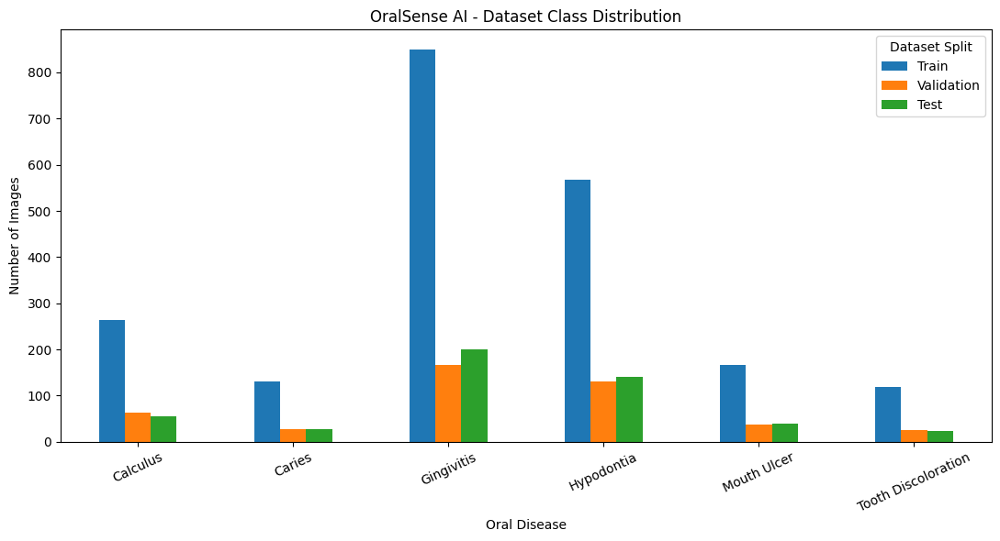

✅ Dataset distribution generated


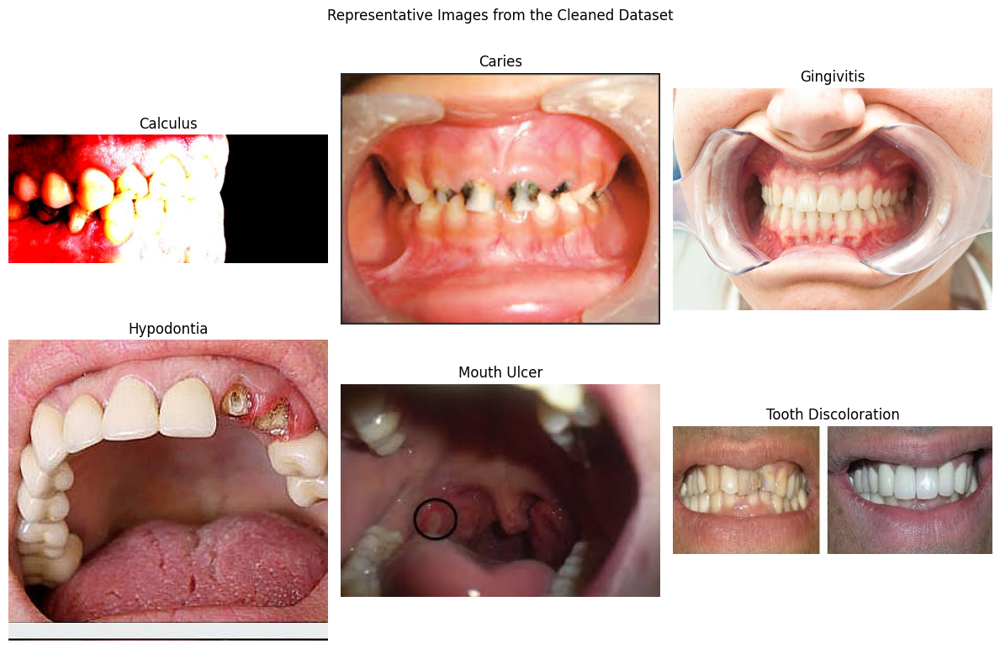

✅ Dataset sample visualization generated

EDA SUMMARY
Total cleaned images: 3031
Missing image paths: 0
Duplicate exact identifiers: 0

SIX-MODEL PERFORMANCE TABLE


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Macro_ROC_AUC,Training_Minutes
4,ConvNeXtTiny,0.9511,0.9120,0.9123,0.9119,0.9939,3.57
0,EfficientNetB0,0.9400,0.8995,0.8904,0.8940,0.9879,2.72
5,DINOv2SVM,0.9400,0.9172,0.8726,0.8922,0.9662,0.73
2,DenseNet121,0.9400,0.8994,0.8829,0.8905,0.9873,4.97
1,ResNet50,0.9356,0.8985,0.8808,0.8892,0.9868,5.47
3,MobileNetV3Large,0.9244,0.9011,0.8674,0.8823,0.9859,4.91


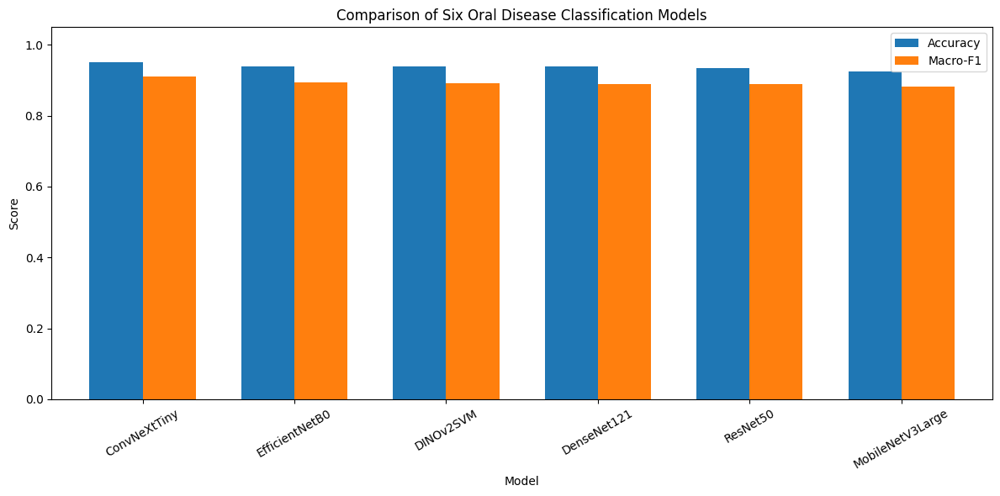

✅ Model comparison graph generated


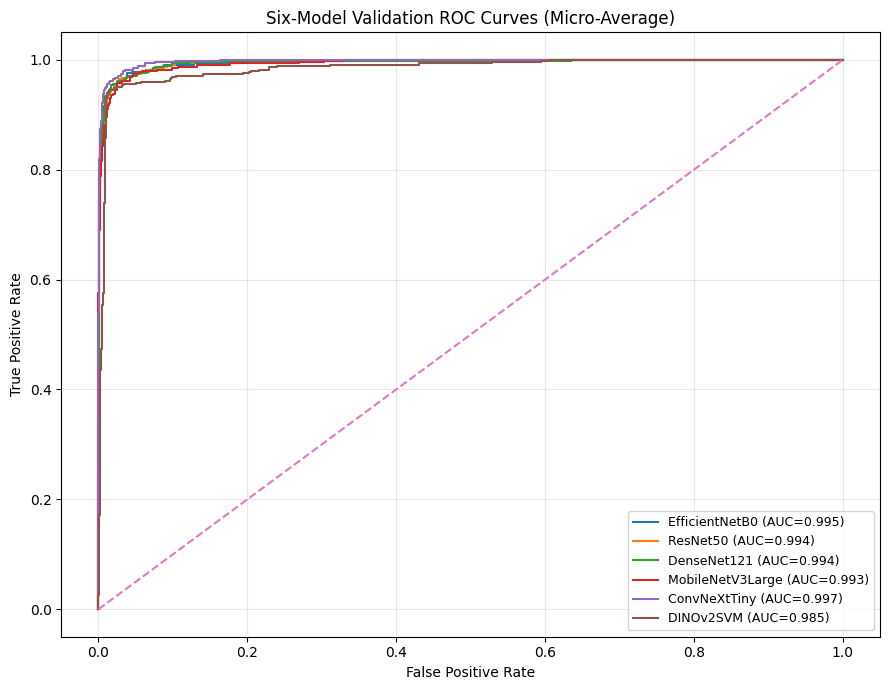

✅ Six-model ROC curves generated


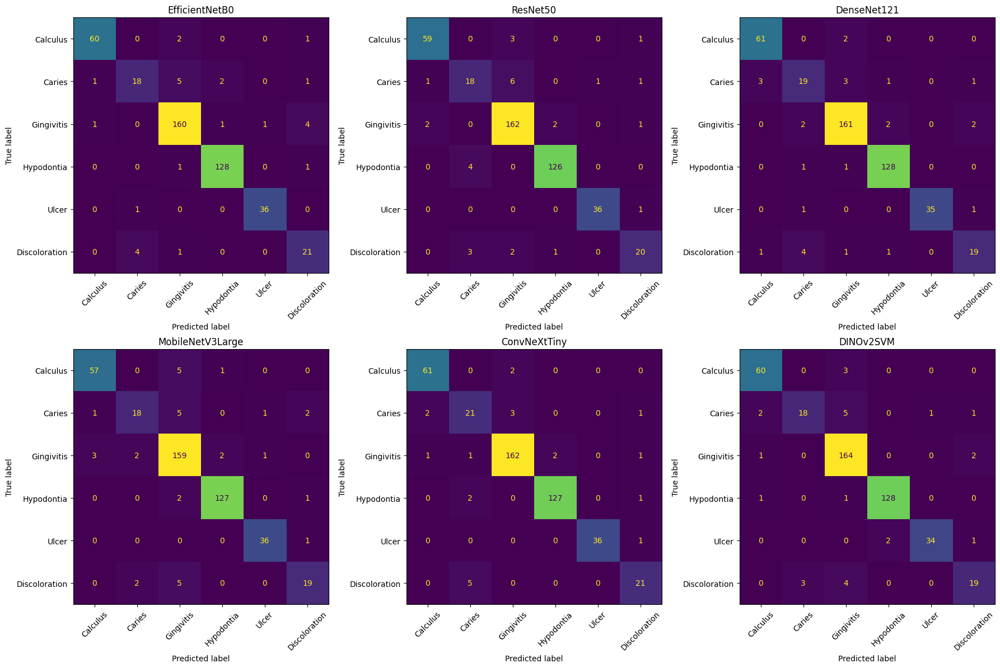

✅ All six confusion matrices generated


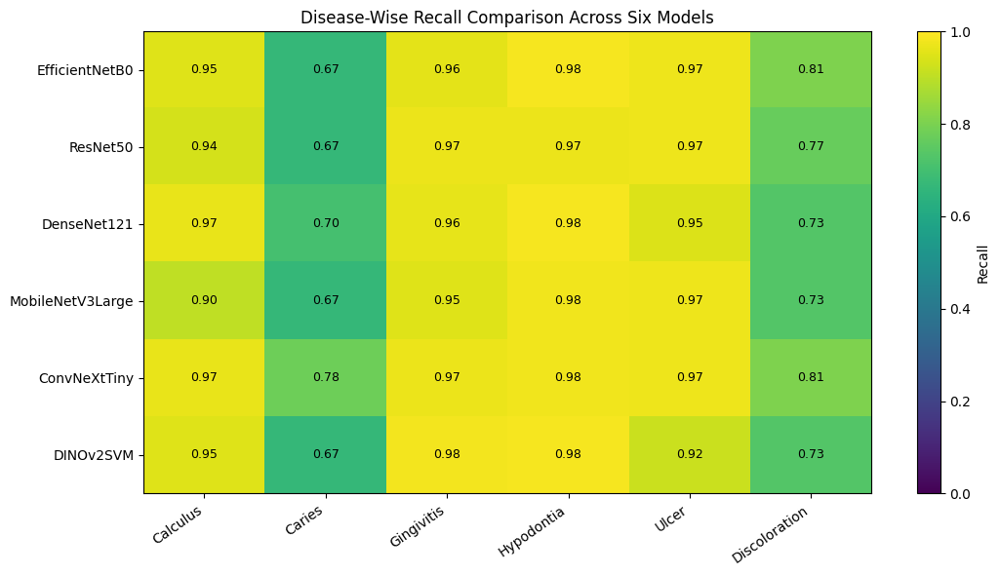

✅ Per-class recall heatmap generated


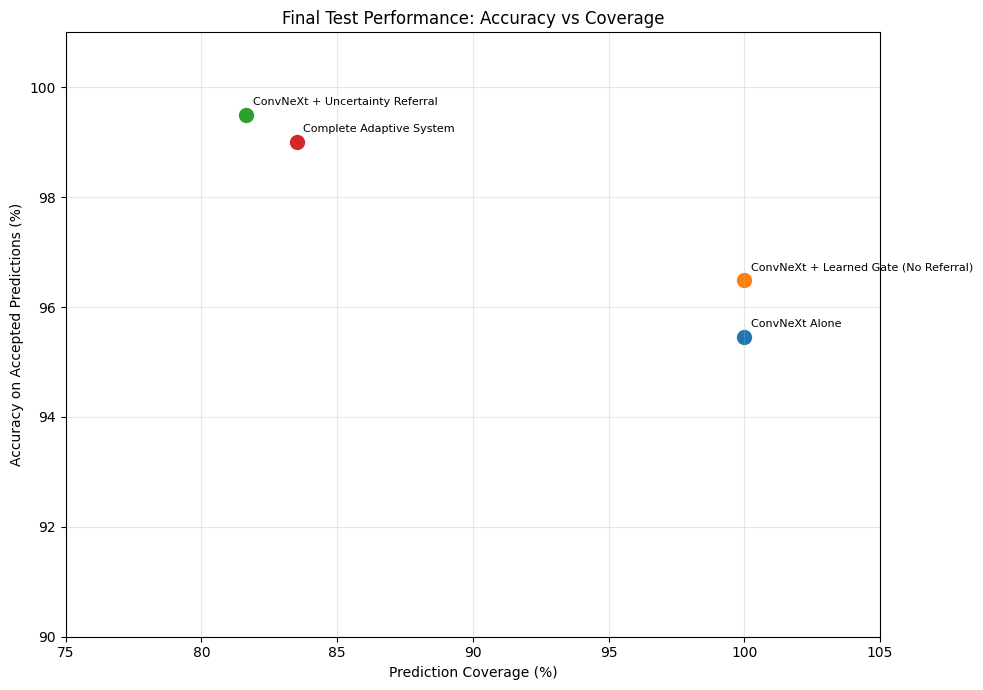

✅ Final accuracy-coverage graph generated


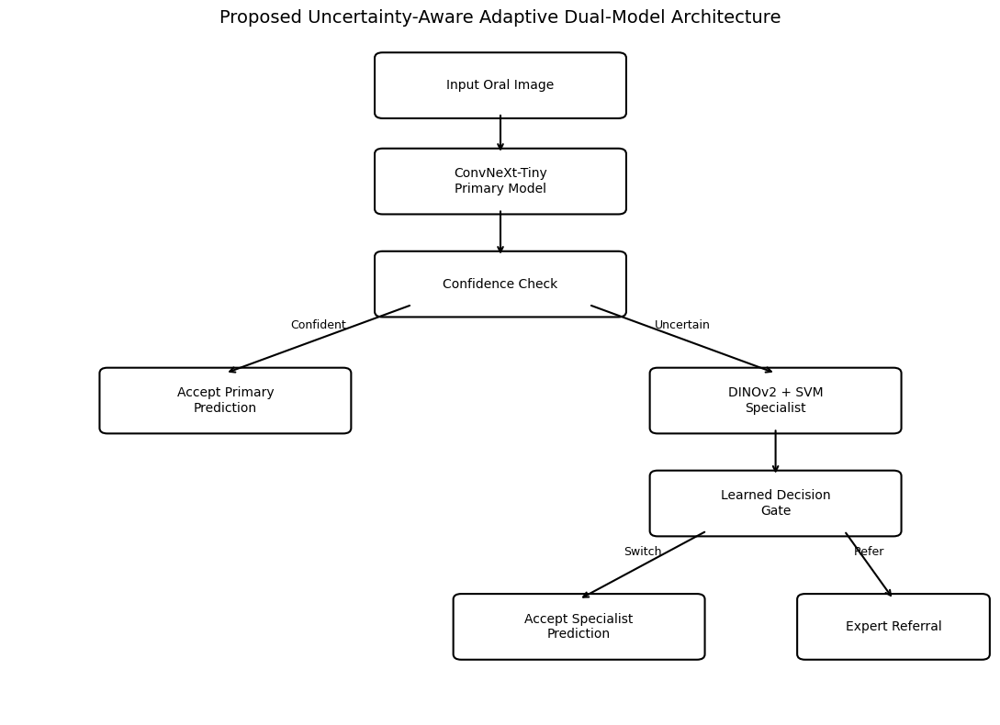

✅ Proposed architecture diagram generated

✅ Existing figures collected

✅ Report figures ZIP created

Backing up models and results...
✅ Complete model backup created

FINAL REPORT ASSETS READY
Report files: 18
Report ZIP: 17.95 MB
Model ZIP: 390.1 MB

DOWNLOAD REPORT FIGURES:


/kaggle/working/ORALSENSE_REPORT_FIGURES.zip


DOWNLOAD COMPLETE MODEL BACKUP:


/kaggle/working/ORALSENSE_COMPLETE_MODELS.zip


✅ REPORT GENERATION COMPLETED
✅ TRAINED MODELS BACKED UP
✅ FINAL TEST RESULTS PRESERVED


In [42]:
# ============================================================
# CELL 27 - FINAL MINI PROJECT REPORT ASSETS & BACKUP
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil

from pathlib import Path
from zipfile import ZipFile, ZIP_STORED, ZIP_DEFLATED
from IPython.display import display, FileLink
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    auc
)
from sklearn.preprocessing import label_binarize
from matplotlib.patches import FancyBboxPatch

print("=" * 70)
print("ORALSENSE AI - FINAL REPORT GENERATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Directories
# ------------------------------------------------------------

REPORT_DIR = RESULTS_DIR / "report_figures"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODELS = [
    "EfficientNetB0",
    "ResNet50",
    "DenseNet121",
    "MobileNetV3Large",
    "ConvNeXtTiny",
    "DINOv2SVM"
]

SHORT_CLASSES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Ulcer",
    "Discoloration"
]

PROB_COLS = [
    f"prob_{i}"
    for i in range(NUM_CLASSES)
]

# ------------------------------------------------------------
# 2. Load predictions
# ------------------------------------------------------------

predictions = {}

for name in MODELS:

    df = pd.read_csv(
        RESULTS_DIR / f"{name}_val_predictions.csv"
    )

    assert np.array_equal(
        df["image_path"].astype(str).to_numpy(),
        val_df["image_path"].astype(str).to_numpy()
    )

    predictions[name] = df

y_true = predictions[MODELS[0]]["true_label"].to_numpy()

print("\n✅ All six validation prediction files loaded")

# ------------------------------------------------------------
# 3. FIGURE 1 - Dataset Class Distribution
# ------------------------------------------------------------

counts = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).reindex(CLASS_NAMES).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(11, 6))

counts.plot(
    kind="bar",
    ax=ax
)

ax.set_title("OralSense AI - Dataset Class Distribution")
ax.set_xlabel("Oral Disease")
ax.set_ylabel("Number of Images")
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Dataset Split")

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "01_Dataset_Class_Distribution.png",
    dpi=300
)

plt.show()

counts.to_csv(
    REPORT_DIR / "Dataset_Class_Counts.csv"
)

print("✅ Dataset distribution generated")

# ------------------------------------------------------------
# 4. FIGURE 2 - Sample Images from Six Classes
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 8)
)

axes = axes.flatten()

for i, class_name in enumerate(CLASS_NAMES):

    sample = train_df[
        train_df["class_name"] == class_name
    ].iloc[0]

    with Image.open(sample["image_path"]) as img:
        axes[i].imshow(img.convert("RGB"))

    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.suptitle(
    "Representative Images from the Cleaned Dataset"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "02_Dataset_Sample_Images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Dataset sample visualization generated")

# ------------------------------------------------------------
# 5. Missing Values and Duplicate Verification
# ------------------------------------------------------------

complete_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

missing_df = pd.DataFrame({
    "Feature": complete_df.columns,
    "Missing Values": complete_df.isna().sum().values
})

missing_df.to_csv(
    REPORT_DIR / "EDA_Missing_Values.csv",
    index=False
)

if "sha256" in complete_df.columns:

    duplicate_count = complete_df[
        "sha256"
    ].duplicated().sum()

else:

    duplicate_count = complete_df[
        "image_path"
    ].duplicated().sum()

print("\nEDA SUMMARY")
print("Total cleaned images:", len(complete_df))
print("Missing image paths:",
      complete_df["image_path"].isna().sum())
print("Duplicate exact identifiers:", duplicate_count)

# ------------------------------------------------------------
# 6. Calculate Six-Model Evaluation Metrics
# ------------------------------------------------------------

comparison = pd.read_csv(
    RESULTS_DIR / "model_comparison.csv"
)

metrics = []

for name in MODELS:

    df = predictions[name]

    y_pred = df["predicted_label"].to_numpy()

    probs = df[PROB_COLS].to_numpy()

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        )
    )

    macro_auc = roc_auc_score(
        y_true,
        probs,
        average="macro",
        multi_class="ovr",
        labels=np.arange(NUM_CLASSES)
    )

    saved = comparison[
        comparison["Model"] == name
    ].iloc[0]

    metrics.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_Precision": precision,
        "Macro_Recall": recall,
        "Macro_F1": f1,
        "Macro_ROC_AUC": macro_auc,
        "Training_Minutes": saved["Training_Minutes"]
    })

metrics_df = pd.DataFrame(metrics).sort_values(
    "Macro_F1",
    ascending=False
)

metrics_df.to_csv(
    REPORT_DIR / "Six_Model_Report_Metrics.csv",
    index=False
)

print("\nSIX-MODEL PERFORMANCE TABLE")
display(metrics_df.round(4))

# ------------------------------------------------------------
# 7. FIGURE 3 - Model Comparison Bar Chart
# ------------------------------------------------------------

plot_df = metrics_df.set_index("Model")[
    ["Accuracy", "Macro_F1"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.7
)

ax.set_title(
    "Comparison of Six Oral Disease Classification Models"
)

ax.set_ylabel("Score")
ax.set_xlabel("Model")

ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=30)
ax.legend(["Accuracy", "Macro-F1"])

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "03_Six_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Model comparison graph generated")

# ------------------------------------------------------------
# 8. FIGURE 4 - ROC Curves for Six Models
# ------------------------------------------------------------

y_binary = label_binarize(
    y_true,
    classes=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(9, 7))

for name in MODELS:

    probs = predictions[name][
        PROB_COLS
    ].to_numpy()

    # Micro-averaged one-vs-rest ROC
    fpr, tpr, _ = roc_curve(
        y_binary.ravel(),
        probs.ravel()
    )

    roc_area = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={roc_area:.3f})"
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

ax.set_title(
    "Six-Model Validation ROC Curves (Micro-Average)"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "04_Six_Model_ROC_Curves.png",
    dpi=300
)

plt.show()

print("✅ Six-model ROC curves generated")

# ------------------------------------------------------------
# 9. FIGURE 5 - Confusion Matrices for All Six Models
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 12)
)

for ax, name in zip(axes.flat, MODELS):

    df = predictions[name]

    cm = confusion_matrix(
        y_true,
        df["predicted_label"],
        labels=np.arange(NUM_CLASSES)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=SHORT_CLASSES
    )

    disp.plot(
        ax=ax,
        colorbar=False,
        values_format="d",
        xticks_rotation=45
    )

    ax.set_title(name)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "05_All_Six_Confusion_Matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ All six confusion matrices generated")

# ------------------------------------------------------------
# 10. FIGURE 6 - Class-Wise Recall Heatmap
# ------------------------------------------------------------

recall_matrix = []

for name in MODELS:

    df = predictions[name]

    _, recalls, _, _ = (
        precision_recall_fscore_support(
            y_true,
            df["predicted_label"],
            labels=np.arange(NUM_CLASSES),
            zero_division=0
        )
    )

    recall_matrix.append(recalls)

recall_matrix = np.array(recall_matrix)

fig, ax = plt.subplots(figsize=(11, 6))

im = ax.imshow(
    recall_matrix,
    aspect="auto",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(NUM_CLASSES))
ax.set_xticklabels(
    SHORT_CLASSES,
    rotation=35,
    ha="right"
)

ax.set_yticks(range(len(MODELS)))
ax.set_yticklabels(MODELS)

for i in range(len(MODELS)):
    for j in range(NUM_CLASSES):

        ax.text(
            j, i,
            f"{recall_matrix[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9
        )

fig.colorbar(
    im,
    ax=ax,
    label="Recall"
)

ax.set_title(
    "Disease-Wise Recall Comparison Across Six Models"
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "06_Per_Class_Recall_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Per-class recall heatmap generated")

# ------------------------------------------------------------
# 11. FIGURE 7 - Final Accuracy vs Coverage
# ------------------------------------------------------------

test_comparison = pd.read_csv(
    RESULTS_DIR / "FINAL_Test_Performance_Comparison.csv"
)

fig, ax = plt.subplots(figsize=(10, 7))

for _, row in test_comparison.iterrows():

    ax.scatter(
        row["Coverage (%)"],
        row["Accuracy (%)"],
        s=100
    )

    ax.annotate(
        row["System"],
        (
            row["Coverage (%)"],
            row["Accuracy (%)"]
        ),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title(
    "Final Test Performance: Accuracy vs Coverage"
)

ax.set_xlabel("Prediction Coverage (%)")
ax.set_ylabel("Accuracy on Accepted Predictions (%)")

ax.set_xlim(75, 105)
ax.set_ylim(90, 101)
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "07_Final_Test_Accuracy_vs_Coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Final accuracy-coverage graph generated")

# ------------------------------------------------------------
# 12. FIGURE 8 - Proposed System Architecture
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

def add_box(x, y, text, width=2.4):

    box = FancyBboxPatch(
        (x - width/2, y - 0.4),
        width,
        0.8,
        boxstyle="round,pad=0.08",
        fill=False,
        linewidth=1.5
    )

    ax.add_patch(box)

    ax.text(
        x, y, text,
        ha="center",
        va="center",
        fontsize=10
    )

def arrow(x1, y1, x2, y2, text=None):

    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            linewidth=1.5
        )
    )

    if text:
        ax.text(
            (x1+x2)/2,
            (y1+y2)/2+0.15,
            text,
            fontsize=9,
            ha="center"
        )

add_box(5, 9.2, "Input Oral Image")
add_box(5, 7.8, "ConvNeXt-Tiny\nPrimary Model")
add_box(5, 6.3, "Confidence Check")
add_box(2.2, 4.6, "Accept Primary\nPrediction")
add_box(7.8, 4.6, "DINOv2 + SVM\nSpecialist")
add_box(7.8, 3.1, "Learned Decision\nGate")
add_box(5.8, 1.3, "Accept Specialist\nPrediction")
add_box(9, 1.3, "Expert Referral", width=1.8)

arrow(5, 8.8, 5, 8.2)
arrow(5, 7.4, 5, 6.7)

arrow(4.1, 6.0, 2.2, 5.0, "Confident")
arrow(5.9, 6.0, 7.8, 5.0, "Uncertain")

arrow(7.8, 4.2, 7.8, 3.5)

arrow(7.1, 2.7, 5.8, 1.7, "Switch")
arrow(8.5, 2.7, 9, 1.7, "Refer")

ax.set_title(
    "Proposed Uncertainty-Aware Adaptive Dual-Model Architecture",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    REPORT_DIR / "08_Proposed_System_Architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Proposed architecture diagram generated")

# ------------------------------------------------------------
# 13. Collect Already-Generated Figures
# ------------------------------------------------------------

existing_figures = [
    "CNN_training_validation_curves.png",
    "ConvNeXtTiny_Confusion_Matrix.png",
    "ConvNeXt_GradCAM_Analysis.png",
    "ConvNeXt_Occlusion_Sensitivity.png",
    "ConvNeXt_22_Validation_Errors.png",
    "ConvNeXt_vs_DINOv2_Confusion.png"
]

for filename in existing_figures:

    source = RESULTS_DIR / filename

    if source.exists():

        shutil.copy2(
            source,
            REPORT_DIR / filename
        )

print("\n✅ Existing figures collected")

# ------------------------------------------------------------
# 14. Create Figure Caption Guide
# ------------------------------------------------------------

captions = {

    "01_Dataset_Class_Distribution.png":
        "Class distribution across training, validation and test sets.",

    "02_Dataset_Sample_Images.png":
        "Representative images of the six oral disease classes.",

    "03_Six_Model_Comparison.png":
        "Validation accuracy and Macro-F1 comparison of six models.",

    "04_Six_Model_ROC_Curves.png":
        "Micro-averaged one-vs-rest ROC curves on validation data.",

    "05_All_Six_Confusion_Matrices.png":
        "Validation confusion matrices for six classification models.",

    "06_Per_Class_Recall_Heatmap.png":
        "Per-class validation recall comparison of six models.",

    "07_Final_Test_Accuracy_vs_Coverage.png":
        "Final held-out test accuracy and prediction coverage trade-off.",

    "08_Proposed_System_Architecture.png":
        "Architecture of the uncertainty-aware adaptive classification system.",

    "CNN_training_validation_curves.png":
        "Training and validation learning curves for five CNN models.",

    "ConvNeXt_GradCAM_Analysis.png":
        "Grad-CAM analysis of selected ConvNeXt predictions.",

    "ConvNeXt_Occlusion_Sensitivity.png":
        "Occlusion sensitivity analysis of selected ConvNeXt predictions."
}

caption_df = pd.DataFrame([
    {"Figure": name, "Suggested Caption": caption}
    for name, caption in captions.items()
    if (REPORT_DIR / name).exists()
])

caption_df.to_csv(
    REPORT_DIR / "Figure_Caption_Guide.csv",
    index=False
)

# ------------------------------------------------------------
# 15. Create Report Figures ZIP
# ------------------------------------------------------------

FIGURE_ZIP = Path(
    "/kaggle/working/ORALSENSE_REPORT_FIGURES.zip"
)

with ZipFile(
    FIGURE_ZIP,
    "w",
    ZIP_DEFLATED
) as archive:

    for file in REPORT_DIR.rglob("*"):

        if file.is_file():

            archive.write(
                file,
                arcname=file.relative_to(REPORT_DIR)
            )

print("\n✅ Report figures ZIP created")

# ------------------------------------------------------------
# 16. Back Up Trained Models and Experimental Results
# ------------------------------------------------------------

MODEL_ZIP = Path(
    "/kaggle/working/ORALSENSE_COMPLETE_MODELS.zip"
)

essential = [
    "ConvNeXtTiny_best.pth",
    "DINOv2SVM_best.joblib",
    "Adaptive_Decision_Gate.joblib",
    "OralSense_Adaptive_Policy.joblib",
    "FINAL_Test_Performance_Comparison.csv"
]

for name in essential:

    assert (RESULTS_DIR / name).exists(), (
        f"Missing essential result: {name}"
    )

DINO_WEIGHTS = Path(
    "/root/.cache/torch/hub/checkpoints/"
    "dinov2_vits14_pretrain.pth"
)

assert DINO_WEIGHTS.exists(), (
    "DINOv2 pretrained weights not found in cache."
)

DINO_SOURCE = Path(
    "/root/.cache/torch/hub/"
    "facebookresearch_dinov2_main"
)

assert DINO_SOURCE.exists(), (
    "DINOv2 source not found in cache."
)

print("\nBacking up models and results...")

with ZipFile(
    MODEL_ZIP,
    "w",
    ZIP_STORED
) as archive:

    for file in RESULTS_DIR.rglob("*"):

        if file.is_file():

            archive.write(
                file,
                arcname=(
                    "results/" +
                    file.relative_to(RESULTS_DIR).as_posix()
                )
            )

    archive.write(
        DINO_WEIGHTS,
        arcname="pretrained_weights/dinov2_vits14_pretrain.pth"
    )

    for file in DINO_SOURCE.rglob("*"):

        if file.is_file() and "__pycache__" not in file.parts:

            archive.write(
                file,
                arcname=(
                    "dinov2_hub_source/" +
                    file.relative_to(DINO_SOURCE).as_posix()
                )
            )

print("✅ Complete model backup created")

# ------------------------------------------------------------
# 17. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL REPORT ASSETS READY")
print("=" * 70)

print("Report files:", len(list(REPORT_DIR.iterdir())))

print(
    "Report ZIP:",
    round(FIGURE_ZIP.stat().st_size / 1024**2, 2),
    "MB"
)

print(
    "Model ZIP:",
    round(MODEL_ZIP.stat().st_size / 1024**2, 2),
    "MB"
)

print("\nDOWNLOAD REPORT FIGURES:")
display(FileLink(str(FIGURE_ZIP)))

print("\nDOWNLOAD COMPLETE MODEL BACKUP:")
display(FileLink(str(MODEL_ZIP)))

print("\n✅ REPORT GENERATION COMPLETED")
print("✅ TRAINED MODELS BACKED UP")
print("✅ FINAL TEST RESULTS PRESERVED")